<a href="https://colab.research.google.com/github/agduyaguit/dsp-final-project-tirc-notebook/blob/master/Typhoon_Impact_MSDS_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Philippine Province-Level Typhoon Impact-Risk Classification
## End-to-end research notebook | XGBoost · GRU · ResNet-18 · Multimodal Fusion

**Research question:** Can historical typhoon track, exposure, and vulnerability information classify the severity of observed impacts at the Philippine province and storm level?

**Read first:** This notebook records a retrospective research experiment, not an operational forecasting system. The saved outputs predate the expanded weather, terrain, poverty and housing features; rerun the notebook before interpreting them as expanded-model results. The saved run uses  Digital Typhoon matches, UTC image timestamps and interpolated first-landfall anchors; The test split has previously been inspected, so its comparisons are exploratory. Historical best-track records do not establish real-time data availability.

**Workflow:** 0 configuration → 1 source audits & EDA → 2 matching and cutoff → 3 storm-group splits and outcome labels → 4 features → 5 XGBoost → 6 GRU → 7 ResNet-18 → 8 fusion and tuning → 9 evaluation → 10 export.


In [ ]:
# 0.1 Install only what's required for this Colab runtime
%pip -q install xgboost geopandas rasterio pyogrio seaborn scikit-learn torchvision pillow tqdm openpyxl

In [ ]:
# 0.2 Imports, repeatable seeds, working folders
import os, re, io, json, math, random, warnings, glob, zipfile, shutil
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, ParameterGrid
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
    roc_curve,
    roc_auc_score,
    auc,
    precision_recall_curve,
    brier_score_loss,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import joblib
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from tqdm.auto import tqdm
import xgboost as xgb

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [ ]:
# 0.3 Mount Drive in Colab or use a local project folder
PROJECT_FOLDER = "dsp_final_project"
try:
    from google.colab import drive
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    drive = None

IN_COLAB = drive is not None
if IN_COLAB:
    drive.mount("/content/drive")
    ROOT_CANDIDATES = list(Path("/content/drive/MyDrive").rglob(PROJECT_FOLDER))
    assert ROOT_CANDIDATES, (
        "Project folder not located in Google Drive: change PROJECT_FOLDER or mount the correct account."
    )
    ROOT = ROOT_CANDIDATES[0]
    OUT = Path("/content/typhoon_research_outputs")
else:
    ROOT = Path.cwd()
    if (ROOT / PROJECT_FOLDER).is_dir():
        ROOT = ROOT / PROJECT_FOLDER
    OUT = Path.cwd() / "typhoon_research_outputs"
    print(
        "Google Colab is unavailable; using the local project folder. Set ROOT to your data directory if needed."
    )

OUT.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT, "\nOUT:", OUT)
for folder in [
    "impact",
    "ibtracs",
    "nasa_power",
    "gadm",
    "srtm",
    "psa_census",
    "psa_poverty",
    "psa_housing",
    "dtd",
    "pagasa",
]:
    print(f"{folder:14}", "exists" if (ROOT / folder).exists() else "MISSING")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project 
OUT: /content/typhoon_research_outputs
impact         exists
ibtracs        exists
nasa_power     exists
gadm           exists
srtm           exists
psa_census     exists
psa_poverty    exists
psa_housing    exists
dtd            exists
pagasa         exists


In [ ]:
# 0.4 Experiment controls, deliberately centralised
CFG = dict(
    train_frac=0.65,
    val_frac=0.20,
    test_frac=0.15,
    label_quantiles=(0.33, 0.67),
    horizon_hours=24,
    sequence_steps=12,
    batch_size=32,
    epochs=20,
    patience=5,
    learning_rate=2e-4,
    weight_decay=1e-4,
    dropout=0.25,
    image_size=224,
    max_images_per_event=3,
    fusion_hidden=128,
    zero_is_missing=False,
    max_gap_days=14,
    impact_weights={"affected": 0.25, "houses": 0.25, "deaths": 0.25, "economic": 0.25},
    save_figures=True,
)

CLASSES = ["Low", "Moderate", "High"]


def plot_finish(name):
    plt.tight_layout()
    if CFG["save_figures"]:
        plt.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

## 1. Source inventory and raw exploratory analysis

**Verified folder contents:** `impact/Impact_Data.csv`; `ibtracs/ibtracs.WP.list.v04r01.csv`; `nasa_power/power_*.csv` and `province_centroids.csv`; `gadm/gadm41_PHL.gpkg`; `srtm/Copernicus_DSM_*.tif`; `psa_census/census_population_2000_2015.csv` and `census_population_2020.csv`; `psa_poverty/poverty_incidence_population.csv`; `psa_housing/housing_roof_wall_census2020.xlsx`; `dtd/V3-2025.R2-WP-1.zip` (~63GB).

**Source-use policy:** impact = outcomes only; IBTrACS = storm hazard sequence; POWER = retrospective pre-cutoff meteorology; GADM = boundary geometry; census = exposure; terrain = retrospective geographic proxy; poverty = retrospective 2015/2018 proxy; housing = retrospective 2020 census proxy; DTD = satellite images with assumed matching. Poverty, housing and other retrospective inputs are not verified as operationally available at the cutoff.

In [ ]:
# 1.1 Inventory: size and file counts, never open the entire 63GB archive in RAM
source_dirs = [
    "impact",
    "ibtracs",
    "nasa_power",
    "gadm",
    "srtm",
    "psa_census",
    "psa_poverty",
    "psa_housing",
    "dtd",
]
inv = []
for d in source_dirs:
    for p in (ROOT / d).glob("*"):
        if p.is_file():
            inv.append(
                {
                    "source": d,
                    "file": p.name,
                    "size_mb": round(p.stat().st_size / 1e6, 2),
                }
            )
inventory = pd.DataFrame(inv)
display(
    inventory.groupby("source", as_index=False).agg(
        n_files=("file", "count"), size_mb=("size_mb", "sum")
    )
)
display(inventory.sort_values("size_mb", ascending=False).head(12))

,source,n_files,size_mb
0,dtd,15,63505.86
1,gadm,2,75.74
2,ibtracs,3,443.63
3,impact,2,0.10
4,nasa_power,83,20.25
5,psa_census,2,0.02
6,psa_housing,3,1.80
7,psa_poverty,6,0.13
8,srtm,106,1449.27


,source,file,size_mb
211,dtd,V3-2025.R2-WP-1.zip,63368.85
2,ibtracs,ibtracs.ALL.list.v04r01.csv,329.58
4,ibtracs,ibtracs.WP.list.v04r01.csv,114.05
89,gadm,gadm41_PHL.gpkg,75.74
98,srtm,Copernicus_DSM_COG_10_N05_00_E117_00_DEM.tif,50.30
176,srtm,Copernicus_DSM_COG_10_N15_00_E120_00_DEM.tif,48.17
184,srtm,Copernicus_DSM_COG_10_N17_00_E121_00_DEM.tif,47.98
130,srtm,Copernicus_DSM_COG_10_N08_00_E125_00_DEM.tif,47.91
97,srtm,Copernicus_DSM_COG_10_N05_00_E116_00_DEM.tif,47.33
91,srtm,Copernicus_DSM_COG_10_N04_00_E117_00_DEM.tif,46.01


In [ ]:
# 1.2 Load observed outcomes and preserve unknown vs confirmed zero
imp = pd.read_csv(ROOT / "impact/Impact_Data.csv")
imp.columns = imp.columns.str.strip()
rename = {
    "Cyclone Name": "storm_name",
    "Province": "province",
    "Deaths": "deaths",
    "Affected": "affected",
    "Houses destroyed": "houses_destroyed",
    "Houses damaged": "houses_damaged",
    "Total Houses": "total_houses",
    "Damage to Infrastructure (PhP)": "infrastructure_php",
    "Damage to Agriculture + Fisheries (PhP)": "agriculture_php",
    "Year": "year",
    "Category": "category",
}
imp = imp.rename(columns=rename)
for c in [
    "deaths",
    "affected",
    "houses_destroyed",
    "houses_damaged",
    "total_houses",
    "infrastructure_php",
    "agriculture_php",
]:
    imp[c] = pd.to_numeric(imp[c], errors="coerce")
imp["year"] = pd.to_numeric(imp["year"], errors="coerce").astype("Int64")
imp["economic_php"] = imp["infrastructure_php"] + imp["agriculture_php"]
imp["housing_count"] = imp["houses_destroyed"] + imp["houses_damaged"]
imp["storm_key"] = (
    imp["storm_name"].str.lower().str.strip() + "_" + imp["year"].astype(str)
)
print(
    "Dimensions:",
    imp.shape,
    "Storms:",
    imp.storm_key.nunique(),
    "Provinces:",
    imp.province.nunique(),
)
display(imp.head())
display(imp.isna().sum().to_frame("missing"))
print("Exact duplicate rows:", imp.duplicated().sum())
print(
    "Duplicate storm × province keys:", imp.duplicated(["storm_key", "province"]).sum()
)

Dimensions: (1266, 14) Storms: 85 Provinces: 80


,storm_name,province,deaths,affected,houses_destroyed,houses_damaged,total_houses,infrastructure_php,agriculture_php,year,category,economic_php,housing_count,storm_key
0,Conson,Metro Manila,2.0,2802.0,62.0,0.0,62,1705000.0,0.0,2010,Strong typhoon,1705000.0,62.0,conson_2010
1,Conson,Aurora,0.0,187.0,0.0,0.0,0,19300000.0,0.0,2010,Strong typhoon,19300000.0,0.0,conson_2010
2,Conson,Bataan,10.0,68692.0,232.0,2695.0,2927,4950000.0,579332.0,2010,Strong typhoon,5529332.0,2927.0,conson_2010
3,Conson,Bulacan,3.0,189.0,0.0,0.0,0,23761000.0,0.0,2010,Strong typhoon,23761000.0,0.0,conson_2010
4,Conson,Pampanga,0.0,221.0,0.0,0.0,0,0.0,0.0,2010,Strong typhoon,0.0,0.0,conson_2010


,missing
storm_name,0
province,0
deaths,0
affected,0
houses_destroyed,0
houses_damaged,0
total_houses,0
infrastructure_php,0
agriculture_php,0
year,0


Exact duplicate rows: 0
Duplicate storm × province keys: 5


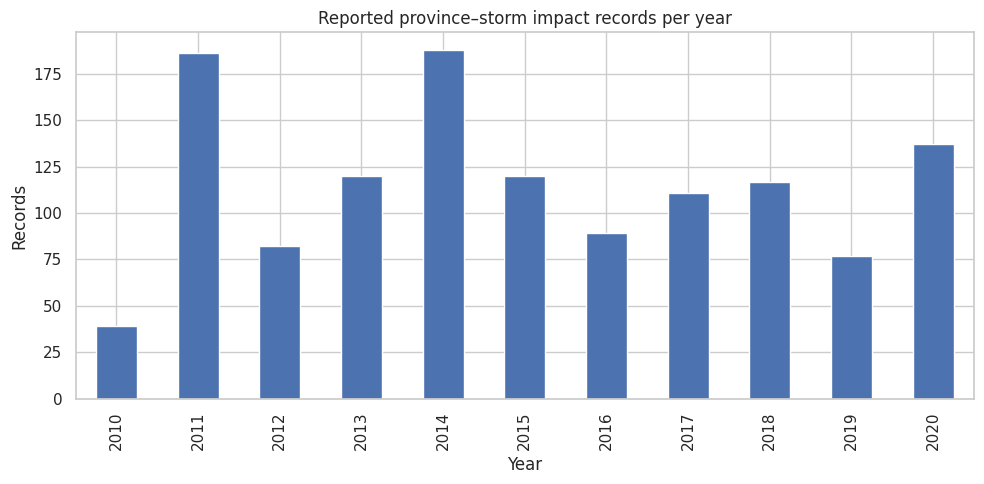

In [ ]:
# 1.3 Figure: observed impact records by year
fig, ax = plt.subplots(figsize=(10, 5))
imp.groupby("year").size().plot(kind="bar", ax=ax)
ax.set(
    title="Reported province–storm impact records per year",
    xlabel="Year",
    ylabel="Records",
)
plot_finish("01_impact_records_by_year")

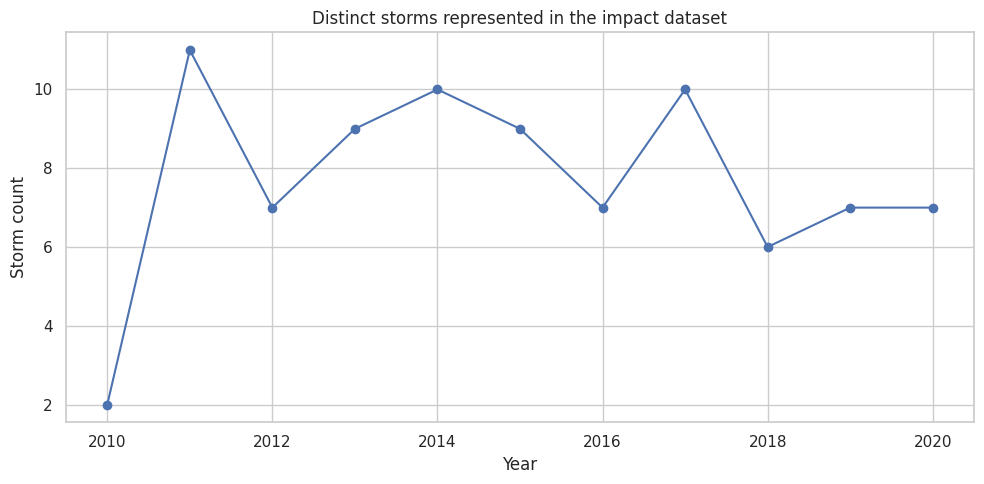

In [ ]:
# 1.4 Figure: storms per year (not equal to basin-wide cyclone count)
fig, ax = plt.subplots(figsize=(10, 5))
imp.groupby("year").storm_key.nunique().plot(marker="o", ax=ax)
ax.set(
    title="Distinct storms represented in the impact dataset",
    xlabel="Year",
    ylabel="Storm count",
)
plot_finish("02_impact_storms_year")

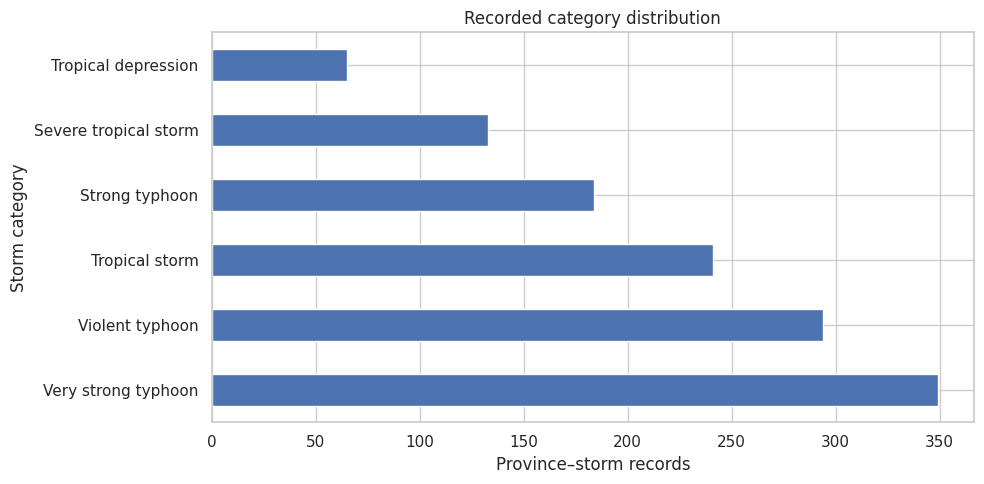

In [ ]:
# 1.5 Figure: category distribution
fig, ax = plt.subplots(figsize=(10, 5))
imp.category.value_counts().plot(kind="barh", ax=ax)
ax.set(
    title="Recorded category distribution",
    xlabel="Province–storm records",
    ylabel="Storm category",
)
plot_finish("03_category_counts")

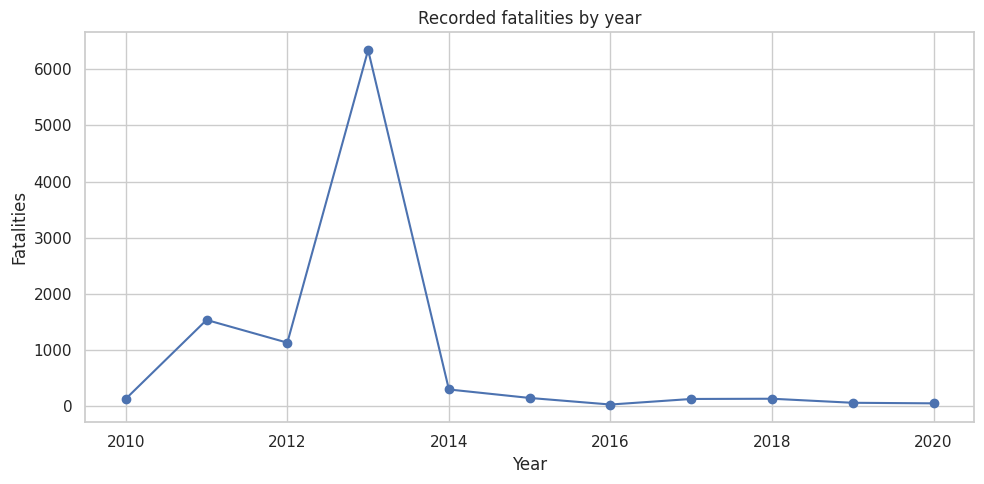

In [ ]:
# 1.6 Figure: annual fatalities
fig, ax = plt.subplots(figsize=(10, 5))
imp.groupby("year").deaths.sum(min_count=1).plot(marker="o", ax=ax)
ax.set(title="Recorded fatalities by year", xlabel="Year", ylabel="Fatalities")
plot_finish("04_deaths_by_year")

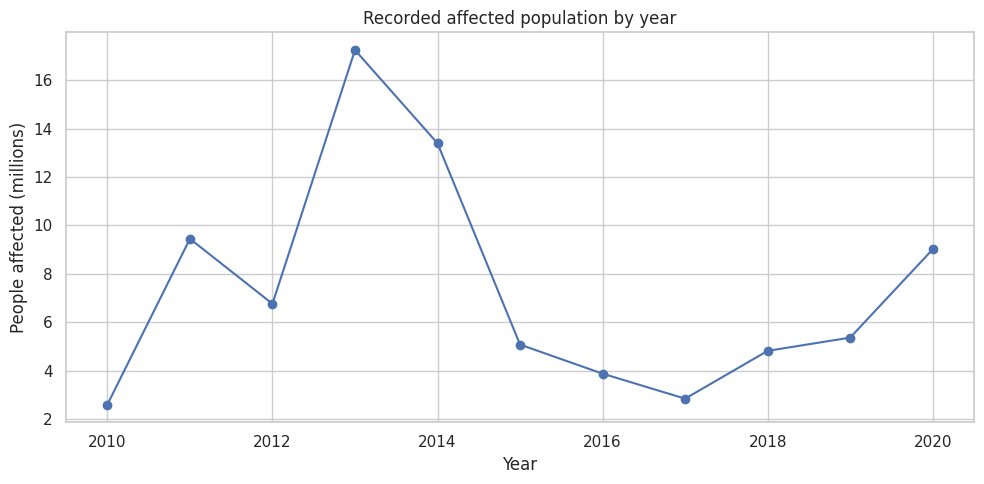

In [ ]:
# 1.7 Figure: annual affected population
fig, ax = plt.subplots(figsize=(10, 5))
(imp.groupby("year").affected.sum(min_count=1) / 1e6).plot(marker="o", ax=ax)
ax.set(
    title="Recorded affected population by year",
    xlabel="Year",
    ylabel="People affected (millions)",
)
plot_finish("05_affected_by_year")

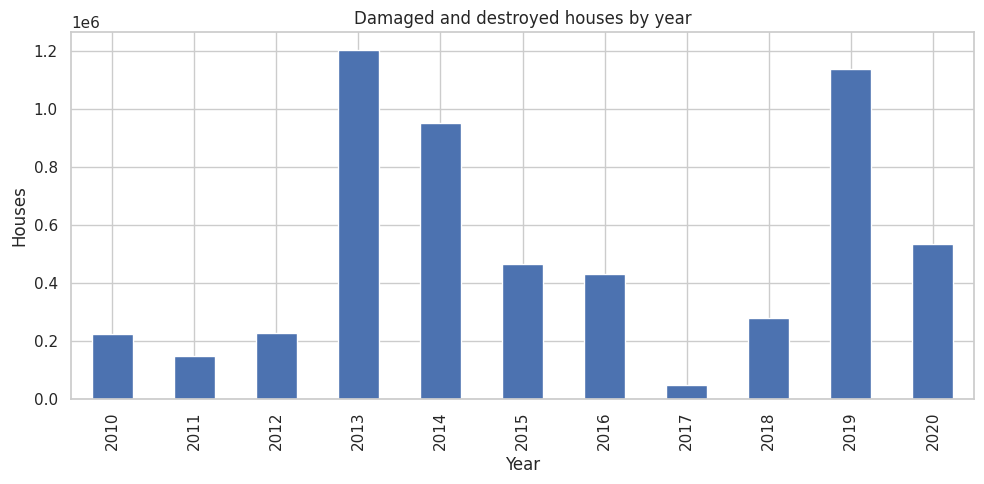

In [ ]:
# 1.8 Figure: housing impact by year
fig, ax = plt.subplots(figsize=(10, 5))
imp.groupby("year").housing_count.sum(min_count=1).plot(kind="bar", ax=ax)
ax.set(title="Damaged and destroyed houses by year", xlabel="Year", ylabel="Houses")
plot_finish("06_housing_by_year")

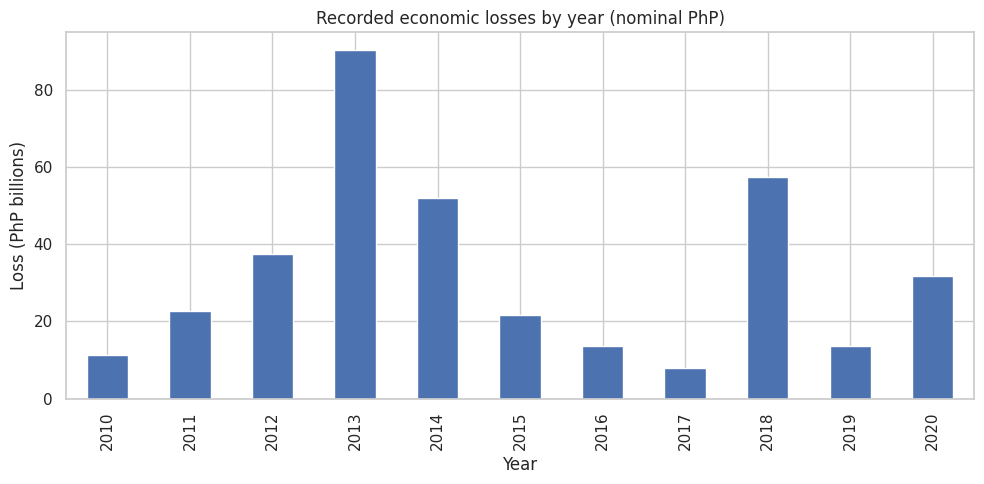

In [ ]:
# 1.9 Figure: reported economic losses; nominal PhP, NOT inflation-adjusted
fig, ax = plt.subplots(figsize=(10, 5))
(imp.groupby("year").economic_php.sum(min_count=1) / 1e9).plot(kind="bar", ax=ax)
ax.set(
    title="Recorded economic losses by year (nominal PhP)",
    xlabel="Year",
    ylabel="Loss (PhP billions)",
)
plot_finish("07_loss_by_year")

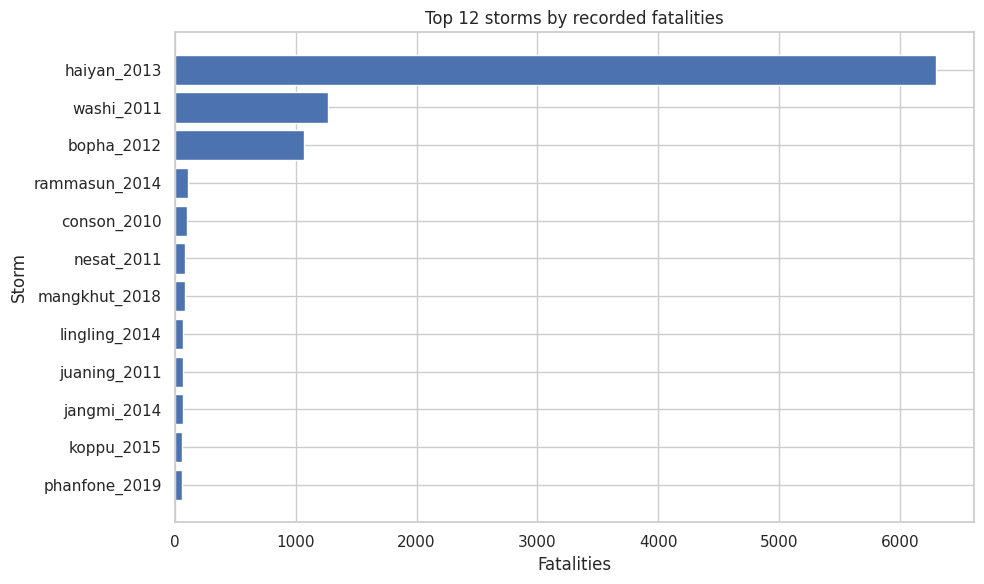

In [ ]:
# 1.10 Figure: top storms by fatalities
storm_agg = imp.groupby(["storm_key", "storm_name", "year"], as_index=False)[
    ["deaths", "affected", "housing_count", "economic_php"]
].sum(min_count=1)
top = storm_agg.nlargest(12, "deaths").sort_values("deaths")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.storm_key, top.deaths)
ax.set(
    title="Top 12 storms by recorded fatalities", xlabel="Fatalities", ylabel="Storm"
)
plot_finish("08_deadliest_storms")

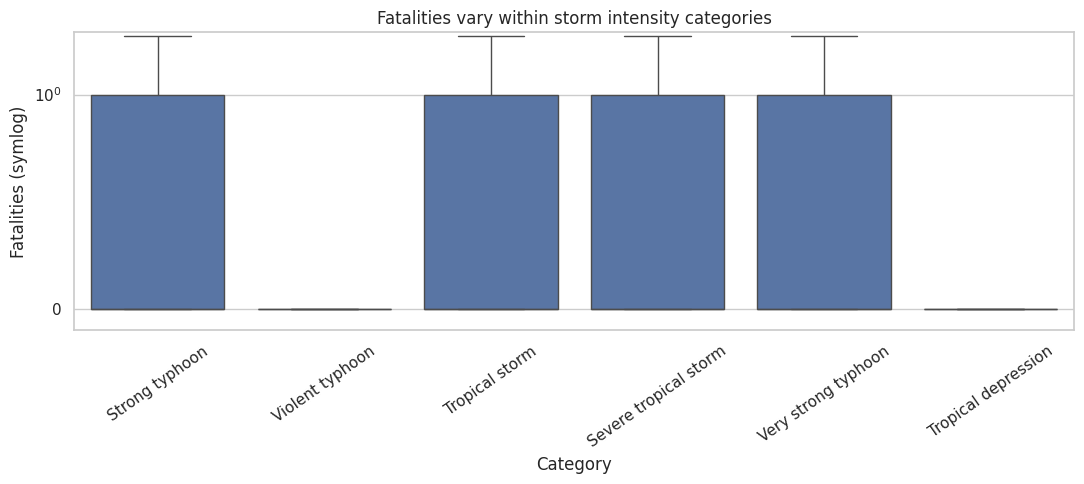

In [ ]:
# 1.11 Figure: same category, different outcomes (log scale preserves broad spread)
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=imp, x="category", y="deaths", ax=ax, showfliers=False)
ax.set_yscale("symlog", linthresh=1)
ax.tick_params(axis="x", rotation=35)
ax.set(
    title="Fatalities vary within storm intensity categories",
    xlabel="Category",
    ylabel="Fatalities (symlog)",
)
plot_finish("09_category_death_variation")

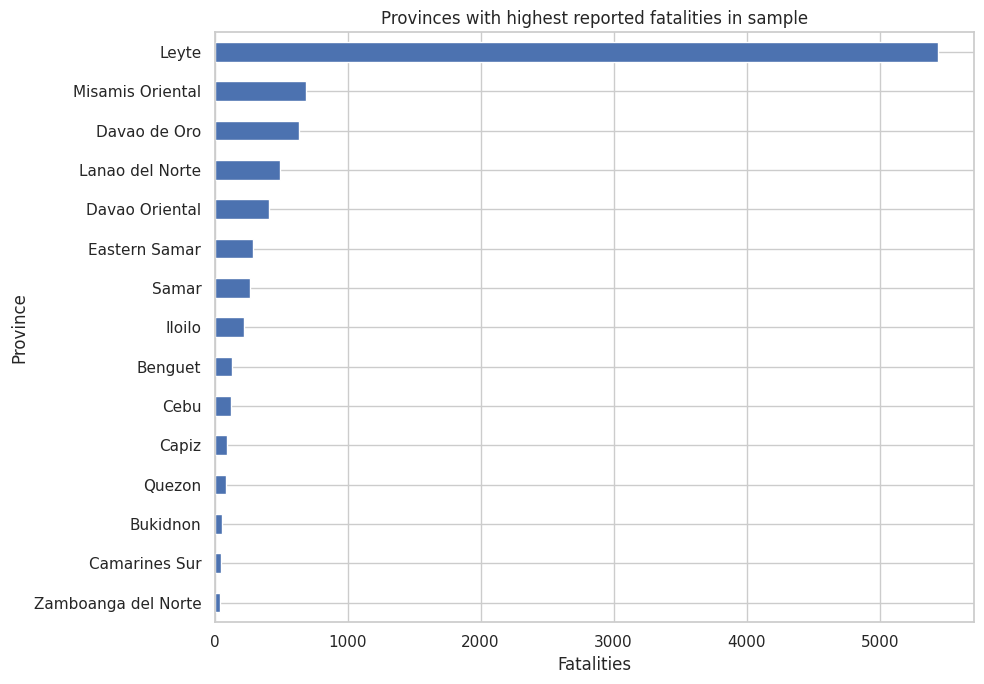

In [ ]:
# 1.12 Figure: provincial fatality totals (coverage-biased, not population-standardised)
top = imp.groupby("province").deaths.sum(min_count=1).nlargest(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
top.plot.barh(ax=ax)
ax.set(
    title="Provinces with highest reported fatalities in sample",
    xlabel="Fatalities",
    ylabel="Province",
)
plot_finish("10_province_deaths")

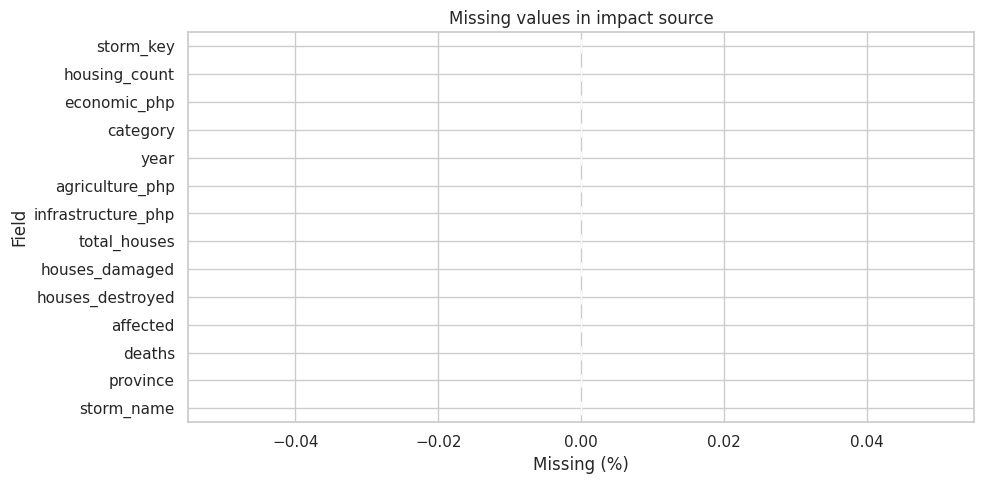

In [ ]:
# 1.13 Figure: missingness by field
fig, ax = plt.subplots(figsize=(10, 5))
(100 * imp.isna().mean()).sort_values().plot.barh(ax=ax)
ax.set(title="Missing values in impact source", xlabel="Missing (%)", ylabel="Field")
plot_finish("11_impact_missingness")

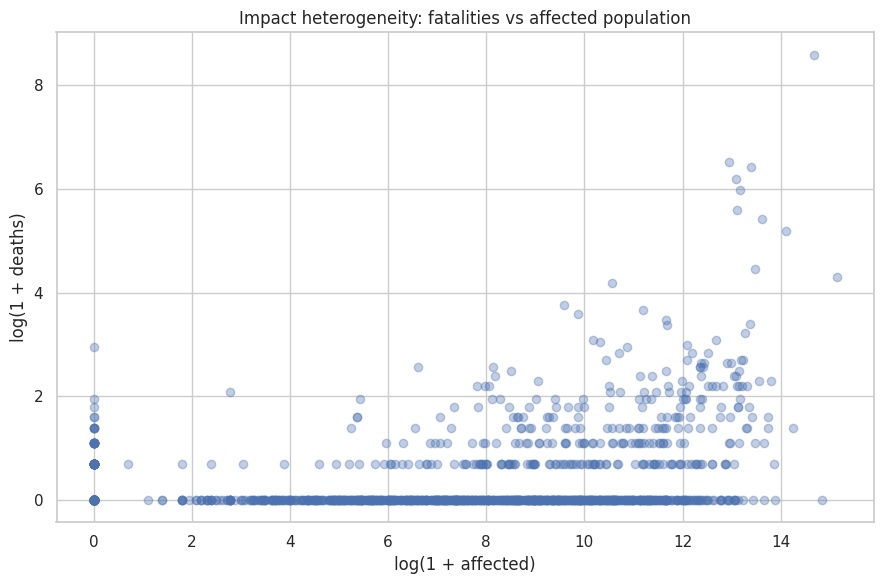

In [ ]:
# 1.14 Figure: deaths vs affected, showing cross-province heterogeneity
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    np.log1p(imp.affected.clip(lower=0)), np.log1p(imp.deaths.clip(lower=0)), alpha=0.35
)
ax.set(
    title="Impact heterogeneity: fatalities vs affected population",
    xlabel="log(1 + affected)",
    ylabel="log(1 + deaths)",
)
plot_finish("12_deaths_vs_affected")

### Full-archive IBTrACS overview and Philippine Area of Responsibility

These exploratory figures use the **ALL** archive and all available years, separately from the 2010–2020 western Pacific analysis below. Storm counts use unique `SID`s, including all archive track types; a storm appearing in multiple basins is counted in each. IBTrACS is a historical best-track archive, not a record of what was known at forecast time. Basin and record coverage change over time.

The PAR polygon uses the six published vertices in [Philippine Area of Responsibility](https://en.wikipedia.org/wiki/Philippine_Area_of_Responsibility). PAR intersection describes a track entering a monitoring area, not landfall or impact in the Philippines.

Full archive: 13,557 unique storms; 723,000 records; seasons 1842–2026.
Storms in multiple basins: 666; storms without a basin code: 0. Basin totals can exceed the global count.
Missing/invalid season records: 0; timestamp records: 0.


,BASIN,basin,storms
0,WP,Western North Pacific,4225
1,SI,South Indian,2882
2,NA,North Atlantic,2317
3,NI,North Indian,1845
4,EP,Eastern North Pacific,1700
5,SP,South Pacific,1251
6,SA,South Atlantic,3


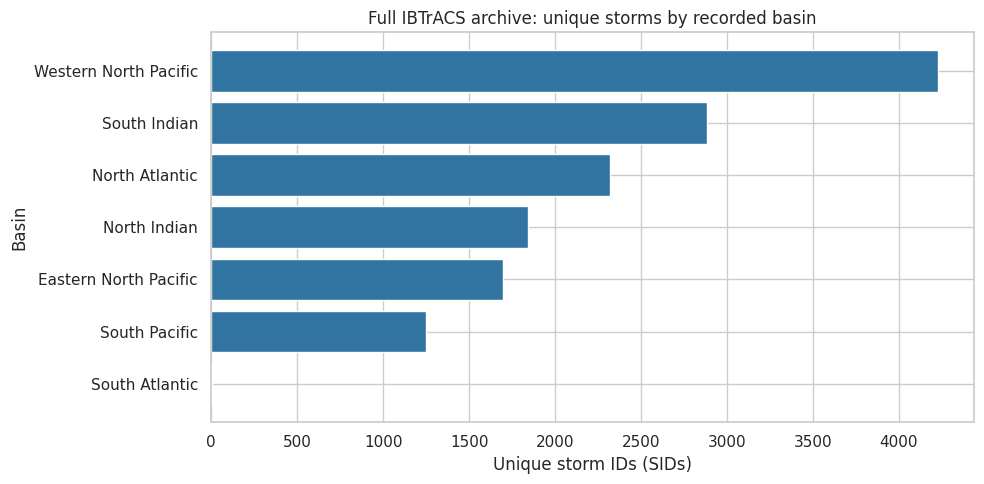

In [ ]:
# 1.14a Full IBTrACS archive: unique storms and basin distribution
ib_all_path = ROOT / "ibtracs" / "ibtracs.ALL.list.v04r01.csv"
if not ib_all_path.is_file():
    raise FileNotFoundError(f"Full IBTrACS archive not found: {ib_all_path}")
ib_all_columns = ["SID", "SEASON", "BASIN", "ISO_TIME", "LAT", "LON", "TRACK_TYPE"]
# Keep the literal basin code NA (North Atlantic), which pandas otherwise treats as missing.
ib_all = pd.read_csv(
    ib_all_path, skiprows=[1], usecols=ib_all_columns, dtype=str, keep_default_na=False
)
for column in ib_all_columns:
    ib_all[column] = ib_all[column].str.strip()
if ib_all.empty or ib_all["SID"].eq("").any():
    raise ValueError("The full IBTrACS file is empty or contains blank storm IDs.")
ib_all["SEASON"] = pd.to_numeric(ib_all["SEASON"], errors="coerce")
ib_all["ISO_TIME"] = pd.to_datetime(ib_all["ISO_TIME"], errors="coerce", utc=True)
for column in ["LAT", "LON"]:
    ib_all[column] = pd.to_numeric(ib_all[column], errors="coerce")
if ib_all["SEASON"].notna().sum() == 0:
    raise ValueError("No valid IBTrACS seasons found in the global archive.")
basin_names = {
    "NA": "North Atlantic",
    "EP": "Eastern North Pacific",
    "WP": "Western North Pacific",
    "NI": "North Indian",
    "SI": "South Indian",
    "SP": "South Pacific",
    "SA": "South Atlantic",
}
basin_pairs = ib_all.loc[ib_all["BASIN"].ne(""), ["SID", "BASIN"]].drop_duplicates()
basin_counts = (
    basin_pairs.groupby("BASIN")["SID"]
    .nunique()
    .sort_values(ascending=False)
    .rename("storms")
    .reset_index()
)
basin_counts["basin"] = (
    basin_counts["BASIN"].map(basin_names).fillna(basin_counts["BASIN"])
)
multi_basin = basin_pairs.groupby("SID")["BASIN"].nunique().gt(1).sum()
no_basin = ib_all["SID"].nunique() - basin_pairs["SID"].nunique()
print(
    f"Full archive: {ib_all['SID'].nunique():,} unique storms; {len(ib_all):,} records; seasons {int(ib_all['SEASON'].min())}–{int(ib_all['SEASON'].max())}."
)
print(
    f"Storms in multiple basins: {multi_basin:,}; storms without a basin code: {no_basin:,}. Basin totals can exceed the global count."
)
print(
    f"Missing/invalid season records: {ib_all['SEASON'].isna().sum():,}; timestamp records: {ib_all['ISO_TIME'].isna().sum():,}."
)
display(basin_counts[["BASIN", "basin", "storms"]])
basin_counts.to_csv(OUT / "ibtracs_all_basin_storm_counts.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(basin_counts["basin"], basin_counts["storms"], color="#3274a1")
ax.invert_yaxis()
ax.set(
    title="Full IBTrACS archive: unique storms by recorded basin",
    xlabel="Unique storm IDs (SIDs)",
    ylabel="Basin",
)
plot_finish("20a_ibtracs_all_basins")

WP-associated storms: 4,225; tracks intersecting PAR: 2,837.
Observed fixes in/on PAR: 2,837; detected only by interpolated segments: 0.
Segments join consecutive valid fixes up to 12 hours apart; longer gaps, missing coordinates and dateline jumps are not interpolated.


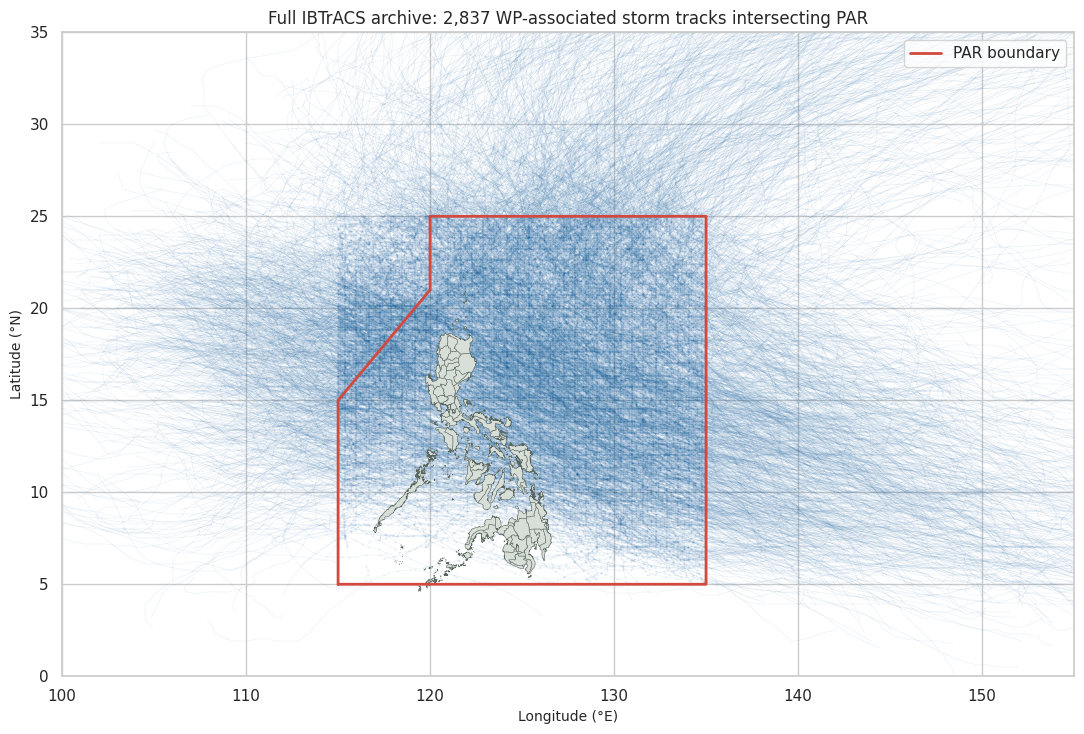

In [ ]:
# 1.14b Full archive: Western North Pacific tracks intersecting the PAR
from shapely.geometry import Point, LineString, Polygon
from matplotlib.collections import LineCollection
import geopandas as gpd, pyogrio

par_gadm_path = ROOT / "gadm" / "gadm41_PHL.gpkg"
par_layers = pyogrio.list_layers(par_gadm_path)
par_level1 = next(
    (
        name
        for name, kind in par_layers
        if name.endswith("_1") or name.lower().endswith("level1")
    ),
    None,
)
if par_level1 is None:
    par_level1 = par_layers[min(1, len(par_layers) - 1)][0]
par_geo = gpd.read_file(par_gadm_path, layer=par_level1).to_crs(4326)

par_vertices = [(115, 5), (115, 15), (120, 21), (120, 25), (135, 25), (135, 5)]
par_polygon = Polygon(par_vertices)
wp_sids = set(basin_pairs.loc[basin_pairs["BASIN"].eq("WP"), "SID"])
if not wp_sids:
    raise ValueError(
        "No Western North Pacific (WP) storm IDs were found in the ALL archive."
    )
wp_tracks = (
    ib_all.loc[ib_all["SID"].isin(wp_sids)]
    .sort_values(["SID", "ISO_TIME"], kind="stable")
    .reset_index(drop=True)
)
valid_position = wp_tracks["LAT"].between(-90, 90) & wp_tracks["LON"].between(-180, 180)
near_par = (
    valid_position
    & wp_tracks["LAT"].between(5, 25)
    & wp_tracks["LON"].between(115, 135)
)
point_hits = {
    row.SID
    for row in wp_tracks.loc[near_par, ["SID", "LON", "LAT"]].itertuples(index=False)
    if par_polygon.covers(Point(row.LON, row.LAT))
}
previous = wp_tracks.shift(1)
time_gap = wp_tracks["ISO_TIME"] - previous["ISO_TIME"]
valid_segment = (
    wp_tracks["SID"].eq(previous["SID"])
    & valid_position
    & valid_position.shift(1, fill_value=False)
    & time_gap.gt(pd.Timedelta(0))
    & time_gap.le(pd.Timedelta(hours=12))
    & (wp_tracks["LON"] - previous["LON"]).abs().le(180)
)
segment_near_par = (
    valid_segment
    & np.minimum(wp_tracks["LON"], previous["LON"]).le(135)
    & np.maximum(wp_tracks["LON"], previous["LON"]).ge(115)
    & np.minimum(wp_tracks["LAT"], previous["LAT"]).le(25)
    & np.maximum(wp_tracks["LAT"], previous["LAT"]).ge(5)
)
crossing_hits = set()
for idx in np.flatnonzero(segment_near_par.to_numpy()):
    segment = LineString(
        [
            (previous.at[idx, "LON"], previous.at[idx, "LAT"]),
            (wp_tracks.at[idx, "LON"], wp_tracks.at[idx, "LAT"]),
        ]
    )
    if segment.intersects(par_polygon):
        crossing_hits.add(wp_tracks.at[idx, "SID"])
par_sids = point_hits | crossing_hits
print(
    f"WP-associated storms: {len(wp_sids):,}; tracks intersecting PAR: {len(par_sids):,}."
)
print(
    f"Observed fixes in/on PAR: {len(point_hits):,}; detected only by interpolated segments: {len(par_sids - point_hits):,}."
)
print(
    "Segments join consecutive valid fixes up to 12 hours apart; longer gaps, missing coordinates and dateline jumps are not interpolated."
)
if not par_sids:
    raise ValueError(
        "No WP storm tracks intersect the PAR; inspect coordinates and input file."
    )
par_storms = (
    wp_tracks.loc[wp_tracks["SID"].isin(par_sids), ["SID", "SEASON"]]
    .drop_duplicates("SID")
    .copy()
)
par_storms["detection"] = np.where(
    par_storms["SID"].isin(point_hits), "observed_fix", "interpolated_segment_only"
)
par_storms.to_csv(OUT / "ibtracs_all_wp_par_storms.csv", index=False)
plot_segments = valid_segment & wp_tracks["SID"].isin(par_sids)
idx = np.flatnonzero(plot_segments.to_numpy())
segments = np.stack(
    [
        np.column_stack([previous.loc[idx, "LON"], previous.loc[idx, "LAT"]]),
        np.column_stack([wp_tracks.loc[idx, "LON"], wp_tracks.loc[idx, "LAT"]]),
    ],
    axis=1,
)
fig, ax = plt.subplots(figsize=(11, 9))
par_geo.plot(ax=ax, facecolor="#d8ded8", edgecolor="#59665d", linewidth=0.35, zorder=2)
ax.add_collection(
    LineCollection(segments, colors="#2167a5", linewidths=0.35, alpha=0.12, zorder=1)
)
in_par_points = wp_tracks.loc[near_par & wp_tracks["SID"].isin(par_sids)]
ax.scatter(
    in_par_points["LON"],
    in_par_points["LAT"],
    s=0.5,
    color="#2167a5",
    alpha=0.06,
    zorder=1,
)
boundary = np.array(par_vertices + [par_vertices[0]])
ax.plot(
    boundary[:, 0],
    boundary[:, 1],
    color="#d1493f",
    linewidth=2,
    label="PAR boundary",
    zorder=3,
)
ax.set(
    xlim=(100, 155),
    ylim=(0, 35),
    xlabel="Longitude (°E)",
    ylabel="Latitude (°N)",
    title=f"Full IBTrACS archive: {len(par_sids):,} WP-associated storm tracks intersecting PAR",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")
plot_finish("20b_ibtracs_wp_par_tracks")

### IBTrACS: storm-track data

IBTrACS `ibtracs.WP.list.v04r01.csv` has a units row directly after its header. Use **storm ID (`SID`)**, **ISO_TIME**, latitude, longitude and a vetted wind field. Wind fields from different agencies are not automatically interchangeable. We first inspect and use `USA_WIND` where available, and report missingness instead of silently combining agencies.

In [ ]:
# 1.15 Load IBTrACS with timestamp parsing, source column audit
ib_path = ROOT / "ibtracs/ibtracs.WP.list.v04r01.csv"
ib = pd.read_csv(ib_path, skiprows=[1], low_memory=False)
ib.columns = ib.columns.str.strip()
print("IBTrACS columns:", list(ib.columns))
for c in ["LAT", "LON", "USA_WIND", "WMO_WIND", "USA_PRES"]:
    if c in ib:
        ib[c] = pd.to_numeric(ib[c], errors="coerce")
ib["ISO_TIME"] = pd.to_datetime(
    ib.ISO_TIME.astype(str).str.strip(), errors="coerce", utc=True
)
ib["SEASON"] = pd.to_numeric(ib.SEASON, errors="coerce")
ib["NAME"] = ib.NAME.fillna("").astype(str).str.strip().str.upper()
ib = ib[ib.SEASON.between(2010, 2020)].copy()
print("Rows:", len(ib), "Unique SIDs:", ib.SID.nunique())
display(ib[["SID", "NAME", "SEASON", "ISO_TIME", "LAT", "LON", "USA_WIND"]].head())

IBTrACS columns: ['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT', 'KMA_R30_DIR', 'KMA_R30_LONG', 'KMA_R30_SHORT', 'NEWDELHI_LAT', '

,SID,NAME,SEASON,ISO_TIME,LAT,LON,USA_WIND
215960,2010018N07113,UNNAMED,2010,2010-01-18 00:00:00+00:00,6.9,113.2,15.0
215961,2010018N07113,UNNAMED,2010,2010-01-18 03:00:00+00:00,7.0,113.1,18.0
215962,2010018N07113,UNNAMED,2010,2010-01-18 06:00:00+00:00,7.1,113.0,20.0
215963,2010018N07113,UNNAMED,2010,2010-01-18 09:00:00+00:00,7.3,112.9,23.0
215964,2010018N07113,UNNAMED,2010,2010-01-18 12:00:00+00:00,7.5,112.7,25.0


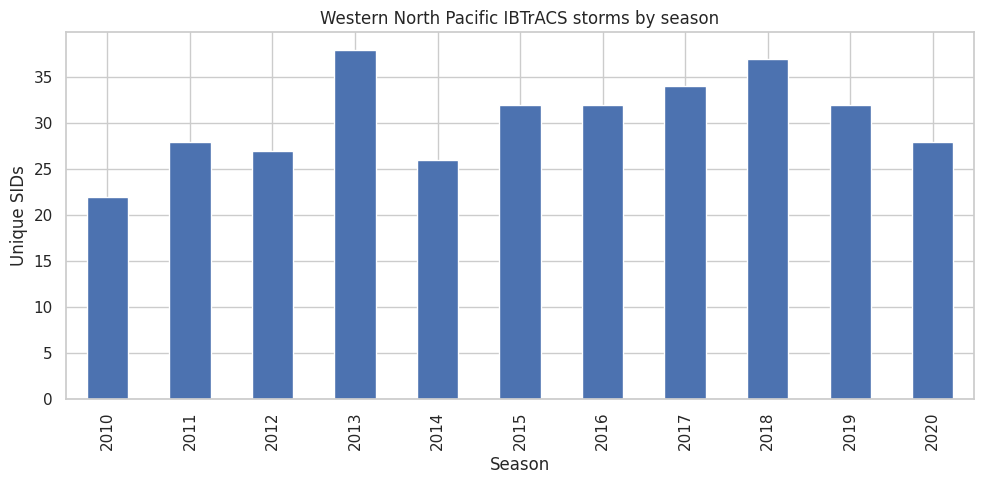

In [ ]:
# 1.16 Figure: storm-track point coverage over time
fig, ax = plt.subplots(figsize=(10, 5))
ib.groupby("SEASON").SID.nunique().plot(kind="bar", ax=ax)
ax.set(
    title="Western North Pacific IBTrACS storms by season",
    xlabel="Season",
    ylabel="Unique SIDs",
)
plot_finish("13_ibtracs_seasons")

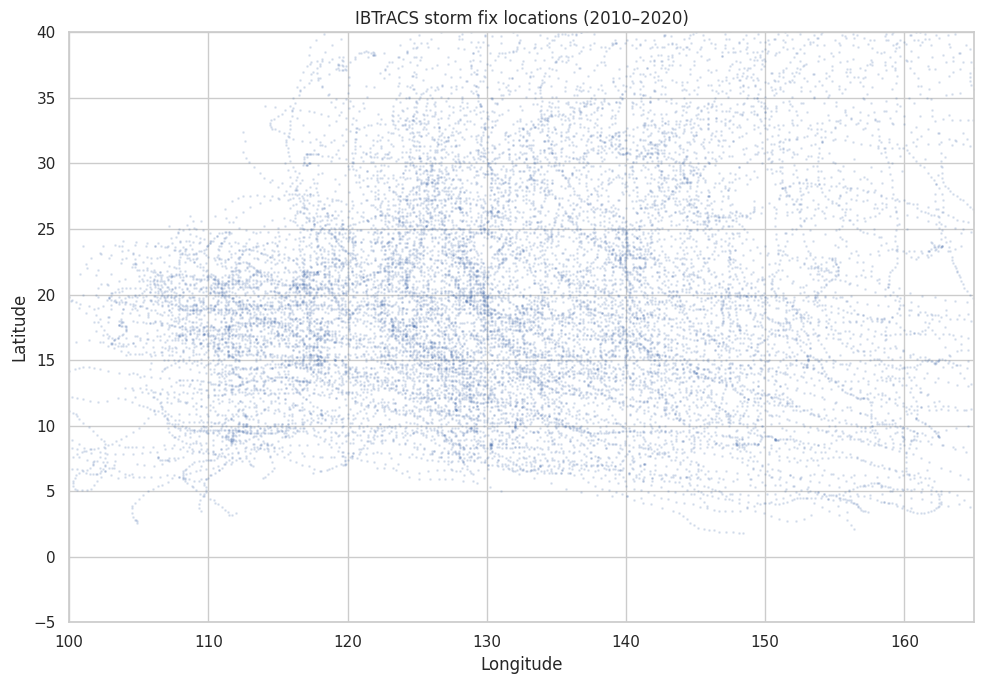

In [ ]:
# 1.17 Figure: raw track coverage across the western North Pacific
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(ib.LON, ib.LAT, s=1, alpha=0.14)
ax.set(
    xlim=(100, 165),
    ylim=(-5, 40),
    title="IBTrACS storm fix locations (2010–2020)",
    xlabel="Longitude",
    ylabel="Latitude",
)
plot_finish("14_ibtracs_locations")

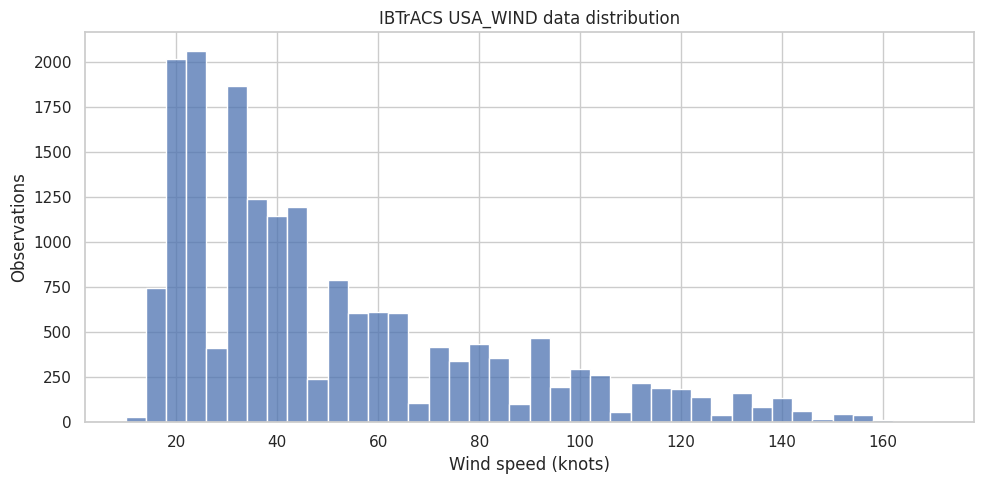

In [ ]:
# 1.18 Figure: available wind intensity distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(ib.USA_WIND.dropna(), bins=40, ax=ax)
ax.set(
    title="IBTrACS USA_WIND data distribution",
    xlabel="Wind speed (knots)",
    ylabel="Observations",
)
plot_finish("15_ibtracs_wind")

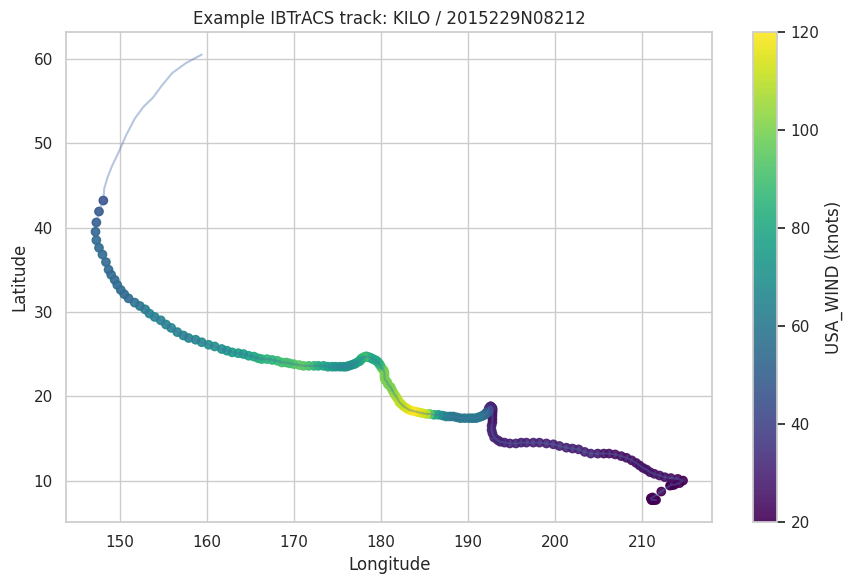

In [ ]:
# 1.19 Figure: one example storm track (never infer an impact match from name only)
example_sid = ib.groupby("SID").size().sort_values(ascending=False).index[0]
example = ib[ib.SID == example_sid].sort_values("ISO_TIME")
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(example.LON, example.LAT, c=example.USA_WIND, alpha=0.9, cmap="viridis")
ax.plot(example.LON, example.LAT, alpha=0.4)
plt.colorbar(sc, ax=ax, label="USA_WIND (knots)")
ax.set(
    title=f"Example IBTrACS track: {example.NAME.iloc[0]} / {example_sid}",
    xlabel="Longitude",
    ylabel="Latitude",
)
plot_finish("16_one_storm_track")

### NASA POWER: historical daily weather

The per-province CSVs contain an introductory `-BEGIN HEADER-` block. `PRECTOTCORR` and `WS10M_MAX` can describe weather around each province, **but only records before the prediction cutoff are eligible**. A daily value encompassing the impact day may include observations after the chosen 24h prediction cutoff; therefore the initial predictive pipeline leaves POWER features disabled pending a defensible temporal join.

In [ ]:
# 1.20 Parse all POWER files, taking care with -999 sentinels
power_files = sorted((ROOT / "nasa_power").glob("power_*.csv"))


def read_power(path):
    with open(path, encoding="utf-8-sig") as fh:
        lines = fh.readlines()
    header_ix = next(i for i, v in enumerate(lines) if v.startswith("YEAR,"))
    df = pd.read_csv(io.StringIO("".join(lines[header_ix:])))
    df["province_key"] = path.stem.removeprefix("power_").replace("_", " ").lower()
    df["date"] = pd.to_datetime(
        dict(year=df.YEAR, month=df.MO, day=df.DY), errors="coerce"
    )
    df = df.replace(-999, np.nan)
    return df


power = pd.concat([read_power(p) for p in power_files], ignore_index=True)
print("POWER rows:", len(power), "province files:", len(power_files))
display(power.head())

POWER rows: 325458 province files: 81


,YEAR,MO,DY,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,WS10M,WS10M_MAX,PS,RH2M,QV2M,province_key,date
0,2010,1,1,24.65,30.50,20.56,0.27,4.01,6.80,96.77,67.89,13.26,abra,2010-01-01
1,2010,1,2,24.74,30.17,20.68,0.11,1.74,3.47,96.82,69.63,13.72,abra,2010-01-02
2,2010,1,3,24.27,28.06,20.98,0.05,2.15,2.99,96.79,75.24,14.58,abra,2010-01-03
3,2010,1,4,24.06,30.15,19.83,0.03,2.71,5.51,96.67,70.62,13.24,abra,2010-01-04
4,2010,1,5,24.23,30.18,19.89,0.00,2.63,3.74,96.74,69.48,13.17,abra,2010-01-05


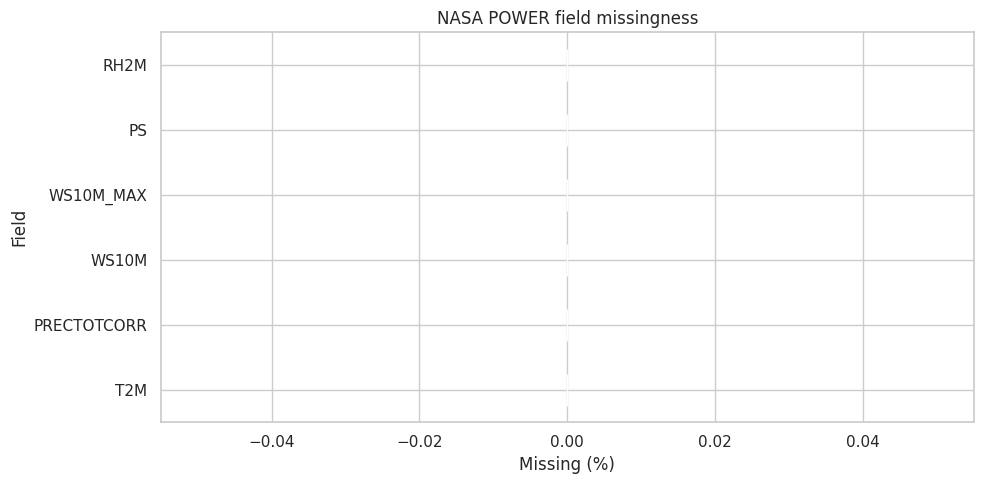

In [ ]:
# 1.21 Figure: missingness in weather fields
weather = ["T2M", "PRECTOTCORR", "WS10M", "WS10M_MAX", "PS", "RH2M"]
fig, ax = plt.subplots(figsize=(10, 5))
(power[weather].isna().mean() * 100).plot.barh(ax=ax)
ax.set(title="NASA POWER field missingness", xlabel="Missing (%)", ylabel="Field")
plot_finish("17_power_missingness")

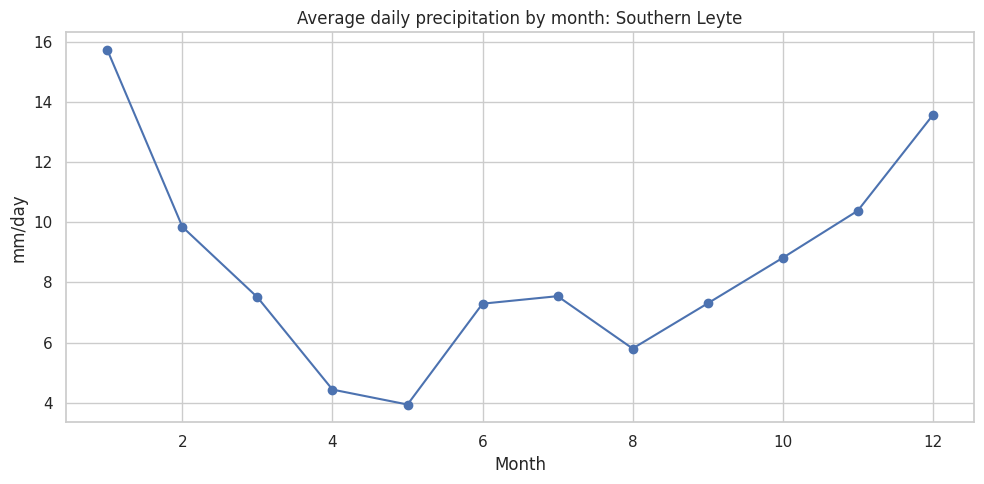

In [ ]:
# 1.22 Figure: seasonal rainfall at one province (descriptive only)
place = "southern leyte"
p = power[power.province_key == place].copy()
assert len(p), "Sample province not found in POWER data"
fig, ax = plt.subplots(figsize=(10, 5))
p.groupby("MO").PRECTOTCORR.mean().plot(marker="o", ax=ax)
ax.set(
    title=f"Average daily precipitation by month: {place.title()}",
    xlabel="Month",
    ylabel="mm/day",
)
plot_finish("18_power_rain_season")

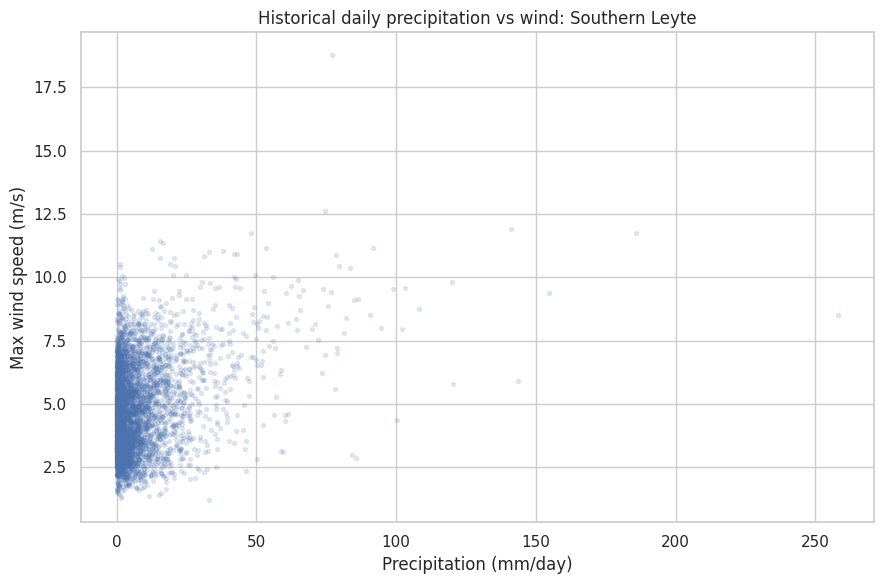

In [ ]:
# 1.23 Figure: rainfall vs maximum wind speed for example province
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(p.PRECTOTCORR, p.WS10M_MAX, alpha=0.15, s=8)
ax.set(
    title=f"Historical daily precipitation vs wind: {place.title()}",
    xlabel="Precipitation (mm/day)",
    ylabel="Max wind speed (m/s)",
)
plot_finish("19_power_rain_wind")

### GADM: boundary footprints and census population

GADM version 4.1 Philippine provincial boundaries are used for plotting and coordinate matching. Census 2000/2010/2015 can be used *as of* storm year; 2020 is inappropriate as a historical covariate for earlier years without explicit retrospective assumption. Geographic names require manual review (e.g. Metro Manila vs Metropolitan Manila; historical boundary changes).

,layer,geometry_type
0,ADM_ADM_0,MultiPolygon
1,ADM_ADM_1,MultiPolygon
2,ADM_ADM_2,MultiPolygon
3,ADM_ADM_3,MultiPolygon


GADM fields: ['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry'] rows: 81


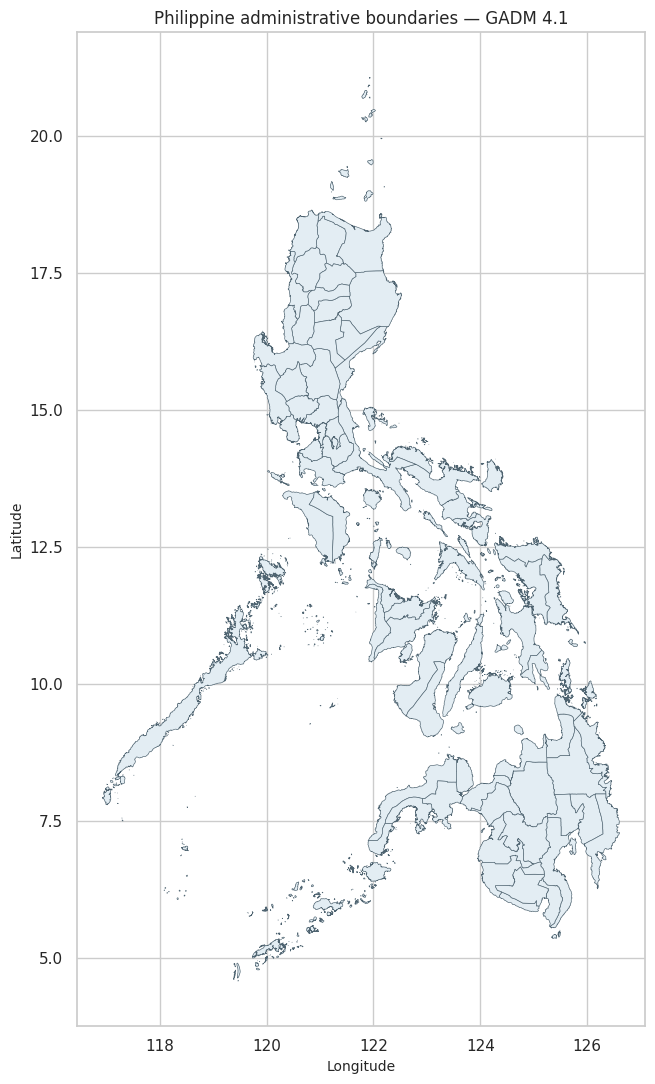

In [ ]:
# 1.24 Inspect GADM layers and plot Level-1 province boundaries
import geopandas as gpd, pyogrio

layers = pyogrio.list_layers(ROOT / "gadm/gadm41_PHL.gpkg")
display(pd.DataFrame(layers, columns=["layer", "geometry_type"]))
level1 = next(
    (nm for nm, typ in layers if nm.endswith("_1") or nm.lower().endswith("level1")),
    None,
)
if level1 is None:
    level1 = layers[min(1, len(layers) - 1)][0]  # ⚠️ REVIEW exact GADM level
geo = gpd.read_file(ROOT / "gadm/gadm41_PHL.gpkg", layer=level1).to_crs(4326)
print("GADM fields:", geo.columns.tolist(), "rows:", len(geo))
fig, ax = plt.subplots(figsize=(8, 11))
geo.plot(ax=ax, facecolor="#e3edf3", edgecolor="#4f6471", linewidth=0.45)
ax.set(
    title="Philippine administrative boundaries — GADM 4.1",
    xlabel="Longitude",
    ylabel="Latitude",
)
plot_finish("20_gadm_province_map")

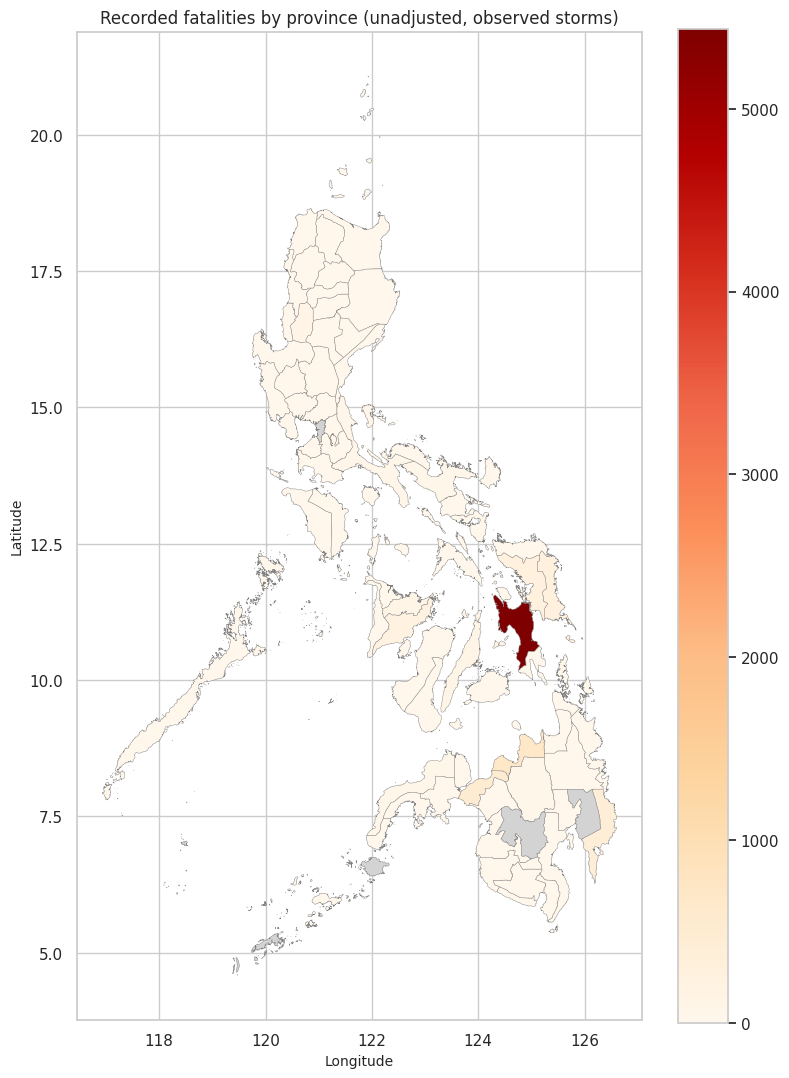

In [ ]:
# 1.12b Figure: geographic pattern of reported fatalities in observed records
geo_name = (
    "NAME_1"
    if "NAME_1" in geo.columns
    else next((c for c in geo.columns if c.startswith("NAME_")), None)
)
if geo_name:
    map_df = geo.copy()
    map_df["province_key"] = (
        map_df[geo_name]
        .str.lower()
        .str.strip()
        .replace({"metro manila": "metropolitan manila"})
    )
    prov_deaths = (
        imp.groupby(imp.province.str.lower().str.strip())
        .deaths.sum(min_count=1)
        .rename("deaths")
    )
    map_df = map_df.join(prov_deaths, on="province_key")
    fig, ax = plt.subplots(figsize=(8, 11))
    map_df.plot(
        column="deaths",
        ax=ax,
        legend=True,
        cmap="OrRd",
        missing_kwds={"color": "lightgray"},
        edgecolor="gray",
        linewidth=0.3,
    )
    ax.set(
        title="Recorded fatalities by province (unadjusted, observed storms)",
        xlabel="Longitude",
        ylabel="Latitude",
    )
    plot_finish("10b_deaths_map")
else:
    print("SKIPPED: GADM province name field not found.")

In [ ]:
# 1.25 Census schema and conservative historic population extract
census = pd.read_csv(ROOT / "psa_census/census_population_2000_2015.csv")
print("Census headers:", census.columns.tolist())
display(census.head(8))
geo_col = census.columns[0]
census["province_raw"] = census[geo_col].astype(str)
census["province"] = (
    census["province_raw"].str.replace(r"^\.+", "", regex=True).str.strip()
)
# ⚠️ REVIEW: census contains cities, regions, provinces, and excluding-city population records;
# matching by name is NOT sufficient for complete province totals without explicit administrative reconciliation.
for y in ["2000", "2010", "2015"]:
    census[y] = pd.to_numeric(census[y], errors="coerce")
print(
    "Census province name matches:",
    len(set(census.province.str.lower()) & set(imp.province.str.lower())),
)

Census headers: ['Geographic Location', '2000', '2010', '2015']


,Geographic Location,2000,2010,2015
0,PHILIPPINES,76506928,92337852,100981437
1,..National Capital Region (NCR),9932560,11855975,12877253
2,....City of Manila,1581082,1652171,1780148
3,....City of Mandaluyong,278474,328699,386276
4,....City of Marikina,391170,424150,450741
5,....City of Pasig,505058,669773,755300
6,....Quezon City,2173831,2761720,2936116
7,....City of San Juan,117680,121430,122180


Census province name matches: 60


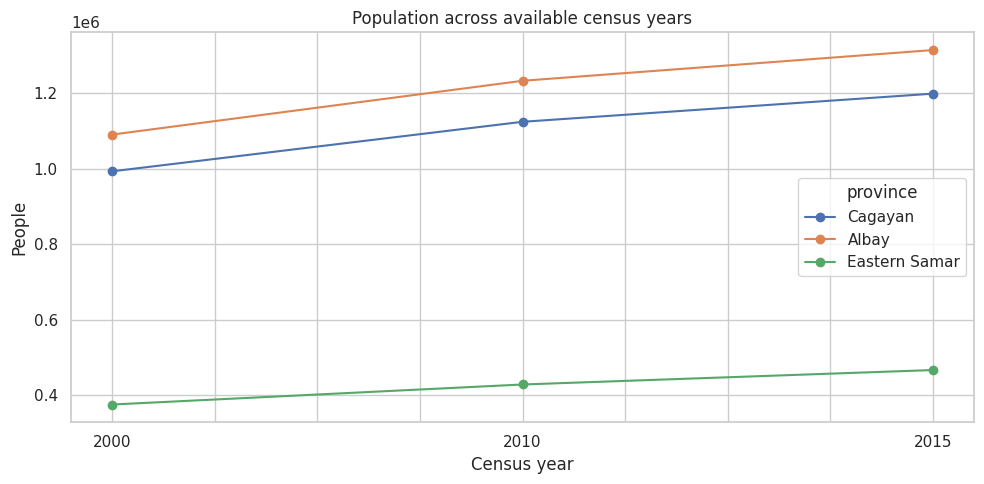

In [ ]:
# 1.26 Figure: selected province populations across censuses
selected = ["Leyte", "Cebu", "Albay", "Cagayan", "Eastern Samar"]
cp = (
    census[census.province.isin(selected)]
    .drop_duplicates("province")
    .set_index("province")[["2000", "2010", "2015"]]
    .T
)
fig, ax = plt.subplots(figsize=(10, 5))
cp.plot(ax=ax, marker="o")
ax.set(
    title="Population across available census years",
    xlabel="Census year",
    ylabel="People",
)
plot_finish("21_population_census")

### Poverty, housing and terrain: source audits

The audited poverty CSV contains 2018/2021/2023 estimates; the separate updated 2015/2018 workbook is used later as a retrospective modeling proxy. Housing features use a provincial summary of the 2020 census as a proxy for all storm years. These proxies include future information for earlier storms, and publication dates require verification.

In [ ]:
# 1.27 Review socioeconomic source schemas (do not use future figures as historical predictors)
poverty = pd.read_csv(ROOT / "psa_poverty/poverty_incidence_population.csv")
housing_book = pd.ExcelFile(ROOT / "psa_housing/housing_roof_wall_census2020.xlsx")
print("Poverty shape:", poverty.shape)
print("Poverty columns:", poverty.columns.tolist())
display(poverty.head(4))
print("Housing worksheets:", housing_book.sheet_names)
housing_preview = pd.read_excel(housing_book, sheet_name=0, header=None, nrows=12)
display(housing_preview)

Poverty shape: (108, 19)
Poverty columns: ['Geolocation', 'Annual Per Capita Poverty Threshold (in PhP) 2018', 'Annual Per Capita Poverty Threshold (in PhP) 2021', 'Annual Per Capita Poverty Threshold (in PhP) 2023', 'Poverty Incidence among Population (%) 2018', 'Poverty Incidence among Population (%) 2021', 'Poverty Incidence among Population (%) 2023', 'Coefficient of Variation 2018', 'Coefficient of Variation 2021', 'Coefficient of Variation 2023', 'Standard Error 2018', 'Standard Error 2021', 'Standard Error 2023', '95% Confidence Interval (Lower Limits) 2018', '95% Confidence Interval (Lower Limits) 2021', '95% Confidence Interval (Lower Limits) 2023', '95% Confidence Interval (Upper Limits) 2018', '95% Confidence Interval (Upper Limits) 2021', '95% Confidence Interval (Upper Limits) 2023']


,Geolocation,Annual Per Capita Poverty Threshold (in PhP) 2018,Annual Per Capita Poverty Threshold (in PhP) 2021,Annual Per Capita Poverty Threshold (in PhP) 2023,Poverty Incidence among Population (%) 2018,Poverty Incidence among Population (%) 2021,Poverty Incidence among Population (%) 2023,Coefficient of Variation 2018,Coefficient of Variation 2021,Coefficient of Variation 2023,Standard Error 2018,Standard Error 2021,Standard Error 2023,95% Confidence Interval (Lower Limits) 2018,95% Confidence Interval (Lower Limits) 2021,95% Confidence Interval (Lower Limits) 2023,95% Confidence Interval (Upper Limits) 2018,95% Confidence Interval (Upper Limits) 2021,95% Confidence Interval (Upper Limits) 2023
0,"PHILIPPINES r1, 1/, 2/, 3/",25814,28794,33296,16.7,18.1,15.5,1.3,1.3,1.4,0.2,0.2,0.2,16,18,15,17,19,16
1,"..National Capital Region (NCR) 1/, 2/, a/",28682,32978,37711,2.2,3.5,1.8,11.4,6.8,9.9,0.3,0.2,0.2,2,3,2,3,4,2
2,"....1st District a/, b/, c/",28682,32978,37711,3.0,1.7,2.4,30.2,32.9,27.0,0.9,0.6,0.6,1,1,1,5,3,4
3,"....2nd District 2/, a/, b/, c/",28682,32978,37711,2.3,2.8,1.5,23.1,15.7,21.1,0.5,0.4,0.3,1,2,1,3,4,2


Housing worksheets: ['PHL', 'Region', 'Province', 'Mun']


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Region,Construction Materials of the Outer Walls,Total Occupied Housing Units,Galvanized iron/\naluminum_roof,Concrete/\nclay tile_roof,Half \ngalvanized iron and half concrete_roof,Wood/\nbamboo_roof,Cogon/\nnipa/\nanahaw_roof,Asbestos_roof,Makeshift/\nsalvaged/\nimprovised materials_roof,Others_roof,Not reported_roof,Not applicable_roof
1,PHILIPPINES,Total,25191610,21628383,1127971,670698,399419,1195094,24566,59404,18920,65481,1674
2,PHILIPPINES,Concrete/brick/stone,15205672,13816455,987591,287350,29569,60849,9748,3592,5480,5038,0
3,PHILIPPINES,Wood,3642901,2933397,73886,87514,187231,335910,8808,8705,2880,4570,0
4,PHILIPPINES,Half concrete/brick/stone and half wood,2897980,2465425,56581,275928,23208,65029,4907,2889,1599,2414,0
5,PHILIPPINES,Galvanized iron/aluminum,271808,239182,4321,10923,8743,7517,123,704,197,98,0
6,PHILIPPINES,Bamboo/sawali/cogon/nipa,2786883,1900599,0,0,146840,692254,0,9845,4434,32911,0
7,PHILIPPINES,Asbestos,20078,14075,735,3838,0,0,868,0,21,541,0
8,PHILIPPINES,Glass,17085,14632,1522,834,0,0,0,0,0,97,0
9,PHILIPPINES,Makeshift/salvaged/improvised materials,184912,118993,0,0,2569,26651,0,33245,809,2645,0


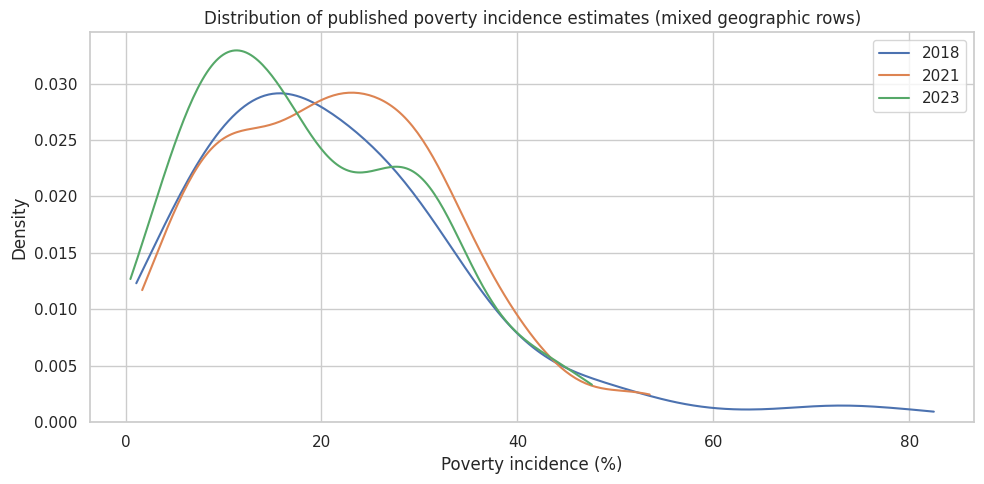

In [ ]:
# 1.28 Figure: poverty incidence values from available 2018/2021/2023 series
poverty_cols = [c for c in poverty if "Poverty Incidence among Population (%)" in c]
fig, ax = plt.subplots(figsize=(10, 5))
for c in poverty_cols:
    vals = pd.to_numeric(poverty[c], errors="coerce")
    sns.kdeplot(
        vals.dropna(),
        ax=ax,
        label=re.search(r"20\d{2}", c).group(0) if re.search(r"20\d{2}", c) else c,
        cut=0,
    )
ax.legend()
ax.set(
    title="Distribution of published poverty incidence estimates (mixed geographic rows)",
    xlabel="Poverty incidence (%)",
    ylabel="Density",
)
plot_finish("22_poverty_distributions")

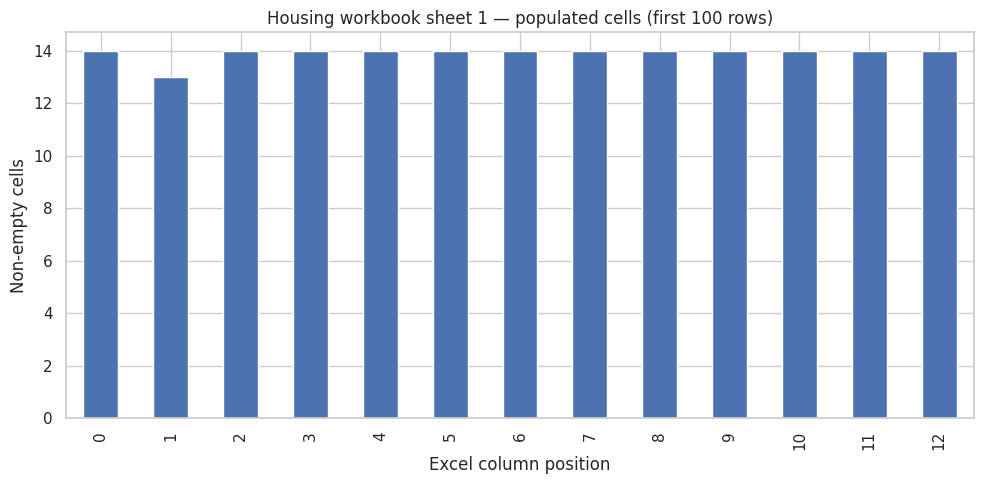

In [ ]:
# 1.28b Figure: housing workbook audit — number of populated cells in first worksheet sample
# This is a STRUCTURE/QUALITY figure, not invented province-level housing counts.
housing_raw = pd.read_excel(housing_book, sheet_name=0, header=None, nrows=100)
nonempty = housing_raw.notna().sum(axis=0)
fig, ax = plt.subplots(figsize=(10, 5))
nonempty.iloc[:25].plot(kind="bar", ax=ax)
ax.set(
    title="Housing workbook sheet 1 — populated cells (first 100 rows)",
    xlabel="Excel column position",
    ylabel="Non-empty cells",
)
plot_finish("22b_housing_sheet_structure")

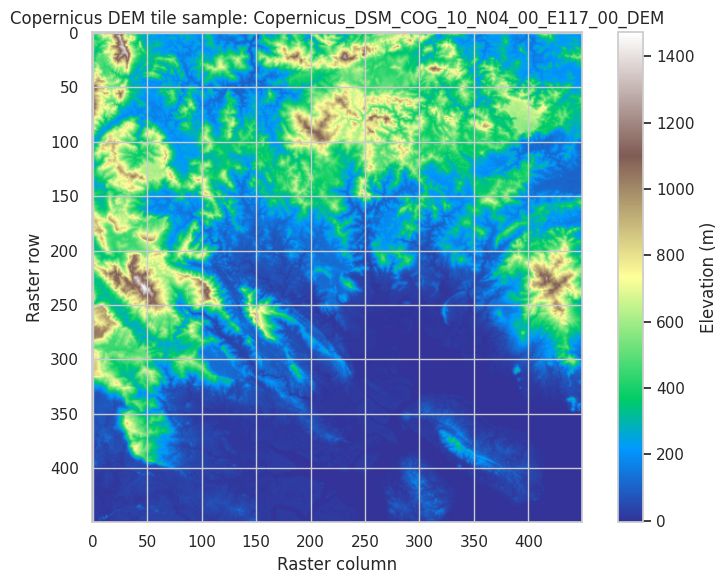

In [ ]:
# 1.29 Figure: representative Copernicus DEM raster tile (not SRTM despite folder name)
import rasterio

raster_files = sorted((ROOT / "srtm").glob("*.tif"))
assert raster_files, "No DEM raster tiles found"
with rasterio.open(raster_files[0]) as src:
    dem = src.read(
        1, out_shape=(min(src.height, 450), min(src.width, 450)), masked=True
    )
    desc = src.name
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(dem, cmap="terrain")
fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set(
    title=f"Copernicus DEM tile sample: {Path(desc).stem}",
    xlabel="Raster column",
    ylabel="Raster row",
)
plot_finish("23_dem_example")

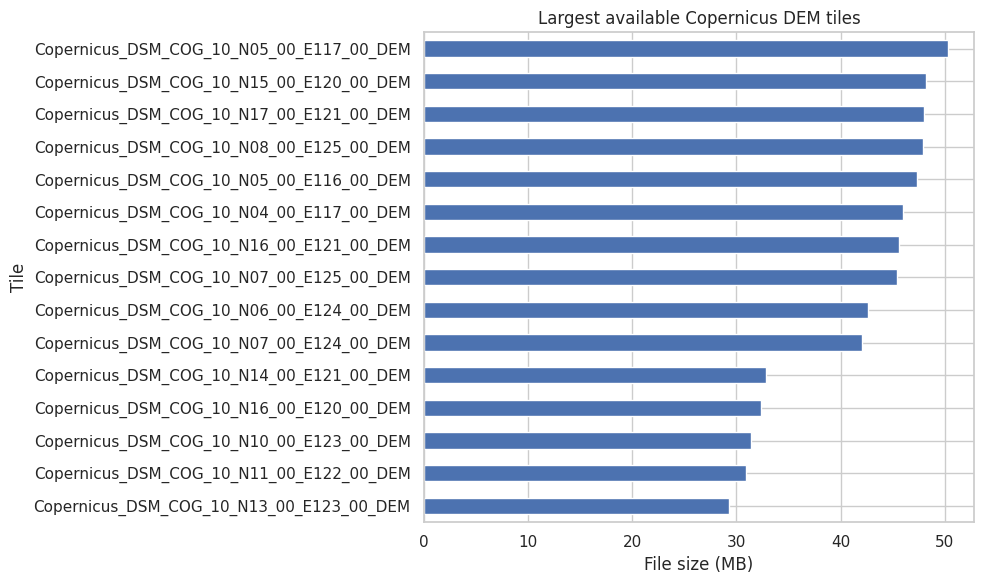

In [ ]:
# 1.30 Figure: DEM source file sizes reveal spatial coverage variation
sizes = (
    pd.Series({p.stem: round(p.stat().st_size / 1e6, 1) for p in raster_files})
    .sort_values(ascending=False)
    .head(15)
)
fig, ax = plt.subplots(figsize=(10, 6))
sizes.sort_values().plot(kind="barh", ax=ax)
ax.set(
    title="Largest available Copernicus DEM tiles",
    xlabel="File size (MB)",
    ylabel="Tile",
)
plot_finish("24_dem_inventory")

### Digital Typhoon Dataset (DTD) audit

The original DTD archive may be too large to unzip into ephemeral Colab storage. The optional ZIP workflow in 2.2l reads indexed HDF5 images without extracting the archive. It uses explicitly assumed storm matches, landfall anchors and UTC timestamps; these assumptions must be reported with model results.

In [ ]:
# 1.31 Archive metadata only — ZIP central-directory reading may still be expensive on Drive
zip_path = ROOT / "dtd/V3-2025.R2-WP-1.zip"
print(
    "DTD archive exists:",
    zip_path.exists(),
    "size GB:",
    round(zip_path.stat().st_size / 1e9, 2) if zip_path.exists() else None,
)
INSPECT_DTD_ZIP = False
if INSPECT_DTD_ZIP:
    with zipfile.ZipFile(zip_path) as z:
        members = z.namelist()
        print("Members:", len(members))
        display(pd.DataFrame({"path": members[:30]}))

DTD archive exists: True size GB: 63.37


In [ ]:
# 1.31a Prepare a DTD image inventory for review; do not extract images
import re
import zipfile

dtd_zip = ROOT / "dtd" / "V3-2025.R2-WP-1.zip"
if not dtd_zip.is_file():
    raise FileNotFoundError(f"DTD archive not found: {dtd_zip}")
metadata_pattern = re.compile(r"^1/WP/metadata/(\d{6})\.csv$")
inventory_parts = []
with zipfile.ZipFile(dtd_zip) as archive:
    members = archive.infolist()
    member_names = [member.filename for member in members]
    if len(member_names) != len(set(member_names)):
        raise ValueError(
            "DTD ZIP contains duplicate member names; inspect the archive before indexing."
        )
    member_set = set(member_names)
    metadata_files = [
        (member, metadata_pattern.fullmatch(member.filename)) for member in members
    ]
    metadata_files = [(member, match) for member, match in metadata_files if match]
    if not metadata_files:
        raise ValueError(
            "No DTD metadata CSVs found under 1/WP/metadata/. Check the archive version."
        )
    for metadata_file, match in metadata_files:
        if metadata_file.file_size > 16 * 1024 * 1024:
            raise ValueError(
                f"Metadata file is unexpectedly large: {metadata_file.filename}"
            )
        with archive.open(metadata_file) as data:
            table = pd.read_csv(data, dtype=str, keep_default_na=False)
        required = {"year", "month", "day", "hour", "file_1"}
        missing = required - set(table.columns)
        if missing:
            raise ValueError(
                f"{metadata_file.filename} is missing columns: {sorted(missing)}"
            )
        table = table[table["file_1"].str.strip().ne("")].copy()
        if table.empty:
            continue
        dtd_id = match.group(1)
        table["file_1"] = table["file_1"].str.strip()
        date_parts = table[["year", "month", "day", "hour"]].apply(
            pd.to_numeric, errors="coerce"
        )
        timestamp = pd.to_datetime(date_parts, errors="coerce")
        table["metadata_time"] = timestamp.dt.strftime("%Y-%m-%d %H:%M:%S").fillna("")
        table["dtd_storm_id"] = dtd_id
        table["metadata_member"] = metadata_file.filename
        table["archive_member"] = "1/WP/image/" + dtd_id + "/" + table["file_1"]
        table["member_exists"] = table["archive_member"].isin(member_set)
        expected_prefix = (
            timestamp.dt.strftime("%Y%m%d%H").fillna("") + "-" + dtd_id + "-"
        )
        table["filename_matches_metadata"] = [
            bool(prefix) and name.startswith(prefix)
            for name, prefix in zip(table["file_1"], expected_prefix)
        ]
        inventory_parts.append(
            table[
                [
                    "dtd_storm_id",
                    "metadata_member",
                    "archive_member",
                    "metadata_time",
                    "member_exists",
                    "filename_matches_metadata",
                ]
            ]
        )
if not inventory_parts:
    raise ValueError("DTD metadata contains no channel 1 image references.")
dtd_inventory = pd.concat(inventory_parts, ignore_index=True)
dtd_inventory_path = (
    ROOT
    / "dtd"
    / f"dtd_image_inventory_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with dtd_inventory_path.open("x", encoding="utf-8", newline="") as output:
    dtd_inventory.to_csv(output, index=False)
print("DTD image inventory saved to:", dtd_inventory_path)
print(
    "Metadata files:",
    len(metadata_files),
    "| Image references:",
    len(dtd_inventory),
    "| DTD storm IDs:",
    dtd_inventory["dtd_storm_id"].nunique(),
)
print(
    "Missing ZIP members:",
    (~dtd_inventory["member_exists"]).sum(),
    "| Filename/time mismatches:",
    (~dtd_inventory["filename_matches_metadata"]).sum(),
)
print(
    "This is an inventory only, not a training manifest. Timestamp timezone, storm identities, and forecast cutoffs still need review."
)
display(dtd_inventory.head(10))

DTD image inventory saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd/dtd_image_inventory_20261123T155140174246Z.csv
Metadata files: 1169 | Image references: 202986 | DTD storm IDs: 1169
Missing ZIP members: 0 | Filename/time mismatches: 0
This is an inventory only, not a training manifest. Timestamp timezone, storm identities, and forecast cutoffs still need review.


,dtd_storm_id,metadata_member,archive_member,metadata_time,member_exists,filename_matches_metadata
0,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072100-198209-GMS2-1.h5,1982-07-21 00:00:00,True,True
1,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072103-198209-GMS2-1.h5,1982-07-21 03:00:00,True,True
2,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072106-198209-GMS2-1.h5,1982-07-21 06:00:00,True,True
3,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072109-198209-GMS2-1.h5,1982-07-21 09:00:00,True,True
4,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072112-198209-GMS2-1.h5,1982-07-21 12:00:00,True,True
5,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072116-198209-GMS2-1.h5,1982-07-21 16:00:00,True,True
6,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072118-198209-GMS2-1.h5,1982-07-21 18:00:00,True,True
7,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072121-198209-GMS2-1.h5,1982-07-21 21:00:00,True,True
8,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072200-198209-GMS2-1.h5,1982-07-22 00:00:00,True,True
9,198209,1/WP/metadata/198209.csv,1/WP/image/198209/1982072203-198209-GMS2-1.h5,1982-07-22 03:00:00,True,True


In [ ]:
# 1.32 Canonical image manifest structure and checks
# Create /dtd/image_manifest.csv after extracting/selecting images.
# Required: storm_key, image_path, image_time_utc, cutoff_time_utc.
# Each image must be timestamped BEFORE the forecast cutoff and matched to the storm.
MANIFEST_PATH = ROOT / "dtd/image_manifest.csv"
if MANIFEST_PATH.exists():
    manifest = pd.read_csv(MANIFEST_PATH)
    required = {"storm_key", "image_path", "image_time_utc", "cutoff_time_utc"}
    assert required.issubset(manifest.columns), (
        f"Missing columns: {required - set(manifest.columns)}"
    )
    for c in ["image_time_utc", "cutoff_time_utc"]:
        manifest[c] = pd.to_datetime(manifest[c], utc=True, errors="coerce")
    manifest["is_pre_cutoff"] = manifest.image_time_utc.lt(manifest.cutoff_time_utc)
    print(
        "Images:",
        len(manifest),
        "pre-cutoff:",
        manifest.is_pre_cutoff.mean(),
        "storms:",
        manifest.storm_key.nunique(),
    )
else:
    manifest = pd.DataFrame(
        columns=[
            "storm_key",
            "image_path",
            "image_time_utc",
            "cutoff_time_utc",
            "is_pre_cutoff",
        ]
    )
    display(
        pd.DataFrame(
            {
                "column": [
                    "storm_key",
                    "image_path",
                    "image_time_utc",
                    "cutoff_time_utc",
                ],
                "meaning": [
                    "canonical impact storm ID",
                    "absolute extracted/selected JPEG/PNG path",
                    "UTC frame timestamp",
                    "UTC issued prediction cutoff",
                ],
            }
        )
    )
    print(
        "⚠️ DTD manifest missing: ResNet/Fusion will SKIP training until it is created."
    )

,column,meaning
0,storm_key,canonical impact storm ID
1,image_path,absolute extracted/selected JPEG/PNG path
2,image_time_utc,UTC frame timestamp
3,cutoff_time_utc,UTC issued prediction cutoff


⚠️ DTD manifest missing: ResNet/Fusion will SKIP training until it is created.


In [ ]:
# 1.32b Figure: first verified DTD image (only when image manifest exists)
if len(manifest) and "is_pre_cutoff" in manifest:
    example_images = manifest[manifest.is_pre_cutoff].image_path.astype(str)
    example_images = [p for p in example_images if Path(p).exists()]
    if example_images:
        with Image.open(example_images[0]) as im:
            sample = np.array(im.convert("RGB"))
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.imshow(sample)
        ax.set(title="DTD frame sample — review source timestamp and storm ID")
        ax.axis("off")
        plot_finish("24b_dtd_sample")
    else:
        print("SKIPPED: no verified accessible extracted satellite image.")
else:
    print("SKIPPED: no verified DTD image manifest.")

SKIPPED: no verified DTD image manifest.


In [ ]:
# 1.33 Figure: image counts by storm if vetted manifest is present
if len(manifest):
    counts = (
        manifest[manifest.is_pre_cutoff].storm_key.value_counts().head(15).sort_values()
    )
    fig, ax = plt.subplots(figsize=(9, 6))
    counts.plot.barh(ax=ax)
    ax.set(
        title="Pre-cutoff DTD images per matched storm", xlabel="Images", ylabel="Storm"
    )
    plot_finish("25_dtd_counts")
else:
    print("SKIPPED: vetted image manifest not yet available.")

SKIPPED: vetted image manifest not yet available.


## 2. Event identity, temporal cutoff, and leakage prevention

**The dataset does not itself contain province-specific impact occurrence times.** The chosen forecast anchor is first Philippine landfall, with a cutoff 24 hours earlier by default. The optional 2.2l workflow uses assumed closest-track matches and interpolated landfall times rather than verified identities and anchors. It excludes unmatched storms and reports these assumptions.

For candidate matching, place `pagasa_aliases.csv` in the `pagasa` folder inside the project folder on Drive, run cells 2.1, 2.2, 2.2a, 2.2b, and 2.2c, and inspect the candidate CSV created in the project root. Cell 2.2d then estimates possible first landfall intervals from IBTrACS tracks and GADM boundaries. These are review aids, not verified identities or official landfall times. Neither cell changes the existing crosswalk or enables training.

In [ ]:
# 2.1 Storm crosswalk: write once and MANUALLY verify every row
crosswalk_path = OUT / "storm_crosswalk_review.csv"
# Candidate suggestions for HUMAN REVIEW, never silently treated as verified matches.
ib_storms = ib[["SID", "NAME", "SEASON"]].drop_duplicates().dropna(subset=["SID"])
impact_storms = imp[["storm_key", "storm_name", "year"]].drop_duplicates()
name_match = impact_storms.assign(
    name_norm=lambda d: d.storm_name.str.upper().str.strip()
).merge(
    ib_storms.assign(name_norm=lambda d: d.NAME.str.upper().str.strip()),
    left_on=["name_norm", "year"],
    right_on=["name_norm", "SEASON"],
    how="left",
)
if not crosswalk_path.exists():
    name_match[["storm_key", "storm_name", "year", "SID", "NAME"]].assign(
        verified=False, anchor_time_utc=""
    ).to_csv(crosswalk_path, index=False)
print("Review/edit:", crosswalk_path)
display(pd.read_csv(crosswalk_path).head(20))

Review/edit: /content/typhoon_research_outputs/storm_crosswalk_review.csv


,storm_key,storm_name,year,SID,NAME,verified,anchor_time_utc
0,conson_2010,Conson,2010,2010191N12138,CONSON,False,NaN
1,megi_2010,Megi,2010,2010285N13145,MEGI,False,NaN
2,aere_2011,Aere,2011,2011126N11129,AERE,False,NaN
3,songda_2011,Songda,2011,2011140N08142,SONGDA,False,NaN
4,dodong_2011,Dodong,2011,NaN,NaN,False,NaN
5,meari_2011,Meari,2011,2011172N11133,MEARI,False,NaN
6,juaning_2011,Juaning,2011,NaN,NaN,False,NaN
7,nanmadol_2011,Nanmadol,2011,2011233N12129,NANMADOL,False,NaN
8,nesat_2011,Nesat,2011,2011266N13139,NESAT,False,NaN
9,nalgae_2011,Nalgae,2011,2011270N18139,NALGAE,False,NaN


In [ ]:
# 2.2 Require verified crosswalk (user can copy into Google Drive if necessary)
# ⚠️ REVIEW: use exact SID and a verified cutoff anchor; no automatic date guessing.
crosswalk = pd.read_csv(crosswalk_path)
crosswalk = crosswalk[
    crosswalk.verified.astype(str).str.lower().isin(["true", "1", "yes"])
].copy()
assert crosswalk.storm_key.is_unique, (
    "Verified crosswalk has ambiguous storm_key matches."
)
crosswalk["anchor_time_utc"] = pd.to_datetime(
    crosswalk.anchor_time_utc, utc=True, errors="coerce"
)
print("Verified storm mappings:", len(crosswalk), "out of", imp.storm_key.nunique())
if len(crosswalk) == 0:
    print(
        "⚠️ Training requires verified SID mappings and anchor dates. Continue with EDA and crosswalk review."
    )

Verified storm mappings: 0 out of 85
⚠️ Training requires verified SID mappings and anchor dates. Continue with EDA and crosswalk review.


In [ ]:
# 2.2a Inspect candidate storm mappings before verification
review = pd.read_csv(crosswalk_path)
print("Crosswalk file:", crosswalk_path)
print("Total candidate rows:", len(review))
display(review.head(10))

Crosswalk file: /content/typhoon_research_outputs/storm_crosswalk_review.csv
Total candidate rows: 85


,storm_key,storm_name,year,SID,NAME,verified,anchor_time_utc
0,conson_2010,Conson,2010,2010191N12138,CONSON,False,NaN
1,megi_2010,Megi,2010,2010285N13145,MEGI,False,NaN
2,aere_2011,Aere,2011,2011126N11129,AERE,False,NaN
3,songda_2011,Songda,2011,2011140N08142,SONGDA,False,NaN
4,dodong_2011,Dodong,2011,NaN,NaN,False,NaN
5,meari_2011,Meari,2011,2011172N11133,MEARI,False,NaN
6,juaning_2011,Juaning,2011,NaN,NaN,False,NaN
7,nanmadol_2011,Nanmadol,2011,2011233N12129,NANMADOL,False,NaN
8,nesat_2011,Nesat,2011,2011266N13139,NESAT,False,NaN
9,nalgae_2011,Nalgae,2011,2011270N18139,NALGAE,False,NaN


In [ ]:
# 2.2b Step 1: review unmatched and ambiguous storm names
review = pd.read_csv(crosswalk_path)
review["SID"] = review["SID"].fillna("").astype(str).str.strip()
match_counts = review.groupby("storm_key")["SID"].agg(
    lambda values: values[values.ne("")].nunique()
)
print("Impact storms with one candidate SID:", (match_counts == 1).sum())
print("Impact storms with no candidate SID:", (match_counts == 0).sum())
print("Impact storms with multiple candidate SIDs:", (match_counts > 1).sum())
print("These are suggestions only; no matches are verified by this cell.")

needs_review = review[review["storm_key"].isin(match_counts[match_counts != 1].index)]
needs_review = needs_review[
    ["storm_key", "storm_name", "year", "SID", "NAME"]
].drop_duplicates()
print("\nStorms needing name matching:")
print(needs_review.to_string(index=False) if not needs_review.empty else "None")

unmatched = review[review["storm_key"].isin(match_counts[match_counts == 0].index)]
if not unmatched.empty:
    first = unmatched.iloc[0]
    candidates = (
        ib[ib["SEASON"] == first["year"]]
        .groupby(["SID", "NAME"], as_index=False)
        .agg(first_track_utc=("ISO_TIME", "min"), last_track_utc=("ISO_TIME", "max"))
        .sort_values("first_track_utc")
    )
    print(f"\nIBTrACS storms in {first['year']} for reviewing {first['storm_name']}:")
    display(candidates)

Impact storms with one candidate SID: 65
Impact storms with no candidate SID: 20
Impact storms with multiple candidate SIDs: 0
These are suggestions only; no matches are verified by this cell.

Storms needing name matching:
     storm_key storm_name  year SID NAME
   dodong_2011     Dodong  2011      NaN
  juaning_2011    Juaning  2011      NaN
   ferdie_2012     Ferdie  2012      NaN
     igme_2012       Igme  2012      NaN
   bising_2013     Bising  2013      NaN
  crising_2013    Crising  2013      NaN
   odette_2013     Odette  2013      NaN
    caloy_2014      Caloy  2014      NaN
     luis_2014       Luis  2014      NaN
    ineng_2015      Ineng  2015      NaN
    onyok_2015      Onyok  2015      NaN
    usman_2018      Usman  2018      NaN
    amang_2019      Amang  2019      NaN
  chedeng_2019    Chedeng  2019      NaN
  marilyn_2019    Marilyn  2019      NaN
     egay_2011       Egay  2011      NaN
    helen_2016      Helen  2016      NaN
   auring_2017     Auring  2017      N

,SID,NAME,first_track_utc,last_track_utc
0,2011091N09112,UNNAMED,2011-04-01 00:00:00+00:00,2011-04-03 18:00:00+00:00
1,2011093N10131,UNNAMED,2011-04-02 12:00:00+00:00,2011-04-06 00:00:00+00:00
2,2011126N11129,AERE,2011-05-05 18:00:00+00:00,2011-05-15 06:00:00+00:00
3,2011140N08142,SONGDA,2011-05-19 18:00:00+00:00,2011-06-02 00:00:00+00:00
4,2011151N19116,UNNAMED,2011-05-31 00:00:00+00:00,2011-06-01 18:00:00+00:00
5,2011159N13122,SARIKA,2011-06-08 00:00:00+00:00,2011-06-11 06:00:00+00:00
6,2011167N08129,HAIMA,2011-06-16 06:00:00+00:00,2011-06-25 18:00:00+00:00
7,2011172N11133,MEARI,2011-06-20 18:00:00+00:00,2011-06-27 06:00:00+00:00
8,2011192N18158,MA-ON,2011-07-10 18:00:00+00:00,2011-07-31 00:00:00+00:00
9,2011195N15134,TOKAGE,2011-07-13 12:00:00+00:00,2011-07-16 00:00:00+00:00


In [ ]:
# 2.2c Suggest IBTrACS matches using the local-name lookup (review only)
alias_path = ROOT / "pagasa" / "pagasa_aliases.csv"
if not alias_path.is_file():
    raise FileNotFoundError(
        f"Upload pagasa_aliases.csv to the pagasa folder inside your project folder: {alias_path}"
    )
aliases = pd.read_csv(alias_path, dtype=str, keep_default_na=False)
required = {
    "local_name",
    "year",
    "international_name",
    "start_date",
    "end_date",
    "confirmed_sid",
    "source",
}
missing = required - set(aliases.columns)
if missing:
    raise ValueError(f"Lookup is missing columns: {sorted(missing)}")


def normalise_storm_name(value):
    return " ".join(str(value).upper().split())


aliases["year"] = pd.to_numeric(aliases["year"], errors="raise").astype(int)
aliases["name_key"] = aliases["local_name"].map(normalise_storm_name)
if aliases.duplicated(["name_key", "year"]).any():
    raise ValueError(
        "Lookup has duplicate local names in the same year; resolve them before matching."
    )
alias_index = aliases.set_index(["name_key", "year"])
tracks = ib.dropna(subset=["SID", "SEASON"]).copy()
tracks["SID"] = tracks["SID"].astype(str).str.strip()
tracks = tracks[tracks["SID"].ne("")].copy()
tracks["name_key"] = tracks["NAME"].fillna("").map(normalise_storm_name)
tracks["ISO_TIME"] = pd.to_datetime(tracks["ISO_TIME"], utc=True, errors="coerce")
track_spans = tracks.groupby(["SID", "SEASON"], as_index=False).agg(
    first_track_utc=("ISO_TIME", "min"), last_track_utc=("ISO_TIME", "max")
)
track_names = tracks[["SID", "SEASON", "name_key"]].drop_duplicates()
impact_storms = imp[["storm_key", "storm_name", "year"]].drop_duplicates()
if impact_storms["storm_key"].duplicated().any():
    raise ValueError(
        "An impact storm key maps to multiple names or years; review the impact data."
    )

candidate_rows = []
for storm in impact_storms.itertuples(index=False):
    key = (normalise_storm_name(storm.storm_name), int(storm.year))
    alias = alias_index.loc[key] if key in alias_index.index else None
    source = alias["source"].strip() if alias is not None else ""
    declared = alias["confirmed_sid"].strip() if alias is not None else ""
    international = alias["international_name"].strip() if alias is not None else ""
    pool = track_spans[track_spans["SEASON"] == int(storm.year)]
    method = "impact_name"
    if declared.upper() == "NONE":
        choices = pool.iloc[0:0]
        method = "lookup_exclusion_review"
    elif declared:
        choices = pool[pool["SID"] == declared]
        method = "lookup_sid"
    elif international:
        ids = track_names.loc[
            (track_names["SEASON"] == int(storm.year))
            & (track_names["name_key"] == normalise_storm_name(international)),
            "SID",
        ]
        choices = pool[pool["SID"].isin(ids)]
        method = "lookup_international_name"
    elif alias is not None and (
        alias["start_date"].strip() or alias["end_date"].strip()
    ):
        if not alias["start_date"].strip() or not alias["end_date"].strip():
            raise ValueError(f"Both dates are required for {storm.storm_key}.")
        start = pd.to_datetime(alias["start_date"], utc=True, errors="raise")
        end = pd.to_datetime(alias["end_date"], utc=True, errors="raise")
        if end < start:
            raise ValueError(f"End date precedes start date for {storm.storm_key}.")
        # Include the whole end day and the previous script's two-day tolerance.
        start -= pd.Timedelta(days=2)
        end += pd.Timedelta(days=3)
        unnamed = track_names.loc[
            (track_names["SEASON"] == int(storm.year))
            & track_names["name_key"].isin(["", "UNNAMED"]),
            "SID",
        ]
        choices = pool[
            pool["SID"].isin(unnamed)
            & (pool["first_track_utc"] < end)
            & (pool["last_track_utc"] >= start)
        ]
        method = "lookup_date_window_unnamed"
    else:
        ids = track_names.loc[
            (track_names["SEASON"] == int(storm.year))
            & (track_names["name_key"] == key[0])
            & ~track_names["name_key"].isin(["", "UNNAMED"]),
            "SID",
        ]
        choices = pool[pool["SID"].isin(ids)]
    if choices.empty:
        candidate_rows.append(
            {
                "storm_key": storm.storm_key,
                "storm_name": storm.storm_name,
                "year": storm.year,
                "SID": "",
                "NAME": "",
                "method": method,
                "candidate_count": 0,
                "first_track_utc": "",
                "last_track_utc": "",
                "source": source,
                "verified": False,
                "anchor_time_utc": "",
            }
        )
    else:
        for candidate in choices.itertuples(index=False):
            names = sorted(
                set(
                    track_names.loc[
                        (track_names["SID"] == candidate.SID)
                        & (track_names["SEASON"] == candidate.SEASON),
                        "name_key",
                    ]
                )
                - {""}
            )
            candidate_rows.append(
                {
                    "storm_key": storm.storm_key,
                    "storm_name": storm.storm_name,
                    "year": storm.year,
                    "SID": candidate.SID,
                    "NAME": " / ".join(names),
                    "method": method,
                    "candidate_count": len(choices),
                    "first_track_utc": candidate.first_track_utc,
                    "last_track_utc": candidate.last_track_utc,
                    "source": source,
                    "verified": False,
                    "anchor_time_utc": "",
                }
            )

proposals = pd.DataFrame(
    candidate_rows,
    columns=[
        "storm_key",
        "storm_name",
        "year",
        "SID",
        "NAME",
        "method",
        "candidate_count",
        "first_track_utc",
        "last_track_utc",
        "source",
        "verified",
        "anchor_time_utc",
    ],
)
claims = proposals[proposals["SID"].ne("")].groupby("SID")["storm_key"].nunique()
proposals["shared_sid"] = proposals["SID"].map(claims).fillna(0).gt(1)
proposal_path = (
    ROOT
    / f"storm_match_candidates_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with proposal_path.open("x", encoding="utf-8", newline="") as output:
    proposals.to_csv(output, index=False)
print("Candidate file saved to Drive/project folder:", proposal_path)
print(
    "Storms by candidate count:",
    proposals[["storm_key", "candidate_count"]]
    .drop_duplicates()["candidate_count"]
    .value_counts()
    .sort_index()
    .to_dict(),
)
print(
    "All candidates require review; NONE entries are lookup exclusions, not proof a track is absent."
)
print(
    "Shared SIDs require extra review. The existing crosswalk and landfall times were not changed."
)
display(
    proposals[
        proposals["method"].ne("impact_name")
        | proposals["candidate_count"].ne(1)
        | proposals["shared_sid"]
    ]
)

Candidate file saved to Drive/project folder: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/storm_match_candidates_20261123T155142329272Z.csv
Storms by candidate count: {0: 2, 1: 83}
All candidates require review; NONE entries are lookup exclusions, not proof a track is absent.
Shared SIDs require extra review. The existing crosswalk and landfall times were not changed.


,storm_key,storm_name,year,SID,NAME,method,candidate_count,first_track_utc,last_track_utc,source,verified,anchor_time_utc,shared_sid
4,dodong_2011,Dodong,2011,2011159N13122,SARIKA,lookup_international_name,1,2011-06-08 00:00:00+00:00,2011-06-11 06:00:00+00:00,https://en.wikipedia.org/wiki/2011_Pacific_typ...,False,,False
6,juaning_2011,Juaning,2011,2011205N12130,NOCK-TEN,lookup_international_name,1,2011-07-24 00:00:00+00:00,2011-07-31 00:00:00+00:00,https://en.wikipedia.org/wiki/2011_Pacific_typ...,False,,False
12,ferdie_2012,Ferdie,2012,2012201N15129,VICENTE,lookup_international_name,1,2012-07-18 12:00:00+00:00,2012-07-25 06:00:00+00:00,https://en.wikipedia.org/wiki/2012_Pacific_typ...,False,,False
13,igme_2012,Igme,2012,2012230N21126,TEMBIN,lookup_international_name,1,2012-08-17 06:00:00+00:00,2012-09-01 00:00:00+00:00,https://en.wikipedia.org/wiki/2012_Pacific_typ...,False,,False
20,bising_2013,Bising,2013,,,lookup_exclusion_review,0,,,"PAGASA-named TD 6-13 Jan 2013, no internationa...",False,,False
21,crising_2013,Crising,2013,2013049N05131,SHANSHAN,lookup_international_name,1,2013-02-18 06:00:00+00:00,2013-02-23 06:00:00+00:00,https://en.wikipedia.org/wiki/2013_Pacific_typ...,False,,False
25,odette_2013,Odette,2013,2013259N17132,USAGI,lookup_international_name,1,2013-09-16 00:00:00+00:00,2013-09-24 00:00:00+00:00,https://en.wikipedia.org/wiki/2013_Pacific_typ...,False,,False
30,caloy_2014,Caloy,2014,2014080N08128,UNNAMED,lookup_date_window_unnamed,1,2014-03-21 00:00:00+00:00,2014-03-24 06:00:00+00:00,https://en.wikipedia.org/wiki/2014_Pacific_typ...,False,,False
33,luis_2014,Luis,2014,2014254N10142,KALMAEGI,lookup_international_name,1,2014-09-10 12:00:00+00:00,2014-09-17 18:00:00+00:00,https://en.wikipedia.org/wiki/2014_Pacific_typ...,False,,False
42,ineng_2015,Ineng,2015,2015226N12151,GONI,lookup_international_name,1,2015-08-13 18:00:00+00:00,2015-08-30 06:00:00+00:00,https://en.wikipedia.org/wiki/2015_Pacific_typ...,False,,False


In [ ]:
# 2.2d Review possible first Philippine landfall for each candidate
from shapely.geometry import LineString, Point

if "proposals" not in globals():
    raise RuntimeError("Run cell 2.2c first to create the storm-match candidates.")
if "geo" not in globals():
    raise RuntimeError("Run cell 1.24 first to load the Philippine boundaries.")
if geo.empty or geo.crs is None:
    raise ValueError("The Philippine boundary layer is empty or has no CRS.")
boundary_geo = geo.to_crs("EPSG:4326")
boundary_parts = boundary_geo.geometry.dropna()
boundary_parts = boundary_parts[~boundary_parts.is_empty]
if boundary_parts.empty or not boundary_parts.is_valid.all():
    raise ValueError(
        "Philippine boundaries are empty or invalid; inspect the GADM layer."
    )
philippine_land = boundary_parts.unary_union
MAX_TRACK_GAP_HOURS = 12  # Review longer gaps rather than interpolate across them.


def landfall_candidate(sid, season):
    track = ib[
        (ib["SID"].astype(str).str.strip() == sid) & (ib["SEASON"] == season)
    ].copy()
    track["ISO_TIME"] = pd.to_datetime(track["ISO_TIME"], utc=True, errors="coerce")
    for col in ["LAT", "LON"]:
        track[col] = pd.to_numeric(track[col], errors="coerce")
    if track.empty:
        return {"landfall_status": "track_missing"}
    if (
        track[["ISO_TIME", "LAT", "LON"]].isna().any().any()
        or (~track["LAT"].between(-90, 90)).any()
        or (~track["LON"].between(-180, 180)).any()
    ):
        return {"landfall_status": "invalid_track_values"}
    track = track.sort_values("ISO_TIME")
    if track["ISO_TIME"].duplicated().any():
        return {"landfall_status": "duplicate_track_times"}
    points = list(track[["ISO_TIME", "LON", "LAT"]].itertuples(index=False, name=None))
    if len(points) < 2:
        return {"landfall_status": "insufficient_track_points"}
    first_time, first_lon, first_lat = points[0]
    if philippine_land.covers(Point(first_lon, first_lat)):
        return {"landfall_status": "track_starts_on_land"}
    for (time0, lon0, lat0), (time1, lon1, lat1) in zip(points, points[1:]):
        gap = (time1 - time0).total_seconds() / 3600
        if gap > MAX_TRACK_GAP_HOURS or abs(lon1 - lon0) > 180:
            return {
                "landfall_status": "track_gap_or_dateline_before_landfall",
                "interval_start_utc": time0,
                "interval_end_utc": time1,
                "gap_hours": gap,
            }
        if lon0 == lon1 and lat0 == lat1:
            continue
        segment = LineString([(lon0, lat0), (lon1, lat1)])
        land_intersection = segment.intersection(philippine_land)
        if land_intersection.is_empty or land_intersection.length == 0:
            continue
        parts = (
            list(land_intersection.geoms)
            if hasattr(land_intersection, "geoms")
            else [land_intersection]
        )
        land_lines = [
            part
            for part in parts
            if part.geom_type in ("LineString", "LinearRing") and part.length > 0
        ]
        if not land_lines:
            return {
                "landfall_status": "complex_intersection_review",
                "interval_start_utc": time0,
                "interval_end_utc": time1,
                "gap_hours": gap,
            }
        fraction = min(
            segment.project(Point(endpoint), normalized=True)
            for line in land_lines
            for endpoint in (line.coords[0], line.coords[-1])
        )
        estimate = time0 + (time1 - time0) * fraction
        return {
            "landfall_status": "estimated_crossing_review",
            "interval_start_utc": time0,
            "interval_end_utc": time1,
            "gap_hours": gap,
            "estimated_landfall_utc": estimate,
        }
    return {"landfall_status": "no_crossing_detected_review"}


landfall_rows = []
for candidate in proposals.itertuples(index=False):
    row = {
        "storm_key": candidate.storm_key,
        "storm_name": candidate.storm_name,
        "year": candidate.year,
        "SID": candidate.SID,
        "NAME": candidate.NAME,
        "method": candidate.method,
        "candidate_count": candidate.candidate_count,
        "shared_sid": candidate.shared_sid,
    }
    if not candidate.SID or candidate.candidate_count != 1 or candidate.shared_sid:
        row["landfall_status"] = "match_unresolved_or_shared"
    else:
        row.update(landfall_candidate(candidate.SID, candidate.year))
    landfall_rows.append(row)
landfall_review = pd.DataFrame(landfall_rows)
landfall_path = (
    ROOT
    / f"storm_landfall_review_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with landfall_path.open("x", encoding="utf-8", newline="") as output:
    landfall_review.to_csv(output, index=False)
print("Landfall review saved to:", landfall_path)
print("Review status:", landfall_review["landfall_status"].value_counts().to_dict())
print(
    "Times are estimates from straight lines between best-track points, not verified landfalls. A missing crossing does not prove no landfall."
)
print(
    "Check storm identity, track gaps, islands, interpolation, and the interval before setting a forecast anchor. No crosswalk was changed."
)
display(landfall_review)

/tmp/ipykernel_497/1028183317.py:17: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  philippine_land = boundary_parts.unary_union


Landfall review saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/storm_landfall_review_20261123T155152760756Z.csv
Review status: {'estimated_crossing_review': 69, 'no_crossing_detected_review': 12, 'invalid_track_values': 2, 'match_unresolved_or_shared': 2}
Times are estimates from straight lines between best-track points, not verified landfalls. A missing crossing does not prove no landfall.
Check storm identity, track gaps, islands, interpolation, and the interval before setting a forecast anchor. No crosswalk was changed.


,storm_key,storm_name,year,SID,NAME,method,candidate_count,shared_sid,landfall_status,interval_start_utc,interval_end_utc,gap_hours,estimated_landfall_utc
0,conson_2010,Conson,2010,2010191N12138,CONSON,impact_name,1,False,estimated_crossing_review,2010-07-13 06:00:00+00:00,2010-07-13 09:00:00+00:00,3.0,2010-07-13 08:18:50.643092784+00:00
1,megi_2010,Megi,2010,2010285N13145,MEGI,impact_name,1,False,estimated_crossing_review,2010-10-18 03:00:00+00:00,2010-10-18 06:00:00+00:00,3.0,2010-10-18 03:40:23.374042380+00:00
2,aere_2011,Aere,2011,2011126N11129,AERE,impact_name,1,False,invalid_track_values,NaT,NaT,NaN,NaT
3,songda_2011,Songda,2011,2011140N08142,SONGDA,impact_name,1,False,no_crossing_detected_review,NaT,NaT,NaN,NaT
4,dodong_2011,Dodong,2011,2011159N13122,SARIKA,lookup_international_name,1,False,estimated_crossing_review,2011-06-08 03:00:00+00:00,2011-06-08 06:00:00+00:00,3.0,2011-06-08 03:02:10.078115995+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,crising_2_2017,Crising_2,2017,2017104N11130,UNNAMED,lookup_date_window_unnamed,1,False,estimated_crossing_review,2017-04-15 09:00:00+00:00,2017-04-15 12:00:00+00:00,3.0,2017-04-15 11:28:05.999889080+00:00
81,kirogi_2017,Kirogi,2017,2017321N07124,KIROGI,impact_name,1,False,estimated_crossing_review,2017-11-16 15:00:00+00:00,2017-11-16 18:00:00+00:00,3.0,2017-11-16 15:14:25.009053236+00:00
82,danas_2019,Danas,2019,2019195N13136,DANAS,impact_name,1,False,no_crossing_detected_review,NaT,NaT,NaN,NaT
83,ofel_2020,Ofel,2020,2020288N13124,UNNAMED,lookup_date_window_unnamed,1,False,estimated_crossing_review,2020-10-14 06:00:00+00:00,2020-10-14 09:00:00+00:00,3.0,2020-10-14 06:30:08.741972569+00:00


In [ ]:
# 2.2e Suggest Digital Typhoon IDs using image and track dates (review only)
import pandas as pd

# Saved files from the previous session; change these names if using a newer review.
storm_candidates_file = ROOT / "storm_match_candidates_20261116T153825576156Z.csv"
dtd_inventory_file = ROOT / "dtd" / "dtd_image_inventory_20261116T160038064443Z.csv"
for path in (storm_candidates_file, dtd_inventory_file):
    if not path.is_file():
        raise FileNotFoundError(
            f"Review file not found: {path}. Check the saved filename in Drive."
        )

storm_candidates = pd.read_csv(storm_candidates_file, dtype=str, keep_default_na=False)
dtd_images = pd.read_csv(dtd_inventory_file, dtype=str, keep_default_na=False)
storm_fields = {
    "storm_key",
    "storm_name",
    "year",
    "SID",
    "candidate_count",
    "first_track_utc",
    "last_track_utc",
    "shared_sid",
}
image_fields = {
    "dtd_storm_id",
    "metadata_time",
    "member_exists",
    "filename_matches_metadata",
}
for frame, required, path in (
    (storm_candidates, storm_fields, storm_candidates_file),
    (dtd_images, image_fields, dtd_inventory_file),
):
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")
if storm_candidates.empty or dtd_images.empty:
    raise ValueError(
        "A saved review file is empty; check the input files before matching."
    )
if (
    storm_candidates["storm_key"].eq("").any()
    or dtd_images["dtd_storm_id"].eq("").any()
):
    raise ValueError("Storm keys and DTD storm IDs must not be blank.")

# Dates are a coarse filter only; no timezone or image-to-storm identity is assumed.
dtd_images["image_date"] = pd.to_datetime(
    dtd_images["metadata_time"].str[:10], format="%Y-%m-%d", errors="coerce"
)
valid_image = (
    dtd_images["member_exists"].str.lower().eq("true")
    & dtd_images["filename_matches_metadata"].str.lower().eq("true")
    & dtd_images["image_date"].notna()
)
print(
    "Inventory rows excluded because metadata or ZIP-member checks failed:",
    int((~valid_image).sum()),
)
dtd_spans = (
    dtd_images.loc[valid_image]
    .groupby("dtd_storm_id", as_index=False)
    .agg(
        first_image_date=("image_date", "min"),
        last_image_date=("image_date", "max"),
        image_count=("image_date", "size"),
    )
)
if dtd_spans.empty:
    raise ValueError("No valid image references remain in the DTD inventory.")
review_rows = []
for storm in storm_candidates.itertuples(index=False):
    row = {
        "storm_key": storm.storm_key,
        "storm_name": storm.storm_name,
        "year": storm.year,
        "SID": storm.SID,
    }
    if (
        not storm.SID
        or storm.candidate_count != "1"
        or storm.shared_sid.strip().lower() != "false"
    ):
        review_rows.append(
            {
                **row,
                "status": "ibtracs_match_needs_review",
                "dtd_storm_id": "",
                "candidate_count": 0,
            }
        )
        continue
    start = pd.to_datetime(
        storm.first_track_utc[:10], format="%Y-%m-%d", errors="coerce"
    )
    end = pd.to_datetime(storm.last_track_utc[:10], format="%Y-%m-%d", errors="coerce")
    if pd.isna(start) or pd.isna(end) or end < start:
        review_rows.append(
            {
                **row,
                "status": "track_dates_invalid",
                "dtd_storm_id": "",
                "candidate_count": 0,
            }
        )
        continue
    choices = dtd_spans[
        (dtd_spans["first_image_date"] <= end + pd.Timedelta(days=2))
        & (dtd_spans["last_image_date"] >= start - pd.Timedelta(days=2))
    ]
    if choices.empty:
        review_rows.append(
            {
                **row,
                "status": "no_image_date_overlap",
                "dtd_storm_id": "",
                "candidate_count": 0,
            }
        )
        continue
    for candidate in choices.itertuples(index=False):
        review_rows.append(
            {
                **row,
                "status": "date_overlap_review",
                "dtd_storm_id": candidate.dtd_storm_id,
                "candidate_count": len(choices),
                "first_image_date": candidate.first_image_date,
                "last_image_date": candidate.last_image_date,
                "image_count": candidate.image_count,
            }
        )
dtd_review = pd.DataFrame(review_rows)
if dtd_review.empty:
    raise ValueError("No storm candidate rows were available for DTD review.")
dtd_claims = (
    dtd_review[dtd_review["dtd_storm_id"].ne("")]
    .groupby("dtd_storm_id")["storm_key"]
    .nunique()
)
dtd_review["shared_dtd_candidate"] = (
    dtd_review["dtd_storm_id"].map(dtd_claims).fillna(0).gt(1)
)
dtd_review_path = (
    ROOT
    / f"dtd_storm_candidates_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with dtd_review_path.open("x", encoding="utf-8", newline="") as output:
    dtd_review.to_csv(output, index=False)
print("DTD storm suggestions saved to:", dtd_review_path)
summary = dtd_review[["storm_key", "status", "candidate_count"]].drop_duplicates()
print("Storms by review status:", summary["status"].value_counts().to_dict())
print(
    "Storms by number of date-overlap candidates:",
    summary["candidate_count"].value_counts().sort_index().to_dict(),
)
print(
    "Date overlap alone does not establish identity. Shared and single candidates all require independent verification."
)
print("No training manifest or verified crosswalk was created or changed.")
display(dtd_review.head(20))

Inventory rows excluded because metadata or ZIP-member checks failed: 0
DTD storm suggestions saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd_storm_candidates_20261123T155155474704Z.csv
Storms by review status: {'date_overlap_review': 80, 'no_image_date_overlap': 3, 'ibtracs_match_needs_review': 2}
Storms by number of date-overlap candidates: {0: 5, 1: 28, 2: 14, 3: 16, 4: 12, 5: 7, 6: 3}
Date overlap alone does not establish identity. Shared and single candidates all require independent verification.
No training manifest or verified crosswalk was created or changed.


,storm_key,storm_name,year,SID,status,dtd_storm_id,candidate_count,first_image_date,last_image_date,image_count,shared_dtd_candidate
0,conson_2010,Conson,2010,2010191N12138,date_overlap_review,201002,2,2010-07-11,2010-07-18,156.0,False
1,conson_2010,Conson,2010,2010191N12138,date_overlap_review,201003,2,2010-07-17,2010-07-23,150.0,False
2,megi_2010,Megi,2010,2010285N13145,date_overlap_review,201013,2,2010-10-13,2010-10-24,270.0,False
3,megi_2010,Megi,2010,2010285N13145,date_overlap_review,201014,2,2010-10-23,2010-11-01,199.0,False
4,aere_2011,Aere,2011,2011126N11129,date_overlap_review,201101,1,2011-05-06,2011-05-15,211.0,False
5,songda_2011,Songda,2011,2011140N08142,date_overlap_review,201102,1,2011-05-19,2011-06-02,319.0,False
6,dodong_2011,Dodong,2011,2011159N13122,date_overlap_review,201103,1,2011-06-08,2011-06-11,61.0,False
7,meari_2011,Meari,2011,2011172N11133,date_overlap_review,201104,2,2011-06-16,2011-06-25,211.0,True
8,meari_2011,Meari,2011,2011172N11133,date_overlap_review,201105,2,2011-06-20,2011-06-27,157.0,True
9,juaning_2011,Juaning,2011,2011205N12130,date_overlap_review,201106,4,2011-07-11,2011-07-31,469.0,False


In [ ]:
# 2.2f Inspect possible identifiers for DTD storm review
import re
import zipfile
import pandas as pd

review_file = ROOT / "dtd_storm_candidates_20261118T130059048524Z.csv"
archive_file = ROOT / "dtd" / "V3-2025.R2-WP-1.zip"
ib_file = ROOT / "ibtracs" / "ibtracs.WP.list.v04r01.csv"
for path in (review_file, archive_file, ib_file):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

review = pd.read_csv(review_file, dtype=str, keep_default_na=False)
required = {"storm_key", "SID", "dtd_storm_id", "candidate_count"}
missing = required - set(review.columns)
if missing:
    raise ValueError(f"{review_file.name} is missing columns: {sorted(missing)}")
multiple = review[pd.to_numeric(review["candidate_count"], errors="raise").gt(1)]
if multiple.empty:
    raise ValueError(
        "No storm with multiple DTD candidates was found in the review file."
    )
example = multiple[multiple["storm_key"].eq(multiple.iloc[0]["storm_key"])]
sample_ids = example["dtd_storm_id"].drop_duplicates().head(2).tolist()
if len(sample_ids) < 2 or any(
    not re.fullmatch(r"\d{6}", value) for value in sample_ids
):
    raise ValueError("Example candidate IDs are invalid; inspect the review file.")
print("Example storm and SID:", example.iloc[0]["storm_key"], example.iloc[0]["SID"])
with zipfile.ZipFile(archive_file) as archive:
    for dtd_id in sample_ids:
        member = f"1/WP/metadata/{dtd_id}.csv"
        with archive.open(member) as data:
            sample = pd.read_csv(data, dtype=str, keep_default_na=False, nrows=1)
        if sample.empty:
            raise ValueError(f"No metadata rows found in {member}")
        print(f"\nDTD {dtd_id} metadata fields and first row:")
        print(sample.iloc[0].to_string())
ib_columns = pd.read_csv(ib_file, nrows=0).columns.str.strip().tolist()
print("\nIBTrACS columns:", ib_columns)
print("Inspection only: no matches, crosswalk, or manifest were changed.")

Example storm and SID: conson_2010 2010191N12138

DTD 201002 metadata fields and first row:
year                                 2010
month                                   7
day                                    11
hour                                   12
grade                                   2
lat                                 13.90
lng                                132.60
pressure                           1008.0
wind                                  0.0
dir50                                   0
long50                                  0
short50                                 0
dir30                                   0
long30                                  0
short30                                 0
landfall                                0
intp                                    0
file_1        2010071112-201002-MTS2-1.h5
mask_1                                  0
mask_1_pct                       0.000000

DTD 201003 metadata fields and first row:
year                     

In [ ]:
# 2.2g Compare DTD and IBTrACS tracks for review only
import re
import zipfile
import numpy as np
import pandas as pd

review_file = ROOT / "dtd_storm_candidates_20261118T130059048524Z.csv"
archive_file = ROOT / "dtd" / "V3-2025.R2-WP-1.zip"
ib_file = ROOT / "ibtracs" / "ibtracs.WP.list.v04r01.csv"
for path in (review_file, archive_file, ib_file):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")
review = pd.read_csv(review_file, dtype=str, keep_default_na=False)
required = {"storm_key", "SID", "dtd_storm_id", "status"}
missing = required - set(review.columns)
if missing or review.empty:
    raise ValueError(f"Candidate file is empty or missing columns: {sorted(missing)}")
ids = review.loc[review["dtd_storm_id"].ne(""), "dtd_storm_id"].unique()
if any(not re.fullmatch(r"\d{6}", value) for value in ids):
    raise ValueError("A DTD candidate ID is not a six-digit ID.")


def valid_coordinates(frame, lat, lon):
    frame = frame.copy()
    frame[lat] = pd.to_numeric(frame[lat], errors="coerce")
    frame[lon] = pd.to_numeric(frame[lon], errors="coerce")
    valid = (
        frame["date"].notna()
        & frame[lat].between(-90, 90)
        & frame[lon].between(-180, 360)
    )
    excluded = int((~valid).sum())
    frame = frame.loc[valid].copy()
    frame[lon] = (frame[lon] + 180) % 360 - 180
    return frame, excluded


ib_columns = ["SID", "ISO_TIME", "LAT", "LON"]
tracks = pd.read_csv(
    ib_file, skiprows=[1], usecols=ib_columns, dtype=str, keep_default_na=False
)
tracks["SID"] = tracks["SID"].str.strip()
tracks = tracks[tracks["SID"].isin(review["SID"]) & tracks["SID"].ne("")].copy()
tracks["date"] = (
    pd.to_datetime(tracks["ISO_TIME"], utc=True, errors="coerce")
    .dt.tz_localize(None)
    .dt.normalize()
)
tracks, invalid_ib = valid_coordinates(tracks, "LAT", "LON")
ib_by_sid = {sid: group for sid, group in tracks.groupby("SID")}

dtd_by_id = {}
with zipfile.ZipFile(archive_file) as archive:
    members = archive.infolist()
    names = [member.filename for member in members]
    if len(names) != len(set(names)):
        raise ValueError(
            "DTD ZIP contains duplicate member names; inspect the archive."
        )
    for dtd_id in ids:
        member = f"1/WP/metadata/{dtd_id}.csv"
        info = archive.getinfo(member)
        if info.file_size > 16 * 1024 * 1024:
            raise ValueError(f"Metadata file is unexpectedly large: {member}")
        with archive.open(info) as data:
            table = pd.read_csv(data, dtype=str, keep_default_na=False)
        required_metadata = {"year", "month", "day", "lat", "lng", "file_1"}
        missing = required_metadata - set(table.columns)
        if missing:
            raise ValueError(f"{member} is missing columns: {sorted(missing)}")
        table = table[table["file_1"].str.strip().ne("")].copy()
        parts = table[["year", "month", "day"]].apply(pd.to_numeric, errors="coerce")
        table["date"] = pd.to_datetime(parts, errors="coerce")
        dtd_by_id[dtd_id] = valid_coordinates(table, "lat", "lng")


def distances_km(dtd_day, ib_day):
    lat1 = np.radians(dtd_day["lat"].to_numpy())[:, None]
    lon1 = np.radians(dtd_day["lng"].to_numpy())[:, None]
    lat2 = np.radians(ib_day["LAT"].to_numpy())[None, :]
    lon2 = np.radians(ib_day["LON"].to_numpy())[None, :]
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


metrics = []
for candidate in review.itertuples(index=False):
    result = {
        "track_comparison_status": "no_dtd_candidate",
        "overlap_days": 0,
        "compared_dtd_points": 0,
        "median_daily_nearest_km": np.nan,
        "max_daily_median_km": np.nan,
        "excluded_dtd_rows": np.nan,
    }
    if candidate.dtd_storm_id:
        dtd_track, invalid_dtd = dtd_by_id[candidate.dtd_storm_id]
        result["excluded_dtd_rows"] = invalid_dtd
        ib_track = ib_by_sid.get(candidate.SID)
        if ib_track is None or ib_track.empty:
            result["track_comparison_status"] = "no_valid_ib_track"
        elif dtd_track.empty:
            result["track_comparison_status"] = "no_valid_dtd_track"
        else:
            daily = []
            ib_days = {date: group for date, group in ib_track.groupby("date")}
            for date, dtd_day in dtd_track.groupby("date"):
                if date in ib_days:
                    nearest = distances_km(dtd_day, ib_days[date]).min(axis=1)
                    daily.append(float(np.median(nearest)))
                    result["compared_dtd_points"] += len(nearest)
            result["overlap_days"] = len(daily)
            if daily:
                result["track_comparison_status"] = "coordinate_comparison_review"
                result["median_daily_nearest_km"] = round(float(np.median(daily)), 1)
                result["max_daily_median_km"] = round(float(np.max(daily)), 1)
            else:
                result["track_comparison_status"] = "no_common_calendar_dates"
    metrics.append(result)
comparison = pd.concat([review.reset_index(drop=True), pd.DataFrame(metrics)], axis=1)
output_path = (
    ROOT
    / f"dtd_track_comparison_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with output_path.open("x", encoding="utf-8", newline="") as output:
    comparison.to_csv(output, index=False)
print("Track comparison saved to:", output_path)
print(
    "Candidate rows by status:",
    comparison["track_comparison_status"].value_counts().to_dict(),
)
print("Invalid IBTrACS date/coordinate rows excluded:", invalid_ib)
print(
    "Distances compare nearest track points on the same calendar date, not the same time; they can be optimistic."
)
print(
    "DTD timestamp timezone is not assumed. Few overlap days or missing points weaken the evidence."
)
print(
    "Review evidence only: no identity, landfall, crosswalk, or training manifest was verified or changed."
)
display(
    comparison[
        [
            "storm_key",
            "SID",
            "dtd_storm_id",
            "track_comparison_status",
            "overlap_days",
            "compared_dtd_points",
            "median_daily_nearest_km",
            "max_daily_median_km",
            "excluded_dtd_rows",
        ]
    ].head(20)
)

Track comparison saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd_track_comparison_20261123T155203377349Z.csv
Candidate rows by status: {'coordinate_comparison_review': 164, 'no_common_calendar_dates': 41, 'no_dtd_candidate': 5}
Invalid IBTrACS date/coordinate rows excluded: 0
Distances compare nearest track points on the same calendar date, not the same time; they can be optimistic.
DTD timestamp timezone is not assumed. Few overlap days or missing points weaken the evidence.
Review evidence only: no identity, landfall, crosswalk, or training manifest was verified or changed.


,storm_key,SID,dtd_storm_id,track_comparison_status,overlap_days,compared_dtd_points,median_daily_nearest_km,max_daily_median_km,excluded_dtd_rows
0,conson_2010,2010191N12138,201002,coordinate_comparison_review,8,156,22.8,30.4,0.0
1,conson_2010,2010191N12138,201003,coordinate_comparison_review,2,42,1669.3,1712.5,0.0
2,megi_2010,2010285N13145,201013,coordinate_comparison_review,12,270,16.5,30.3,0.0
3,megi_2010,2010285N13145,201014,coordinate_comparison_review,2,30,1807.5,1862.9,0.0
4,aere_2011,2011126N11129,201101,coordinate_comparison_review,10,211,31.1,69.0,0.0
5,songda_2011,2011140N08142,201102,coordinate_comparison_review,15,319,17.8,58.4,0.0
6,dodong_2011,2011159N13122,201103,coordinate_comparison_review,4,61,16.8,34.6,0.0
7,meari_2011,2011172N11133,201104,coordinate_comparison_review,6,133,1784.0,2135.0,0.0
8,meari_2011,2011172N11133,201105,coordinate_comparison_review,8,157,24.8,42.0,0.0
9,juaning_2011,2011205N12130,201106,coordinate_comparison_review,8,169,4845.6,6554.6,0.0


In [ ]:
# 2.2h Combine track and public storm-name evidence for review only
import re
from html.parser import HTMLParser
from urllib.request import urlopen
import pandas as pd

comparison_file = ROOT / "dtd_track_comparison_20261118T130851535422Z.csv"
ib_candidates_file = ROOT / "storm_match_candidates_20261116T153825576156Z.csv"
for path in (comparison_file, ib_candidates_file):
    if not path.is_file():
        raise FileNotFoundError(f"Required review file not found: {path}")
comparison = pd.read_csv(comparison_file, dtype=str, keep_default_na=False)
ib_candidates = pd.read_csv(ib_candidates_file, dtype=str, keep_default_na=False)
comparison_required = {
    "storm_key",
    "SID",
    "dtd_storm_id",
    "track_comparison_status",
    "median_daily_nearest_km",
    "overlap_days",
}
ib_required = {
    "storm_key",
    "SID",
    "NAME",
    "method",
    "source",
    "candidate_count",
    "verified",
}
for frame, required, path in (
    (comparison, comparison_required, comparison_file),
    (ib_candidates, ib_required, ib_candidates_file),
):
    missing = required - set(frame.columns)
    if missing or frame.empty:
        raise ValueError(f"{path.name} is empty or missing columns: {sorted(missing)}")
if ib_candidates.duplicated(["storm_key", "SID"]).any():
    raise ValueError(
        "IBTrACS candidates have duplicate storm key/SID pairs; inspect the input."
    )
evidence = comparison.merge(
    ib_candidates[["storm_key", "SID", "NAME", "method", "source", "verified"]],
    on=["storm_key", "SID"],
    how="left",
    validate="many_to_one",
    indicator=True,
)
if not evidence["_merge"].eq("both").all():
    raise ValueError(
        "Some track comparison rows have no matching IBTrACS candidate; check the input files."
    )
evidence = evidence.drop(columns="_merge").rename(
    columns={
        "NAME": "ibtracs_name",
        "method": "ibtracs_match_method",
        "source": "ibtracs_lookup_source",
        "verified": "ibtracs_verified",
    }
)
ids = evidence.loc[evidence["dtd_storm_id"].ne(""), "dtd_storm_id"].unique()
if any(not re.fullmatch(r"\d{6}", value) for value in ids):
    raise ValueError("A DTD candidate ID is not a six-digit ID.")


class SeasonTableParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.row = None
        self.cell = None
        self.rows = []

    def handle_starttag(self, tag, attrs):
        if tag == "tr":
            self.row = []
        elif tag == "td" and self.row is not None:
            self.cell = []

    def handle_data(self, data):
        if self.cell is not None:
            self.cell.append(data)

    def handle_endtag(self, tag):
        if tag == "td" and self.cell is not None:
            self.row.append("".join(self.cell).strip())
            self.cell = None
        elif tag == "tr" and self.row is not None:
            self.rows.append(self.row)
            self.row = None


dtd_names = {}
for year in sorted({value[:4] for value in ids}):
    url = f"https://agora.ex.nii.ac.jp/digital-typhoon/year/wnp/{year}.html.en"
    with urlopen(url, timeout=30) as response:
        html = response.read().decode("utf-8")
    parser = SeasonTableParser()
    parser.feed(html)
    season_rows = [
        row
        for row in parser.rows
        if len(row) >= 3 and re.fullmatch(year + r"\d{2}", row[1])
    ]
    if not season_rows:
        raise ValueError(
            f"No storm records found at {url}; check the page or network response."
        )
    for row in season_rows:
        if row[1] in dtd_names:
            raise ValueError(f"Duplicate DTD ID in season lists: {row[1]}")
        dtd_names[row[1]] = (row[2], url)


def normalise_name(value):
    return re.sub(r"[^A-Z0-9]", "", value.upper())


def compare_names(row):
    if not row["dtd_storm_id"]:
        return "no_dtd_candidate"
    if row["dtd_storm_id"] not in dtd_names:
        return "dtd_id_not_in_season_list"
    dtd_name = normalise_name(dtd_names[row["dtd_storm_id"]][0])
    ib_names = {normalise_name(name) for name in row["ibtracs_name"].split("/")}
    ib_names -= {"", "UNNAMED", "NOTNAMED"}
    if not dtd_name or dtd_name in {"UNNAMED", "NOTNAMED"} or not ib_names:
        return "name_not_comparable"
    return "same_name_review" if dtd_name in ib_names else "different_name_review"


evidence["dtd_public_name"] = evidence["dtd_storm_id"].map(
    lambda value: dtd_names[value][0] if value in dtd_names else ""
)
evidence["dtd_name_source"] = evidence["dtd_storm_id"].map(
    lambda value: dtd_names[value][1] if value in dtd_names else ""
)
evidence["name_comparison"] = evidence.apply(compare_names, axis=1)
output_path = (
    ROOT
    / f"dtd_name_track_review_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with output_path.open("x", encoding="utf-8", newline="") as output:
    evidence.to_csv(output, index=False)
print("Combined review saved to:", output_path)
print(
    "Name comparison by candidate row:",
    evidence["name_comparison"].value_counts().to_dict(),
)
print(
    "IBTrACS lookup and Digital Typhoon may use related underlying data; name agreement is not independent proof."
)
print(
    "All candidates remain for review; no identity, landfall, crosswalk, or training manifest was verified or changed."
)
display(
    evidence[
        [
            "storm_key",
            "SID",
            "ibtracs_name",
            "dtd_storm_id",
            "dtd_public_name",
            "name_comparison",
            "track_comparison_status",
            "overlap_days",
            "median_daily_nearest_km",
        ]
    ].head(20)
)

Combined review saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd_name_track_review_20261123T155207803730Z.csv
Name comparison by candidate row: {'different_name_review': 122, 'same_name_review': 75, 'name_not_comparable': 8, 'no_dtd_candidate': 5}
IBTrACS lookup and Digital Typhoon may use related underlying data; name agreement is not independent proof.
All candidates remain for review; no identity, landfall, crosswalk, or training manifest was verified or changed.


,storm_key,SID,ibtracs_name,dtd_storm_id,dtd_public_name,name_comparison,track_comparison_status,overlap_days,median_daily_nearest_km
0,conson_2010,2010191N12138,CONSON,201002,CONSON,same_name_review,coordinate_comparison_review,8,22.8
1,conson_2010,2010191N12138,CONSON,201003,CHANTHU,different_name_review,coordinate_comparison_review,2,1669.3
2,megi_2010,2010285N13145,MEGI,201013,MEGI,same_name_review,coordinate_comparison_review,12,16.5
3,megi_2010,2010285N13145,MEGI,201014,CHABA,different_name_review,coordinate_comparison_review,2,1807.5
4,aere_2011,2011126N11129,AERE,201101,AERE,same_name_review,coordinate_comparison_review,10,31.1
5,songda_2011,2011140N08142,SONGDA,201102,SONGDA,same_name_review,coordinate_comparison_review,15,17.8
6,dodong_2011,2011159N13122,SARIKA,201103,SARIKA,same_name_review,coordinate_comparison_review,4,16.8
7,meari_2011,2011172N11133,MEARI,201104,HAIMA,different_name_review,coordinate_comparison_review,6,1784.0
8,meari_2011,2011172N11133,MEARI,201105,MEARI,same_name_review,coordinate_comparison_review,8,24.8
9,juaning_2011,2011205N12130,NOCK-TEN,201106,MA-ON,different_name_review,coordinate_comparison_review,8,4845.6


In [ ]:
# 2.2i Map the closest DTD track within 50 km as an assumed match
import numpy as np
import pandas as pd

review_file = ROOT / "dtd_name_track_review_20261118T131810753742Z.csv"
if not review_file.is_file():
    raise FileNotFoundError(
        f"Combined review file not found: {review_file}. Check the saved filename."
    )
candidates = pd.read_csv(review_file, dtype=str, keep_default_na=False)
required = {
    "storm_key",
    "storm_name",
    "year",
    "SID",
    "dtd_storm_id",
    "dtd_public_name",
    "name_comparison",
    "track_comparison_status",
    "overlap_days",
    "median_daily_nearest_km",
}
missing = required - set(candidates.columns)
if candidates.empty or missing:
    raise ValueError(f"Combined review is empty or missing columns: {sorted(missing)}")
if candidates["storm_key"].str.strip().eq("").any():
    raise ValueError("Combined review contains a blank storm key.")
if candidates.duplicated(["storm_key", "SID", "dtd_storm_id"]).any():
    raise ValueError(
        "Duplicate storm/SID/DTD candidate rows found; inspect the combined review."
    )
if candidates.groupby("storm_key")[["storm_name", "year"]].nunique().gt(1).any().any():
    raise ValueError(
        "A storm key has inconsistent names or years in the combined review."
    )

compared = candidates["track_comparison_status"].eq("coordinate_comparison_review")
candidates["distance_km"] = pd.to_numeric(
    candidates["median_daily_nearest_km"], errors="coerce"
)
candidates["days_compared"] = pd.to_numeric(candidates["overlap_days"], errors="coerce")
invalid = compared & (
    ~np.isfinite(candidates["distance_km"])
    | candidates["distance_km"].lt(0)
    | candidates["days_compared"].isna()
    | candidates["days_compared"].lt(1)
    | candidates["SID"].eq("")
    | candidates["dtd_storm_id"].eq("")
)
if invalid.any():
    raise ValueError(
        f"{int(invalid.sum())} compared candidate rows have invalid distances, overlap, or identifiers."
    )

MAX_DISTANCE_KM = 50.0
mapping_rows = []
for storm_key, group in candidates.groupby("storm_key", sort=False):
    first = group.iloc[0]
    result = {
        "storm_key": storm_key,
        "storm_name": first["storm_name"],
        "year": first["year"],
        "mapping_status": "no_comparable_track",
        "SID": "",
        "dtd_storm_id": "",
        "nearest_sid": "",
        "nearest_dtd_storm_id": "",
        "nearest_dtd_name": "",
        "median_daily_nearest_km": np.nan,
        "overlap_days": np.nan,
        "name_comparison": "",
        "match_method": "nearest_same_calendar_date_track_median",
        "max_distance_km": MAX_DISTANCE_KM,
        "source_review_file": review_file.name,
    }
    choices = group[group["track_comparison_status"].eq("coordinate_comparison_review")]
    if not choices.empty:
        nearest = choices[choices["distance_km"].eq(choices["distance_km"].min())]
        if len(nearest) != 1:
            result["mapping_status"] = "equal_distance_tie_unresolved"
        else:
            candidate = nearest.iloc[0]
            result.update(
                {
                    "nearest_sid": candidate["SID"],
                    "nearest_dtd_storm_id": candidate["dtd_storm_id"],
                    "nearest_dtd_name": candidate["dtd_public_name"],
                    "median_daily_nearest_km": candidate["distance_km"],
                    "overlap_days": candidate["days_compared"],
                    "name_comparison": candidate["name_comparison"],
                }
            )
            if candidate["distance_km"] <= MAX_DISTANCE_KM:
                result.update(
                    {
                        "mapping_status": "assumed_match",
                        "SID": candidate["SID"],
                        "dtd_storm_id": candidate["dtd_storm_id"],
                    }
                )
            else:
                result["mapping_status"] = "closest_over_50km_unresolved"
    mapping_rows.append(result)
assumed_mapping = pd.DataFrame(mapping_rows)
selected = assumed_mapping["mapping_status"].eq("assumed_match")
shared = selected & assumed_mapping["dtd_storm_id"].isin(
    assumed_mapping.loc[
        selected & assumed_mapping["dtd_storm_id"].duplicated(keep=False),
        "dtd_storm_id",
    ]
)
if shared.any():
    assumed_mapping.loc[shared, "mapping_status"] = "shared_dtd_id_unresolved"
    assumed_mapping.loc[shared, ["SID", "dtd_storm_id"]] = ""
mapping_path = (
    ROOT
    / f"dtd_assumed_matches_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with mapping_path.open("x", encoding="utf-8", newline="") as output:
    assumed_mapping.to_csv(output, index=False)
print("Assumed storm mappings saved to:", mapping_path)
print(
    "Storms by mapping status:",
    assumed_mapping["mapping_status"].value_counts().to_dict(),
)
print(
    "Distance is based on nearest points on the same calendar date; it is not an exact-time comparison."
)
print(
    "Assumed matches are not independently verified. Landfall anchors, the verified crosswalk, and the image manifest are unchanged."
)
display(assumed_mapping[assumed_mapping["mapping_status"].ne("assumed_match")])

Assumed storm mappings saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd_assumed_matches_20261123T155208533109Z.csv
Storms by mapping status: {'assumed_match': 75, 'no_comparable_track': 7, 'closest_over_50km_unresolved': 3}
Distance is based on nearest points on the same calendar date; it is not an exact-time comparison.
Assumed matches are not independently verified. Landfall anchors, the verified crosswalk, and the image manifest are unchanged.


,storm_key,storm_name,year,mapping_status,SID,dtd_storm_id,nearest_sid,nearest_dtd_storm_id,nearest_dtd_name,median_daily_nearest_km,overlap_days,name_comparison,match_method,max_distance_km,source_review_file
20,bising_2013,Bising,2013,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
30,caloy_2014,Caloy,2014,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
46,onyok_2015,Onyok,2015,closest_over_50km_unresolved,,,2015348N04146,201527,MELOR,1681.4,4.0,name_not_comparable,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
65,usman_2018,Usman,2018,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
66,amang_2019,Amang,2019,closest_over_50km_unresolved,,,2019004N03175,201901,PABUK,8212.6,1.0,name_not_comparable,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
67,chedeng_2019,Chedeng,2019,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
68,marilyn_2019,Marilyn,2019,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
79,auring_2017,Auring,2017,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
80,crising_2_2017,Crising_2,2017,no_comparable_track,,,,,,NaN,NaN,,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv
83,ofel_2020,Ofel,2020,closest_over_50km_unresolved,,,2020288N13124,202016,NANGKA,1631.1,1.0,name_not_comparable,nearest_same_calendar_date_track_median,50.0,dtd_name_track_review_20261118T131810753742Z.csv


In [ ]:
# 2.2j Combine assumed storm matches with estimated landfall cutoffs
import pandas as pd

mapping_file = ROOT / "dtd_assumed_matches_20261118T132517964352Z.csv"
landfall_file = ROOT / "storm_landfall_review_20261118T130037493834Z.csv"
for path in (mapping_file, landfall_file):
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {path}. Check the saved filename."
        )
mapping = pd.read_csv(mapping_file, dtype=str, keep_default_na=False)
landfalls = pd.read_csv(landfall_file, dtype=str, keep_default_na=False)
mapping_fields = {"storm_key", "SID", "dtd_storm_id", "mapping_status"}
landfall_fields = {
    "storm_key",
    "SID",
    "landfall_status",
    "interval_start_utc",
    "interval_end_utc",
    "estimated_landfall_utc",
}
for frame, required, path in (
    (mapping, mapping_fields, mapping_file),
    (landfalls, landfall_fields, landfall_file),
):
    missing = required - set(frame.columns)
    if frame.empty or missing:
        raise ValueError(f"{path.name} is empty or missing columns: {sorted(missing)}")
    if (
        frame["storm_key"].str.strip().eq("").any()
        or frame["storm_key"].duplicated().any()
    ):
        raise ValueError(
            f"{path.name} has blank or duplicate storm keys; inspect the file."
        )
accepted = mapping["mapping_status"].eq("assumed_match")
if (accepted & (mapping["SID"].eq("") | mapping["dtd_storm_id"].eq(""))).any():
    raise ValueError("An assumed match is missing its SID or DTD storm ID.")
landfall_columns = [
    "storm_key",
    "SID",
    "landfall_status",
    "interval_start_utc",
    "interval_end_utc",
    "estimated_landfall_utc",
]
joined = mapping.merge(
    landfalls[landfall_columns].rename(columns={"SID": "landfall_sid"}),
    on="storm_key",
    how="left",
    validate="one_to_one",
    indicator=True,
)
if not joined["_merge"].eq("both").all():
    raise ValueError(
        "Some storm keys are missing from the landfall review; check the input files."
    )
joined = joined.drop(columns="_merge")
matched = joined["mapping_status"].eq("assumed_match")
sid_mismatch = matched & joined["SID"].ne(joined["landfall_sid"])
joined["cutoff_status"] = "no_assumed_dtd_match"
joined.loc[matched, "cutoff_status"] = "no_estimated_landfall"
joined.loc[sid_mismatch, "cutoff_status"] = "landfall_sid_mismatch"
eligible = (
    matched & ~sid_mismatch & joined["landfall_status"].eq("estimated_crossing_review")
)


def parse_utc(value):
    timestamp = pd.Timestamp(value)
    if pd.isna(timestamp) or timestamp.tzinfo is None:
        raise ValueError(
            f"Landfall time must be a non-empty timezone-aware timestamp: {value!r}"
        )
    return timestamp.tz_convert("UTC")


joined["assumed_anchor_utc"] = ""
joined["assumed_cutoff_utc"] = ""
for index in joined.index[eligible]:
    row = joined.loc[index]
    start = parse_utc(row["interval_start_utc"])
    end = parse_utc(row["interval_end_utc"])
    anchor = parse_utc(row["estimated_landfall_utc"])
    if not start < end or not start <= anchor <= end:
        raise ValueError(
            f"Invalid landfall interval or estimate for {row['storm_key']}"
        )
    joined.at[index, "assumed_anchor_utc"] = anchor.isoformat()
    joined.at[index, "assumed_cutoff_utc"] = (
        anchor - pd.Timedelta(hours=24)
    ).isoformat()
joined.loc[eligible, "cutoff_status"] = "assumed_estimated_landfall"
joined["anchor_method"] = "interpolated_first_philippine_crossing_minus_24h"
joined["landfall_source_file"] = landfall_file.name
cutoff_path = (
    ROOT
    / f"storm_assumed_cutoffs_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with cutoff_path.open("x", encoding="utf-8", newline="") as output:
    joined.to_csv(output, index=False)
print("Assumed matches and cutoffs saved to:", cutoff_path)
print("Storms by cutoff status:", joined["cutoff_status"].value_counts().to_dict())
print(
    "Cutoffs use the interpolated estimate minus 24 hours; the true first landfall may be earlier or later."
)
print(
    "These are assumed anchors, not verified times. The training crosswalk and image manifest remain unchanged."
)
display(
    joined[joined["cutoff_status"].ne("assumed_estimated_landfall")][
        ["storm_key", "mapping_status", "landfall_status", "cutoff_status"]
    ]
)

Assumed matches and cutoffs saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/storm_assumed_cutoffs_20261123T155210026288Z.csv
Storms by cutoff status: {'assumed_estimated_landfall': 62, 'no_estimated_landfall': 13, 'no_assumed_dtd_match': 10}
Cutoffs use the interpolated estimate minus 24 hours; the true first landfall may be earlier or later.
These are assumed anchors, not verified times. The training crosswalk and image manifest remain unchanged.


,storm_key,mapping_status,landfall_status,cutoff_status
2,aere_2011,assumed_match,invalid_track_values,no_estimated_landfall
3,songda_2011,assumed_match,no_crossing_detected_review,no_estimated_landfall
5,meari_2011,assumed_match,no_crossing_detected_review,no_estimated_landfall
13,igme_2012,assumed_match,no_crossing_detected_review,no_estimated_landfall
14,jelawat_2012,assumed_match,invalid_track_values,no_estimated_landfall
15,gaemi_2012,assumed_match,no_crossing_detected_review,no_estimated_landfall
20,bising_2013,no_comparable_track,match_unresolved_or_shared,no_assumed_dtd_match
24,kong-rey_2013,assumed_match,no_crossing_detected_review,no_estimated_landfall
25,odette_2013,assumed_match,no_crossing_detected_review,no_estimated_landfall
28,lingling_2014,assumed_match,no_crossing_detected_review,no_estimated_landfall


In [ ]:
# 2.2k Index pre-cutoff HDF5 images in the DTD ZIP (assumed UTC)
import pandas as pd

cutoff_file = ROOT / "storm_assumed_cutoffs_20261118T132828672192Z.csv"
inventory_file = ROOT / "dtd" / "dtd_image_inventory_20261116T160038064443Z.csv"
archive_file = ROOT / "dtd" / "V3-2025.R2-WP-1.zip"
for path in (cutoff_file, inventory_file, archive_file):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")
cutoffs = pd.read_csv(cutoff_file, dtype=str, keep_default_na=False)
inventory = pd.read_csv(inventory_file, dtype=str, keep_default_na=False)
cutoff_fields = {
    "storm_key",
    "SID",
    "dtd_storm_id",
    "mapping_status",
    "cutoff_status",
    "assumed_anchor_utc",
    "assumed_cutoff_utc",
}
inventory_fields = {
    "dtd_storm_id",
    "archive_member",
    "metadata_time",
    "member_exists",
    "filename_matches_metadata",
}
for frame, required, path in (
    (cutoffs, cutoff_fields, cutoff_file),
    (inventory, inventory_fields, inventory_file),
):
    missing = required - set(frame.columns)
    if frame.empty or missing:
        raise ValueError(f"{path.name} is empty or missing columns: {sorted(missing)}")
if (
    cutoffs["storm_key"].str.strip().eq("").any()
    or cutoffs["storm_key"].duplicated().any()
):
    raise ValueError("Cutoff file has blank or duplicate storm keys.")
eligible = cutoffs[cutoffs["cutoff_status"].eq("assumed_estimated_landfall")].copy()
if eligible.empty:
    raise ValueError("No storms have assumed landfall cutoffs.")
if (
    (~eligible["mapping_status"].eq("assumed_match")).any()
    or eligible[["SID", "dtd_storm_id"]].eq("").any().any()
    or eligible["dtd_storm_id"].duplicated().any()
):
    raise ValueError(
        "Eligible storms need unique assumed DTD matches and non-empty SIDs."
    )


def parse_utc(value):
    timestamp = pd.Timestamp(value)
    if pd.isna(timestamp) or timestamp.tzinfo is None:
        raise ValueError(f"Expected a timezone-aware cutoff or anchor: {value!r}")
    return timestamp.tz_convert("UTC")


eligible["anchor"] = eligible["assumed_anchor_utc"].map(parse_utc)
eligible["cutoff"] = eligible["assumed_cutoff_utc"].map(parse_utc)
if not (eligible["anchor"] - eligible["cutoff"]).eq(pd.Timedelta(hours=24)).all():
    raise ValueError("A cutoff is not exactly 24 hours before its assumed anchor.")
images = inventory[inventory["dtd_storm_id"].isin(eligible["dtd_storm_id"])].copy()
if images.empty:
    raise ValueError("No inventory images found for the eligible DTD storm IDs.")
if (
    images["archive_member"].str.strip().eq("").any()
    or images.duplicated(["dtd_storm_id", "archive_member"]).any()
):
    raise ValueError("Eligible image references are blank or duplicated.")
valid_flags = images["member_exists"].str.lower().eq("true") & images[
    "filename_matches_metadata"
].str.lower().eq("true")
if not valid_flags.all():
    raise ValueError(
        f"{int((~valid_flags).sum())} eligible inventory rows failed ZIP or filename checks; inspect the inventory."
    )
images["image_time_utc"] = pd.to_datetime(
    images["metadata_time"], format="%Y-%m-%d %H:%M:%S", utc=True, errors="raise"
)
if images["image_time_utc"].isna().any():
    raise ValueError("An eligible image has a missing timestamp.")
index = images.merge(
    eligible[["storm_key", "SID", "dtd_storm_id", "cutoff", "assumed_anchor_utc"]],
    on="dtd_storm_id",
    how="inner",
    validate="many_to_one",
)
index = index[index["image_time_utc"] < index["cutoff"]].copy()
index["archive_path"] = str(archive_file)
index["cutoff_time_utc"] = index["cutoff"]
index["timestamp_basis"] = "assumed_utc"
index["storm_match_basis"] = "assumed_closest_track_within_50km"
index["anchor_basis"] = "assumed_interpolated_landfall"
index = index[
    [
        "storm_key",
        "SID",
        "dtd_storm_id",
        "archive_path",
        "archive_member",
        "image_time_utc",
        "cutoff_time_utc",
        "assumed_anchor_utc",
        "timestamp_basis",
        "storm_match_basis",
        "anchor_basis",
    ]
].sort_values(["storm_key", "image_time_utc", "archive_member"])
if index.empty:
    raise ValueError("No images remain before the assumed cutoffs.")
index_path = (
    ROOT
    / "dtd"
    / f"dtd_precutoff_zip_index_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}.csv"
)
with index_path.open("x", encoding="utf-8", newline="") as output:
    index.to_csv(output, index=False)
missing_storms = sorted(set(eligible["storm_key"]) - set(index["storm_key"]))
print("Pre-cutoff ZIP image index saved to:", index_path)
print(
    "Images:",
    len(index),
    "| Storms with images:",
    index["storm_key"].nunique(),
    "| Eligible storms without images:",
    len(missing_storms),
)
print("Storms without pre-cutoff images:", missing_storms)
print(
    "Image timestamps are assumed UTC; matches and interpolated anchors are assumptions, not verified facts."
)
print(
    "This ZIP index is not the existing JPEG/PNG training manifest. No images were extracted; image training is not enabled."
)
display(index.head())

Pre-cutoff ZIP image index saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd/dtd_precutoff_zip_index_20261123T155211082886Z.csv
Images: 4044 | Storms with images: 53 | Eligible storms without images: 9
Storms without pre-cutoff images: ['crising_2013', 'damrey_2017', 'dodong_2011', 'jangmi_2014', 'kirogi_2017', 'krovanh_2020', 'mujigae_2015', 'sinlaku_2014', 'tokage_2016']
Image timestamps are assumed UTC; matches and interpolated anchors are assumptions, not verified facts.
This ZIP index is not the existing JPEG/PNG training manifest. No images were extracted; image training is not enabled.


,storm_key,SID,dtd_storm_id,archive_path,archive_member,image_time_utc,cutoff_time_utc,assumed_anchor_utc,timestamp_basis,storm_match_basis,anchor_basis
1473,banyan_2011,2011282N08136,201120,/content/drive/MyDrive/Colab Notebooks/data/ds...,1/WP/image/201120/2011100906-201120-MTS2-1.h5,2011-10-09 06:00:00+00:00,2011-10-10 12:24:38.969351571+00:00,2011-10-11T12:24:38.969351571+00:00,assumed_utc,assumed_closest_track_within_50km,assumed_interpolated_landfall
1474,banyan_2011,2011282N08136,201120,/content/drive/MyDrive/Colab Notebooks/data/ds...,1/WP/image/201120/2011100907-201120-MTS2-1.h5,2011-10-09 07:00:00+00:00,2011-10-10 12:24:38.969351571+00:00,2011-10-11T12:24:38.969351571+00:00,assumed_utc,assumed_closest_track_within_50km,assumed_interpolated_landfall
1475,banyan_2011,2011282N08136,201120,/content/drive/MyDrive/Colab Notebooks/data/ds...,1/WP/image/201120/2011100908-201120-MTS2-1.h5,2011-10-09 08:00:00+00:00,2011-10-10 12:24:38.969351571+00:00,2011-10-11T12:24:38.969351571+00:00,assumed_utc,assumed_closest_track_within_50km,assumed_interpolated_landfall
1476,banyan_2011,2011282N08136,201120,/content/drive/MyDrive/Colab Notebooks/data/ds...,1/WP/image/201120/2011100909-201120-MTS2-1.h5,2011-10-09 09:00:00+00:00,2011-10-10 12:24:38.969351571+00:00,2011-10-11T12:24:38.969351571+00:00,assumed_utc,assumed_closest_track_within_50km,assumed_interpolated_landfall
1477,banyan_2011,2011282N08136,201120,/content/drive/MyDrive/Colab Notebooks/data/ds...,1/WP/image/201120/2011100910-201120-MTS2-1.h5,2011-10-09 10:00:00+00:00,2011-10-10 12:24:38.969351571+00:00,2011-10-11T12:24:38.969351571+00:00,assumed_utc,assumed_closest_track_within_50km,assumed_interpolated_landfall


In [ ]:
# 2.2l Use the assumed ZIP index for a shared model cohort
import io
import os
import zipfile
from functools import lru_cache
import h5py
import numpy as np
import pandas as pd
from PIL import Image

zip_index_path = ROOT / "dtd" / "dtd_precutoff_zip_index_20261118T133149665840Z.csv"
cutoff_source = ROOT / "storm_assumed_cutoffs_20261118T132828672192Z.csv"
zip_archive_path = ROOT / "dtd" / "V3-2025.R2-WP-1.zip"
for path in (zip_index_path, cutoff_source, zip_archive_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")
if CFG["horizon_hours"] != 24:
    raise ValueError(
        "The ZIP index uses a 24-hour horizon; regenerate it before changing CFG horizon_hours."
    )
if not isinstance(CFG["max_images_per_event"], int) or CFG["max_images_per_event"] < 1:
    raise ValueError("CFG max_images_per_event must be a positive integer.")
zip_manifest = pd.read_csv(zip_index_path, dtype=str, keep_default_na=False)
assumed_cutoffs = pd.read_csv(cutoff_source, dtype=str, keep_default_na=False)
image_columns = {
    "storm_key",
    "SID",
    "dtd_storm_id",
    "archive_member",
    "image_time_utc",
    "cutoff_time_utc",
    "timestamp_basis",
    "storm_match_basis",
    "anchor_basis",
}
cutoff_columns = {
    "storm_key",
    "SID",
    "dtd_storm_id",
    "mapping_status",
    "cutoff_status",
    "assumed_anchor_utc",
    "assumed_cutoff_utc",
}
for frame, required, path in (
    (zip_manifest, image_columns, zip_index_path),
    (assumed_cutoffs, cutoff_columns, cutoff_source),
):
    missing = required - set(frame.columns)
    if frame.empty or missing:
        raise ValueError(f"{path.name} is empty or missing columns: {sorted(missing)}")
if (
    assumed_cutoffs["storm_key"].eq("").any()
    or assumed_cutoffs["storm_key"].duplicated().any()
):
    raise ValueError("Cutoff file has blank or duplicate storm keys.")
if (
    zip_manifest[["storm_key", "SID", "dtd_storm_id", "archive_member"]]
    .eq("")
    .any()
    .any()
    or zip_manifest.duplicated(["storm_key", "archive_member"]).any()
):
    raise ValueError("ZIP index has blank identifiers or duplicate image references.")
for field, expected in [
    ("timestamp_basis", "assumed_utc"),
    ("storm_match_basis", "assumed_closest_track_within_50km"),
    ("anchor_basis", "assumed_interpolated_landfall"),
]:
    if not zip_manifest[field].eq(expected).all():
        raise ValueError(f"Unexpected assumptions in ZIP index field {field}.")
valid_cutoffs = assumed_cutoffs[
    assumed_cutoffs["cutoff_status"].eq("assumed_estimated_landfall")
    & assumed_cutoffs["mapping_status"].eq("assumed_match")
].copy()
source_cutoffs = valid_cutoffs[list(cutoff_columns)].rename(
    columns={"assumed_anchor_utc": "source_anchor_utc"}
)
checked = zip_manifest.merge(
    source_cutoffs,
    on=["storm_key", "SID", "dtd_storm_id"],
    how="left",
    validate="many_to_one",
    indicator=True,
)
if not checked["_merge"].eq("both").all():
    raise ValueError(
        "ZIP index contains a storm or identifier not in the assumed cutoff file."
    )
for field in (
    "image_time_utc",
    "cutoff_time_utc",
    "source_anchor_utc",
    "assumed_cutoff_utc",
):
    checked[field] = pd.to_datetime(checked[field], utc=True, errors="raise")
    if checked[field].isna().any():
        raise ValueError(f"ZIP index has missing {field} values.")
if not (
    checked["cutoff_time_utc"].eq(checked["assumed_cutoff_utc"])
    & (checked["source_anchor_utc"] - checked["cutoff_time_utc"]).eq(
        pd.Timedelta(hours=24)
    )
    & checked["image_time_utc"].lt(checked["cutoff_time_utc"])
).all():
    raise ValueError(
        "ZIP index contains inconsistent cutoffs or non-pre-cutoff images."
    )
with zipfile.ZipFile(zip_archive_path) as archive:
    names = archive.namelist()
    if len(names) != len(set(names)):
        raise ValueError("DTD ZIP contains duplicate member names.")
    missing_members = set(checked["archive_member"]) - set(names)
    if missing_members:
        raise ValueError(
            f"{len(missing_members)} indexed image members are missing from the DTD ZIP."
        )
if not all(
    member.startswith(f"1/WP/image/{storm_id}/") and member.endswith(".h5")
    for member, storm_id in zip(checked["archive_member"], checked["dtd_storm_id"])
):
    raise ValueError("An image member is outside its expected DTD storm folder.")
zip_manifest = (
    checked.sort_values(["storm_key", "image_time_utc", "archive_member"])
    .groupby("storm_key", sort=False)
    .tail(CFG["max_images_per_event"])
    .copy()
)
crosswalk = (
    valid_cutoffs[valid_cutoffs["storm_key"].isin(zip_manifest["storm_key"])][
        ["storm_key", "SID", "assumed_anchor_utc"]
    ]
    .rename(columns={"assumed_anchor_utc": "anchor_time_utc"})
    .copy()
)
crosswalk["anchor_time_utc"] = pd.to_datetime(
    crosswalk["anchor_time_utc"], utc=True, errors="raise"
)
USE_ASSUMED_ZIP_IMAGES = True


@lru_cache(maxsize=1)
def open_dtd_archive(process_id):
    return zipfile.ZipFile(zip_archive_path)


def load_event_image(path, transform):
    if not USE_ASSUMED_ZIP_IMAGES:
        with Image.open(path) as image:
            return transform(image.convert("RGB"))
    archive = open_dtd_archive(os.getpid())
    info = archive.getinfo(path)
    if info.file_size > 32 * 1024 * 1024:
        raise ValueError(f"DTD image is unexpectedly large: {path}")
    with archive.open(info) as member:
        payload = member.read()
    with h5py.File(io.BytesIO(payload), "r") as image_file:
        if "Data" not in image_file:
            raise ValueError(f"DTD image is missing the Data dataset: {path}")
        pixels = np.asarray(image_file["Data"], dtype=np.float32)
    if (
        pixels.shape != (512, 512)
        or not np.isfinite(pixels).all()
        or np.ptp(pixels) == 0
    ):
        raise ValueError(
            f"DTD image has invalid shape, non-finite pixels, or is blank: {path}"
        )
    # Pyphoon3 V3 benchmark clips channel 1 to 170–300 and scales to [0, 1].
    pixels = ((np.clip(pixels, 170, 300) - 170) * (255.0 / 130.0)).astype(np.uint8)
    return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


sample_image = load_event_image(
    zip_manifest.iloc[0]["archive_member"], lambda image: image.copy()
)
print("Sample HDF5 image loaded:", sample_image.size, sample_image.mode)
print(
    "Assumed ZIP-image cohort:",
    crosswalk["storm_key"].nunique(),
    "storms; selected images:",
    len(zip_manifest),
)
print(
    "Matches, landfall anchors and image timezone are assumptions. Run section 2.3 onward to rebuild all splits and models."
)

Sample HDF5 image loaded: (512, 512) RGB
Assumed ZIP-image cohort: 53 storms; selected images: 159
Matches, landfall anchors and image timezone are assumptions. Run section 2.3 onward to rebuild all splits and models.


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


In [ ]:
# 2.3 Representative storm intensity sequences strictly BEFORE forecast cutoff
# If horizon=24, forecast cutoff = selected anchor - 24 hours (assumed in ZIP mode).
# Use fixed sequence length via left-padding and missing indicators; do not use post-cutoff data.
IB_FEATURES = ["LAT", "LON", "USA_WIND", "USA_PRES"]
seq_store = {}
cutoff_store = {}
seq_quality = []
for r in crosswalk.itertuples():
    if pd.isna(r.anchor_time_utc) or pd.isna(r.SID):
        continue
    cutoff = r.anchor_time_utc - pd.Timedelta(hours=CFG["horizon_hours"])
    track = (
        ib[(ib.SID == r.SID) & (ib.ISO_TIME <= cutoff)]
        .sort_values("ISO_TIME")
        .tail(CFG["sequence_steps"])
    )
    if len(track) < 3:
        continue
    seq_store[r.storm_key] = track[IB_FEATURES].to_numpy(dtype="float32")
    cutoff_store[r.storm_key] = cutoff
    seq_quality.append(
        {"storm_key": r.storm_key, "observed_steps": len(track), "cutoff_utc": cutoff}
    )
seq_quality = pd.DataFrame(seq_quality)
print("Storms with valid pre-cutoff sequences:", len(seq_store))
display(seq_quality.head())

Storms with valid pre-cutoff sequences: 53


,storm_key,observed_steps,cutoff_utc
0,conson_2010,12,2010-07-12 08:18:50.643092784+00:00
1,megi_2010,12,2010-10-17 03:40:23.374042380+00:00
2,juaning_2011,8,2011-07-24 21:46:17.968511720+00:00
3,nanmadol_2011,12,2011-08-26 01:23:43.855787672+00:00
4,nesat_2011,12,2011-09-25 21:16:38.922172172+00:00


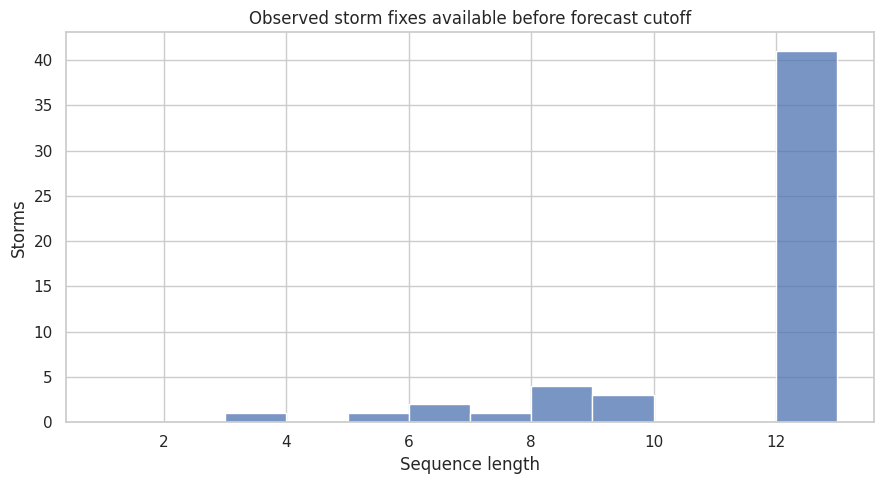

In [ ]:
# 2.4 Figure: pre-cutoff sequence availability
if len(seq_quality):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(
        seq_quality.observed_steps, bins=range(1, CFG["sequence_steps"] + 2), ax=ax
    )
    ax.set(
        title="Observed storm fixes available before forecast cutoff",
        xlabel="Sequence length",
        ylabel="Storms",
    )
    plot_finish("26_seq_availability")
else:
    print("SKIPPED: no selected storm sequences available.")

## 3. Province-level target construction

Construct **observed outcome severity**, not an arbitrary label based on cyclone wind category. The composite is made from log-transformed, training-only standardised (percentile-ranked) affected people, damaged/destroyed houses, deaths, and nominal economic loss. Economic values should ideally be CPI-deflated and exposure-normalised; the notebook provides an auditable initial baseline and highlights this limitation. Missing outcome components are not automatically zero. **All training-only transformations and label thresholds are fitted on training storms only.**

An impact-only source typically lists reported affected provinces; missing province–storm combinations are **unobserved**, not confirmed 'Low' or 'zero'. We do not fabricate the full 81-province × storm grid as labelled negatives.

In [ ]:
# 3.1 Canonical province naming and duplicate impact records
ALIASES = {
    "metro manila": "metropolitan manila",
    "ncr": "metropolitan manila",
    "compostela valley": "davao de oro",
    "north cotabato": "cotabato",
}


def norm_province(s):
    s = re.sub(r"\s+", " ", str(s).lower().strip())
    return ALIASES.get(s, s)


observed = imp.copy()
if (
    observed[["storm_key", "province"]].isna().any().any()
    or observed["storm_key"].astype(str).str.strip().eq("").any()
    or observed["province"].astype(str).str.strip().eq("").any()
):
    raise ValueError(
        "Impact records contain missing storm keys or provinces; inspect the source data."
    )
observed["province_key"] = observed.province.map(norm_province)
impact_fields = [
    "deaths",
    "affected",
    "houses_destroyed",
    "houses_damaged",
    "total_houses",
    "infrastructure_php",
    "agriculture_php",
    "economic_php",
    "housing_count",
]
missing = set(impact_fields) - set(observed.columns)
if missing:
    raise ValueError(f"Impact data is missing columns: {sorted(missing)}")
keys = ["storm_key", "province_key"]
duplicate_rows = observed[observed.duplicated(keys, keep=False)].copy()
if not duplicate_rows.empty:
    metadata_fields = [
        c
        for c in observed.columns
        if c not in keys + impact_fields + ["province", "event_id"]
    ]
    conflicts = (
        duplicate_rows.groupby(keys, dropna=False)[metadata_fields]
        .nunique(dropna=False)
        .gt(1)
    )
    if conflicts.any().any():
        display(conflicts[conflicts.any(axis=1)])
        raise ValueError(
            "Duplicate impact records contain conflicting metadata; inspect before combining."
        )
    print(
        "Combining duplicate storm-province pairs using the maximum of each impact field:",
        duplicate_rows[keys].drop_duplicates().shape[0],
        "| Source rows:",
        len(duplicate_rows),
    )
    display(duplicate_rows.sort_values(keys))
    aggregations = {
        c: ("max" if c in impact_fields else "first")
        for c in observed.columns
        if c not in keys
    }
    observed = observed.groupby(keys, as_index=False, sort=False, dropna=False).agg(
        aggregations
    )
    print(
        "Maximum-per-field values are assumptions, not verified reconstructions of the original reports."
    )
observed["event_id"] = observed.storm_key + "__" + observed.province_key
for c in ["affected", "housing_count", "deaths", "economic_php"]:
    observed.loc[observed[c] < 0, c] = np.nan
print("Observed event rows:", len(observed), "missing outcome matrix:")
display(observed[["affected", "housing_count", "deaths", "economic_php"]].isna().sum())

Combining duplicate storm-province pairs using the maximum of each impact field: 5 | Source rows: 10


,storm_name,province,deaths,affected,houses_destroyed,houses_damaged,total_houses,infrastructure_php,agriculture_php,year,category,economic_php,housing_count,storm_key,province_key
1234,Auring,Surigao del Sur,0.0,0.0,1.0,0.0,1,4.940000e+06,1.636583e+07,2017,Tropical depression,2.130583e+07,1.0,auring_2017,surigao del sur
1240,Auring,Surigao del Sur,0.0,9597.0,0.0,0.0,0,4.940000e+06,1.636583e+07,2017,Tropical depression,2.130583e+07,0.0,auring_2017,surigao del sur
678,Koppu,Benguet,18.0,0.0,0.0,0.0,0,8.786653e+07,1.838275e+08,2015,Very strong typhoon,2.716940e+08,0.0,koppu_2015,benguet
693,Koppu,Benguet,0.0,8018.0,127.0,862.0,989,8.786653e+07,1.838275e+08,2015,Very strong typhoon,2.716940e+08,989.0,koppu_2015,benguet
679,Koppu,Ifugao,3.0,0.0,43.0,499.0,542,1.089154e+07,3.094820e+07,2015,Very strong typhoon,4.183974e+07,542.0,koppu_2015,ifugao
694,Koppu,Ifugao,0.0,2602.0,0.0,0.0,0,1.089154e+07,3.094820e+07,2015,Very strong typhoon,4.183974e+07,0.0,koppu_2015,ifugao
988,Mangkhut,Ifugao,0.0,5990.0,26.0,686.0,712,2.110800e+08,1.383669e+09,2018,Violent typhoon,1.594749e+09,712.0,mangkhut_2018,ifugao
992,Mangkhut,Ifugao,0.0,0.0,0.0,0.0,0,2.110800e+08,1.383669e+09,2018,Violent typhoon,1.594749e+09,0.0,mangkhut_2018,ifugao
903,Tembin,Zamboanga Sibugay,0.0,18202.0,22.0,0.0,22,0.000000e+00,6.178949e+07,2017,Strong typhoon,6.178949e+07,22.0,tembin_2017,zamboanga sibugay
920,Tembin,Zamboanga Sibugay,5.0,0.0,0.0,0.0,0,0.000000e+00,6.178949e+07,2017,Strong typhoon,6.178949e+07,0.0,tembin_2017,zamboanga sibugay


Maximum-per-field values are assumptions, not verified reconstructions of the original reports.
Observed event rows: 1261 missing outcome matrix:


,0
affected,0
housing_count,0
deaths,0
economic_php,0


In [ ]:
# 3.2 Data coverage and supervised eligibility
outcome_cols = ["affected", "housing_count", "deaths", "economic_php"]
observed["outcome_complete"] = observed[outcome_cols].notna().all(axis=1)
observed["has_selected_sequence"] = observed.storm_key.isin(seq_store)
work = observed[observed.outcome_complete & observed.has_selected_sequence].copy()
if globals().get("USE_ASSUMED_ZIP_IMAGES", False):
    work = work[work.storm_key.isin(zip_manifest.storm_key)].copy()
    print("Using assumed ZIP-image matches and landfall anchors for all models.")
print("Eligible supervised rows:", len(work), "storms:", work.storm_key.nunique())
display(
    pd.DataFrame(
        {
            "stage": [
                "impact records",
                "complete impact records",
                "selected sequence + complete impact",
            ],
            "n": [len(observed), observed.outcome_complete.sum(), len(work)],
        }
    )
)

Using assumed ZIP-image matches and landfall anchors for all models.
Eligible supervised rows: 979 storms: 53


,stage,n
0,impact records,1261
1,complete impact records,1261
2,selected sequence + complete impact,979


In [ ]:
# 3.3 Storm-group split BEFORE fitting score percentiles / preprocessing
# ⚠️ REVIEW: 65/20/15 may be unstable on small storm counts. Chronological holdout is a valuable sensitivity test.
if work.storm_key.nunique() < 8:
    raise ValueError(
        "Insufficient eligible storms to train. Check selected sequences, images and outcome coverage."
    )
group_ids = (
    work[["storm_key", "year"]].drop_duplicates().sort_values(["year", "storm_key"])
)
# Optional: replace with chronological storm partition for distribution-shift study.
all_storms = group_ids.storm_key.to_numpy()
rng = np.random.default_rng(SEED)
rng.shuffle(all_storms)
n_train = max(1, int(round(len(all_storms) * CFG["train_frac"])))
n_val = max(1, int(round(len(all_storms) * CFG["val_frac"])))
train_storms = set(all_storms[:n_train])
val_storms = set(all_storms[n_train : n_train + n_val])
test_storms = set(all_storms[n_train + n_val :])
assert train_storms and val_storms and test_storms
assert not (
    train_storms & val_storms or train_storms & test_storms or val_storms & test_storms
)
work["split"] = np.select(
    [work.storm_key.isin(train_storms), work.storm_key.isin(val_storms)],
    ["train", "val"],
    "test",
)
print("Storm splits:", work.groupby("split").storm_key.nunique().to_dict())
print("Province-event splits:", work.split.value_counts().to_dict())

Storm splits: {'test': 8, 'train': 34, 'val': 11}
Province-event splits: {'train': 572, 'val': 221, 'test': 186}


In [ ]:
# 3.4 Composite score, fit percentile ECDF on TRAIN ONLY; then TRAIN-ONLY thresholds
# NOTE: weights / raw vs per-capita indicators change scientific meaning.
from scipy.stats import rankdata

weights = CFG["impact_weights"]
score_fields = {
    "affected": "affected",
    "houses": "housing_count",
    "deaths": "deaths",
    "economic": "economic_php",
}
reference = {}
for key, col in score_fields.items():
    reference[key] = np.sort(
        np.log1p(work.loc[work.split == "train", col].clip(lower=0).dropna().values)
    )
    assert len(reference[key]) > 0
    x = np.log1p(work[col].clip(lower=0).to_numpy())
    work["rank_" + key] = np.searchsorted(reference[key], x, side="right") / len(
        reference[key]
    )
work["impact_score"] = sum(weights[k] * work["rank_" + k] for k in weights)
q1, q2 = np.quantile(
    work.loc[work.split == "train", "impact_score"], CFG["label_quantiles"]
)
assert q1 < q2, "Train label thresholds collapse; revise composite or class scheme."
work["target"] = np.select(
    [work.impact_score <= q1, work.impact_score <= q2], [0, 1], default=2
).astype(int)
label_meta = {
    "thresholds": [float(q1), float(q2)],
    "weights": weights,
    "quantiles": CFG["label_quantiles"],
}
print("Training-only score thresholds:", label_meta["thresholds"])
display(pd.crosstab(work.split, work.target))

Training-only score thresholds: [0.5096809440559441, 0.6785708041958042]


target,0,1,2
split,,,
test,42,50,94
train,189,194,189
val,62,62,97


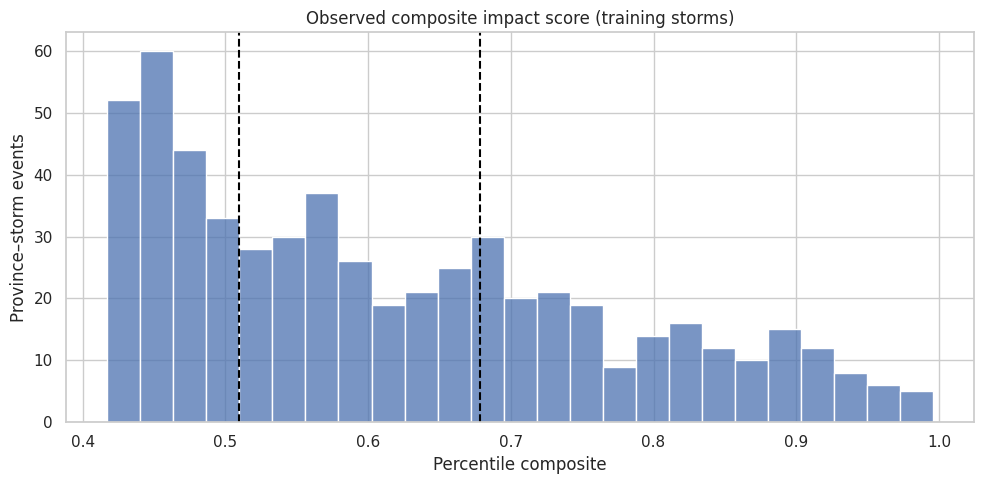

In [ ]:
# 3.5 Figure: training-only outcome severity score
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(work.loc[work.split == "train", "impact_score"], bins=25, ax=ax)
for q in [q1, q2]:
    ax.axvline(q, linestyle="--", color="black")
ax.set(
    title="Observed composite impact score (training storms)",
    xlabel="Percentile composite",
    ylabel="Province–storm events",
)
plot_finish("27_train_score")

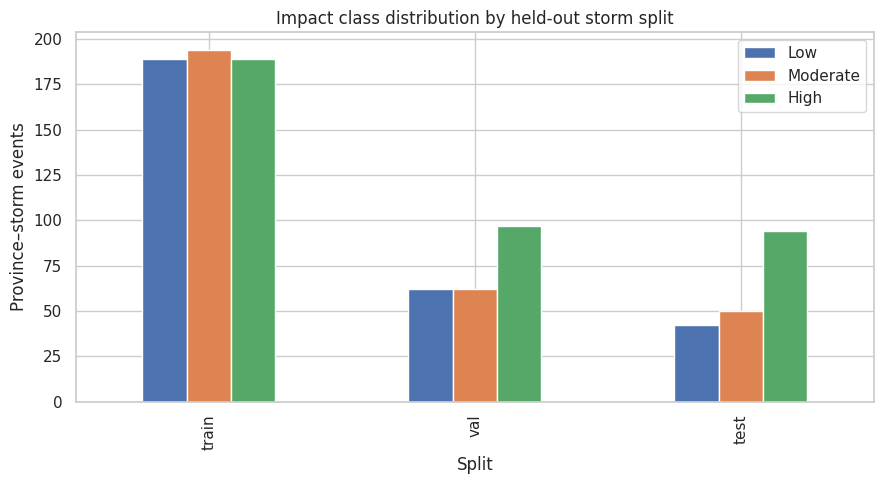

In [ ]:
# 3.6 Figure: labels across train, validation and test
counts = pd.crosstab(work.split, work.target).reindex(
    index=["train", "val", "test"], columns=[0, 1, 2], fill_value=0
)
fig, ax = plt.subplots(figsize=(9, 5))
counts.plot(kind="bar", ax=ax)
ax.legend(CLASSES)
ax.set(
    title="Impact class distribution by held-out storm split",
    xlabel="Split",
    ylabel="Province–storm events",
)
plot_finish("28_split_classes")

## 4. Feature engineering: XGBoost hazard–exposure–vulnerability baseline

Weather input uses complete days before the cutoff, but NASA POWER reanalysis and the Copernicus terrain summary are retrospective proxies whose real-time availability is unverified. Updated 2015 poverty estimates are used for 2010–2017 storms and updated 2018 estimates for 2018–2020 storms; this includes future information for 2010–2014 and does not establish timely publication for later storms. The 2020 housing census is used as a retrospective proxy for all storm years and may reflect post-storm reconstruction. No observed impact outcome, label derivative, post-cutoff rainfall, or post-storm satellite image is directly used as a predictor.

The baseline is hazard-heavy until exposure/vulnerability joins are verified. Province latitude and longitude are **not sufficient proxies** for vulnerability. As-of population joins require reconciliation of historical city/province rows. Missing features must remain missing, with clear coverage reporting.

In [ ]:
# 4.1 Build stable province centroids
cent = pd.read_csv(ROOT / "nasa_power/province_centroids.csv")
cent["province_key"] = cent.province.map(norm_province)
cent = cent[["province_key", "lon", "lat"]].drop_duplicates("province_key")
work = work.merge(cent, on="province_key", how="left", validate="many_to_one")
print("Centroid match rate:", work.lat.notna().mean())
display(work[work.lat.isna()].province.value_counts().head(15))

Centroid match rate: 0.9989785495403473


,count
province,
Davao Occidental,1


In [ ]:
# 4.2 Storm hazard features available no later than cutoff
# Convert track sequences to summary values and calculate minimum proximity to province centroids.
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0088
    a = np.radians(lat1)
    b = np.radians(lat2)
    dl = b - a
    dx = np.radians(lon2 - lon1)
    v = np.sin(dl / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dx / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(np.clip(v, 0, 1)))


def hazard_for_row(r):
    arr = seq_store[r.storm_key]
    out = {
        "wind_last_kt": arr[-1, 2],
        "wind_max_pre_kt": np.nanmax(arr[:, 2])
        if np.isfinite(arr[:, 2]).any()
        else np.nan,
        "pressure_last_hpa": arr[-1, 3],
        "track_steps": len(arr),
        "storm_lat_last": arr[-1, 0],
        "storm_lon_last": arr[-1, 1],
    }
    if pd.notna(r.lat) and pd.notna(r.lon):
        out["distance_min_pre_km"] = np.nanmin(
            haversine_km(r.lat, r.lon, arr[:, 0], arr[:, 1])
        )
        out["distance_last_pre_km"] = haversine_km(r.lat, r.lon, arr[-1, 0], arr[-1, 1])
    else:
        out["distance_min_pre_km"] = out["distance_last_pre_km"] = np.nan
    return pd.Series(out)


haz = work.apply(hazard_for_row, axis=1)
work = pd.concat([work.reset_index(drop=True), haz.reset_index(drop=True)], axis=1)

In [ ]:
# 4.3 Historical as-of census exposure — conservative name matching
# ⚠️ REVIEW: only unambiguous province-wide values are used; urban split rows (e.g. Benguet excluding Baguio) need manual rollup.
census["province_key"] = census.province.map(norm_province)
census["is_province_like"] = census.province_raw.str.startswith("....", na=False)
census_prov = census[census.is_province_like].copy()
census_prov = census_prov[
    ~census_prov.province.str.contains(
        "excluding|City of|Baguio City", case=False, na=False
    )
]
census_prov = census_prov[~census_prov.duplicated("province_key", keep=False)]
lookup = census_prov.set_index("province_key")[["2000", "2010", "2015"]].to_dict(
    "index"
)


def historical_pop(r):
    z = lookup.get(r.province_key)
    if z is None:
        return np.nan
    ref = "2015" if r.year >= 2015 else "2010" if r.year >= 2010 else "2000"
    return z[ref]


work["population_asof"] = work.apply(historical_pop, axis=1)
work["population_log"] = np.log1p(work.population_asof)
print("As-of population coverage:", work.population_asof.notna().mean())

As-of population coverage: 0.7660878447395302


In [ ]:
# 4.3a Retrospective weather, terrain, poverty, and housing features
import hashlib

WEATHER_INPUTS = ["PRECTOTCORR", "WS10M", "RH2M"]
WEATHER_FEATURES = ["rain_3day_sum_mm", "wind_3day_mean_ms", "humidity_3day_mean_pct"]
TERRAIN_FEATURES = ["elevation_mean_m", "slope_mean_deg", "low_10m_share_land_pct"]
POVERTY_FEATURES = ["poverty_incidence_pct"]
HOUSING_FEATURES = ["light_roof_share", "light_wall_share", "light_both_share"]
new_features = WEATHER_FEATURES + TERRAIN_FEATURES + POVERTY_FEATURES + HOUSING_FEATURES
if set(new_features) & set(work.columns):
    raise ValueError(
        "Expanded features already exist; rerun from cell 3.2 before rebuilding them."
    )
if not power_files:
    raise FileNotFoundError("No NASA POWER files found in the nasa_power folder.")
for path in power_files:
    with open(path, encoding="utf-8-sig") as handle:
        header = "".join(handle.readline() for _ in range(5))
    if " in LST" not in header:
        raise ValueError(f"Expected NASA POWER local solar time in {path.name}.")
    longitude_match = re.search(r"longitude\s+([-\d.]+)", header)
    if longitude_match is None or not 0 < float(longitude_match.group(1)) <= 180:
        raise ValueError(
            f"Expected an eastern-hemisphere POWER location in {path.name}."
        )
if not set(WEATHER_INPUTS + ["province_key", "date"]).issubset(power.columns):
    raise ValueError("NASA POWER is missing required weather fields.")
weather_daily = power[["province_key", "date"] + WEATHER_INPUTS].copy()
weather_daily["province_key"] = weather_daily["province_key"].map(norm_province)
if (
    weather_daily["date"].isna().any()
    or weather_daily.duplicated(["province_key", "date"]).any()
):
    raise ValueError(
        "NASA POWER contains invalid dates or duplicate province-day records."
    )
for column in WEATHER_INPUTS:
    weather_daily[column] = pd.to_numeric(weather_daily[column], errors="raise")
    if np.isinf(weather_daily[column]).any():
        raise ValueError(f"Non-finite POWER values in {column}.")
cutoffs = pd.to_datetime(work["storm_key"].map(cutoff_store), utc=True, errors="raise")
if cutoffs.isna().any():
    raise ValueError("Missing cutoff for a supervised event.")
event_days = pd.DataFrame({"row_id": np.repeat(np.arange(len(work)), 3)})
event_days["province_key"] = work["province_key"].to_numpy()[event_days["row_id"]]
end_days = cutoffs.dt.tz_convert(None).dt.normalize().to_numpy()
event_days["date"] = end_days[event_days["row_id"]] - pd.to_timedelta(
    np.tile([1, 2, 3], len(work)), unit="D"
)
event_days = event_days.merge(
    weather_daily, on=["province_key", "date"], how="left", validate="many_to_one"
)
weather_aggregates = event_days.groupby("row_id")[WEATHER_INPUTS].agg(
    ["sum", "mean", "count"]
)
expanded_work = work.reset_index(drop=True).copy()
for source, feature, statistic in zip(
    WEATHER_INPUTS, WEATHER_FEATURES, ["sum", "mean", "mean"]
):
    expanded_work[feature] = weather_aggregates[(source, statistic)].where(
        weather_aggregates[(source, "count")].eq(3)
    )
terrain_path = ROOT / "srtm" / "province_terrain_features.csv"
if not terrain_path.is_file():
    raise FileNotFoundError(
        f"Upload province_terrain_features.csv to the Drive srtm folder: {terrain_path}"
    )
terrain = pd.read_csv(terrain_path)
if not set(["province_key"] + TERRAIN_FEATURES).issubset(terrain.columns):
    raise ValueError("Terrain table is missing required province or feature columns.")
if (
    terrain["province_key"].isna().any()
    or terrain["province_key"].astype(str).str.strip().eq("").any()
):
    raise ValueError("Terrain table contains blank province keys.")
terrain["province_key"] = terrain["province_key"].map(norm_province)
if terrain["province_key"].duplicated().any():
    raise ValueError("Terrain table has duplicate normalized province keys.")
for column in TERRAIN_FEATURES:
    terrain[column] = pd.to_numeric(terrain[column], errors="raise")
    if np.isinf(terrain[column]).any():
        raise ValueError(f"Non-finite terrain values in {column}.")
if (
    not terrain["slope_mean_deg"].dropna().between(0, 90).all()
    or not terrain["low_10m_share_land_pct"].dropna().between(0, 100).all()
):
    raise ValueError("Terrain slope or low-lying land share is out of range.")
expanded_work = expanded_work.merge(
    terrain[["province_key"] + TERRAIN_FEATURES],
    on="province_key",
    how="left",
    validate="many_to_one",
    sort=False,
)
poverty_path = ROOT / "psa_poverty" / "poverty_2015_2018_population.xlsx"
if not poverty_path.is_file():
    raise FileNotFoundError(f"Poverty workbook not found: {poverty_path}")
poverty_raw = pd.read_excel(poverty_path, sheet_name=0, header=None)
if (
    poverty_raw.shape[0] < 8
    or poverty_raw.shape[1] < 5
    or str(poverty_raw.iat[2, 3]).strip() != "Poverty Incidence among Population"
    or str(poverty_raw.iat[3, 3]).strip() != "Estimate (%)"
    or str(poverty_raw.iat[4, 3]).strip() != "2015u"
    or str(poverty_raw.iat[4, 4]).strip() != "2018u"
):
    raise ValueError(
        "Unexpected poverty workbook headers; inspect the source before training."
    )
poverty_table = poverty_raw.iloc[7:, [0, 3, 4]].copy()
poverty_table.columns = ["poverty_geography", "poverty_2015", "poverty_2018"]
poverty_table = poverty_table[poverty_table["poverty_geography"].notna()].copy()


def poverty_key(name):
    name = str(name).replace("*", " ")
    name = re.sub(r"[A-Za-z]?\d*/", " ", name)
    name = re.sub(r"\br\d\b", " ", name, flags=re.IGNORECASE)
    name = re.sub(r"[,\s]+$", "", name)
    key = norm_province(name)
    return {"mt. province": "mountain province", "western samar": "samar"}.get(key, key)


poverty_table["province_key"] = poverty_table["poverty_geography"].map(poverty_key)
poverty_table = poverty_table[
    poverty_table["province_key"].isin(expanded_work["province_key"])
].copy()
if poverty_table["province_key"].duplicated().any():
    raise ValueError(
        "Ambiguous province rows in poverty workbook; inspect names before joining."
    )
for column in ["poverty_2015", "poverty_2018"]:
    values = poverty_table[column]
    parsed = pd.to_numeric(values, errors="coerce")
    if (values.notna() & parsed.isna()).any() or not parsed.dropna().between(
        0, 100
    ).all():
        raise ValueError(f"Invalid poverty incidence values in {column}.")
    poverty_table[column] = parsed
years = pd.to_numeric(expanded_work["year"], errors="raise")
if (
    years.isna().any()
    or not years.between(2010, 2020).all()
    or not years.mod(1).eq(0).all()
):
    raise ValueError(
        "Poverty proxy mapping is defined only for whole storm years 2010–2020."
    )
expanded_work["poverty_reference_year"] = np.where(years <= 2017, 2015, 2018)
expanded_work = expanded_work.merge(
    poverty_table[
        ["province_key", "poverty_geography", "poverty_2015", "poverty_2018"]
    ],
    on="province_key",
    how="left",
    validate="many_to_one",
    sort=False,
)
expanded_work["poverty_incidence_pct"] = expanded_work["poverty_2015"].where(
    expanded_work["poverty_reference_year"].eq(2015), expanded_work["poverty_2018"]
)
expanded_work = expanded_work.drop(columns=["poverty_2015", "poverty_2018"])
housing_path = ROOT / "psa_housing" / "province_housing_features_2020.csv"
housing_workbook = ROOT / "psa_housing" / "housing_roof_wall_census2020.xlsx"
for path in [housing_path, housing_workbook]:
    if not path.is_file():
        raise FileNotFoundError(f"Required housing input not found: {path}")
housing_source_hash = "752dd65f377f69dddc8e8efb432cc23dd68b29922bed7f27b551146f9606ed2f"
housing_table_hash = "241870778f972f7b7ddd4c9e5c407f1e8e905d6726f2481d0268086805cf9205"
for path, expected_hash in [
    (housing_workbook, housing_source_hash),
    (housing_path, housing_table_hash),
]:
    with open(path, "rb") as handle:
        actual_hash = hashlib.sha256(handle.read()).hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(
            f"Housing input differs from the verified source used to create the summary: {path}"
        )
housing = pd.read_csv(housing_path)
housing_columns = [
    "province_key",
    "snapshot_year",
    "unclassified_pct",
] + HOUSING_FEATURES
if not set(housing_columns).issubset(housing.columns):
    raise ValueError("Housing summary is missing required columns.")
if (
    housing["province_key"].isna().any()
    or housing["province_key"].astype(str).str.strip().eq("").any()
):
    raise ValueError("Housing summary contains blank province keys.")
housing["province_key"] = housing["province_key"].map(norm_province)
if housing["province_key"].duplicated().any():
    raise ValueError("Housing summary contains duplicate normalized province keys.")
if not pd.to_numeric(housing["snapshot_year"], errors="raise").eq(2020).all():
    raise ValueError("Housing summary must contain only the 2020 census snapshot.")
for column in HOUSING_FEATURES + ["unclassified_pct"]:
    housing[column] = pd.to_numeric(housing[column], errors="raise")
    if housing[column].isna().any() or not housing[column].between(0, 100).all():
        raise ValueError(f"Invalid housing percentage: {column}")
if (
    housing["light_both_share"]
    > housing[["light_roof_share", "light_wall_share"]].min(axis=1)
).any():
    raise ValueError("The light roof-and-wall share exceeds a marginal share.")
housing = housing.rename(
    columns={
        "snapshot_year": "housing_snapshot_year",
        "unclassified_pct": "housing_unclassified_pct",
    }
)
if "davao del sur" not in set(housing["province_key"]):
    raise ValueError("The combined Davao housing proxy is missing from the summary.")
expanded_work["housing_source_key"] = expanded_work["province_key"].replace(
    {"davao occidental": "davao del sur"}
)
expanded_work = expanded_work.merge(
    housing.rename(columns={"province_key": "housing_source_key"}),
    on="housing_source_key",
    how="left",
    validate="many_to_one",
    sort=False,
)
for feature in new_features:
    if not expanded_work.loc[expanded_work["split"].eq("train"), feature].notna().any():
        raise ValueError(
            f"No training values for {feature}; check source coverage before training."
        )
work = expanded_work
print("Retrospective weather, terrain, poverty, and housing coverage by split:")
display(work.groupby("split")[new_features].count())
print(
    "Poverty reference years:",
    work["poverty_reference_year"].value_counts().sort_index().to_dict(),
)
print(
    "Provinces without poverty estimates:",
    sorted(work.loc[work["poverty_incidence_pct"].isna(), "province_key"].unique()),
)
print(
    "Poverty values are direct workbook geography estimates; separately reported cities are not combined with province estimates."
)
print(
    "Provinces without housing estimates:",
    sorted(work.loc[work["housing_snapshot_year"].isna(), "province_key"].unique()),
)
print(
    "Housing summary uses 2020 municipality totals, including highly urbanised cities. Davao Occidental uses the combined Davao del Sur–Davao Occidental housing proxy, not a separate estimate."
)
print(
    "Poverty and 2020 housing are retrospective proxies: future data and post-storm reconstruction can affect results."
)
print(
    "NASA POWER is reanalysis and terrain is a retrospective surface-model proxy; neither is verified as operationally available at the cutoff."
)

# 4.4 Explicit feature allowlist prevents inadvertent target leakage
FEATURES = (
    [
        "lat",
        "lon",
        "wind_last_kt",
        "wind_max_pre_kt",
        "pressure_last_hpa",
        "track_steps",
        "storm_lat_last",
        "storm_lon_last",
        "distance_min_pre_km",
        "distance_last_pre_km",
        "population_log",
    ]
    + WEATHER_FEATURES
    + TERRAIN_FEATURES
    + POVERTY_FEATURES
    + HOUSING_FEATURES
)
FORBIDDEN = {
    "deaths",
    "affected",
    "housing_count",
    "houses_destroyed",
    "houses_damaged",
    "economic_php",
    "impact_score",
    "target",
    "rank_deaths",
    "rank_affected",
    "rank_houses",
    "rank_economic",
}
assert not (FORBIDDEN & set(FEATURES)), "Outcome leakage in feature selection!"
print("Feature allowlist:", FEATURES)
display(
    work[FEATURES]
    .isna()
    .mean()
    .rename("missing_fraction")
    .sort_values(ascending=False)
    .to_frame()
)

Retrospective weather, terrain, poverty, and housing coverage by split:


,rain_3day_sum_mm,wind_3day_mean_ms,humidity_3day_mean_pct,elevation_mean_m,slope_mean_deg,low_10m_share_land_pct,poverty_incidence_pct,light_roof_share,light_wall_share,light_both_share
split,,,,,,,,,,
test,186,186,186,186,186,186,186,186,186,186
train,571,571,571,571,571,571,571,572,572,572
val,221,221,221,221,221,221,221,221,221,221


Poverty reference years: {2015: 706, 2018: 273}
Provinces without poverty estimates: ['davao occidental']
Poverty values are direct workbook geography estimates; separately reported cities are not combined with province estimates.
Provinces without housing estimates: []
Housing summary uses 2020 municipality totals, including highly urbanised cities. Davao Occidental uses the combined Davao del Sur–Davao Occidental housing proxy, not a separate estimate.
Poverty and 2020 housing are retrospective proxies: future data and post-storm reconstruction can affect results.
NASA POWER is reanalysis and terrain is a retrospective surface-model proxy; neither is verified as operationally available at the cutoff.
Feature allowlist: ['lat', 'lon', 'wind_last_kt', 'wind_max_pre_kt', 'pressure_last_hpa', 'track_steps', 'storm_lat_last', 'storm_lon_last', 'distance_min_pre_km', 'distance_last_pre_km', 'population_log', 'rain_3day_sum_mm', 'wind_3day_mean_ms', 'humidity_3day_mean_pct', 'elevation_mean

,missing_fraction
population_log,0.233912
pressure_last_hpa,0.046987
wind_max_pre_kt,0.046987
wind_last_kt,0.046987
lat,0.001021
lon,0.001021
distance_min_pre_km,0.001021
distance_last_pre_km,0.001021
rain_3day_sum_mm,0.001021
wind_3day_mean_ms,0.001021


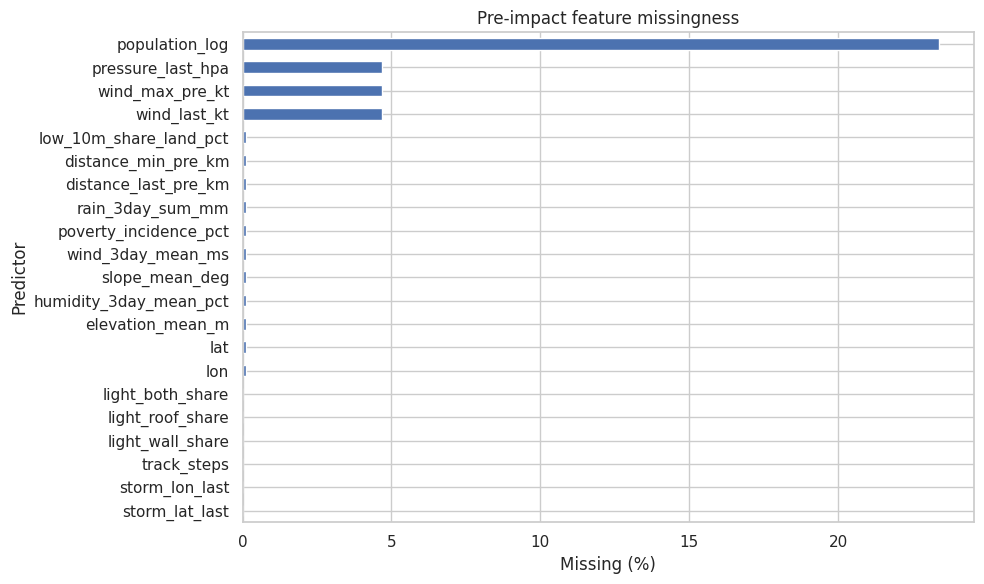

In [ ]:
# 4.5 Figure: pre-impact model feature missingness
fig, ax = plt.subplots(figsize=(10, 6))
(100 * work[FEATURES].isna().mean()).sort_values().plot.barh(ax=ax)
ax.set(title="Pre-impact feature missingness", xlabel="Missing (%)", ylabel="Predictor")
plot_finish("29_model_feature_missingness")

In [ ]:
# 4.6 Prepare splits — imputer fit on TRAIN only; XGBoost also handles NaN natively
train = work[work.split == "train"].copy()
val = work[work.split == "val"].copy()
test = work[work.split == "test"].copy()
Xtr = train[FEATURES].astype("float32")
Xva = val[FEATURES].astype("float32")
Xte = test[FEATURES].astype("float32")
ytr = train.target.to_numpy()
yva = val.target.to_numpy()
yte = test.target.to_numpy()
print("Matrices:", Xtr.shape, Xva.shape, Xte.shape)

Matrices: (572, 21) (221, 21) (186, 21)


## 5. XGBoost: baseline training, validation-based tuning, final test

**Tuning protocol:** select hyperparameters using only train + validation. Freeze the winner and inspect the held-out test once. For a stronger thesis, replace the single validation split with nested grouped cross-validation; never tune repeatedly on the test set.

In [ ]:
# 5.1 Candidate hyperparameters (small grid for Colab; extend deliberately)
XGB_GRID = {
    "n_estimators": [250, 500],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.07],
    "subsample": [0.85],
    "colsample_bytree": [0.85],
    "min_child_weight": [2],
    "reg_lambda": [2],
}
results = []
best_xgb = None
best_val = -np.inf
best_params = None
for params in ParameterGrid(XGB_GRID):
    model = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
        eval_metric="mlogloss",
        **params,
    )
    model.fit(Xtr, ytr, verbose=False)
    pred = model.predict(Xva)
    metric = f1_score(yva, pred, average="macro", zero_division=0)
    results.append({**params, "val_macro_f1": metric})
    if metric > best_val:
        best_val = metric
        best_xgb = model
        best_params = params
xgb_tuning = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
display(xgb_tuning.head(10))
print("BEST:", best_params, "VAL macro-F1:", best_val)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,val_macro_f1
4,0.85,0.07,3,2,250,2,0.85,0.425663
2,0.85,0.03,5,2,250,2,0.85,0.425496
5,0.85,0.07,3,2,500,2,0.85,0.424577
3,0.85,0.03,5,2,500,2,0.85,0.421635
0,0.85,0.03,3,2,250,2,0.85,0.421095
7,0.85,0.07,5,2,500,2,0.85,0.410158
1,0.85,0.03,3,2,500,2,0.85,0.409133
6,0.85,0.07,5,2,250,2,0.85,0.409006


BEST: {'colsample_bytree': 0.85, 'learning_rate': 0.07, 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 250, 'reg_lambda': 2, 'subsample': 0.85} VAL macro-F1: 0.42566304622379386


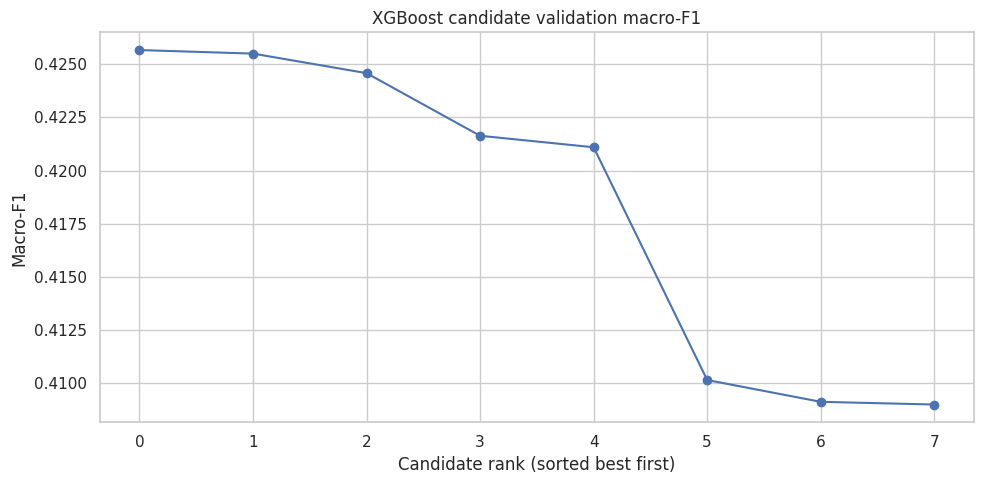

In [ ]:
# 5.2 Figure: XGBoost validation tuning results
fig, ax = plt.subplots(figsize=(10, 5))
xgb_tuning.reset_index(drop=True).val_macro_f1.plot(marker="o", ax=ax)
ax.set(
    title="XGBoost candidate validation macro-F1",
    xlabel="Candidate rank (sorted best first)",
    ylabel="Macro-F1",
)
plot_finish("30_xgb_tuning")

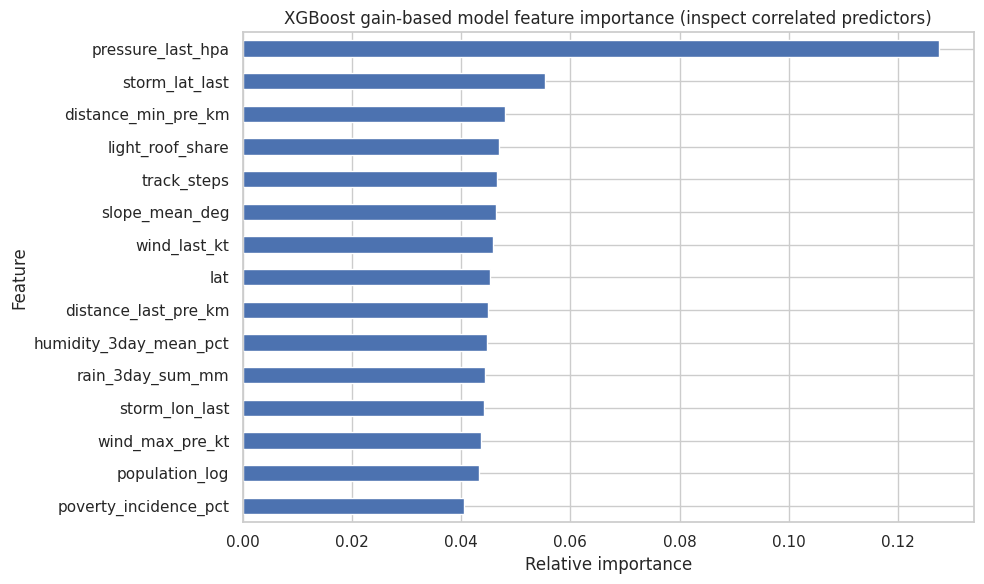

In [ ]:
# 5.3 Figure: XGBoost feature importance
importances = (
    pd.Series(best_xgb.feature_importances_, index=FEATURES).sort_values().tail(15)
)
fig, ax = plt.subplots(figsize=(10, 6))
importances.plot.barh(ax=ax)
ax.set(
    title="XGBoost gain-based model feature importance (inspect correlated predictors)",
    xlabel="Relative importance",
    ylabel="Feature",
)
plot_finish("31_xgb_importance")

### 5.3a Hazard–exposure–vulnerability contribution analysis

Train comparable XGBoost models on the same province–storm rows and storm splits, using fixed hyperparameters chosen before this comparison (not the full model's validation-selected parameters). Nested additions examine storm hazard, province location/distance and weather, population, then terrain/poverty/housing. Leave-one-group-out models complement the order-dependent additions. Terrain is a geographic proxy grouped with vulnerability here, not a direct measure of social vulnerability. Correlated inputs can share predictive information. Validation and the previously inspected test results are exploratory; these comparisons measure predictive contribution, not causation. Poverty and housing use retrospective future information, weather is reanalysis, and the raw-count outcome can favor population-related predictors.

In [ ]:
# 5.3b Fixed-parameter XGBoost feature-group experiments
HEV_GROUPS = {
    "storm_hazard": [
        "wind_last_kt",
        "wind_max_pre_kt",
        "pressure_last_hpa",
        "track_steps",
        "storm_lat_last",
        "storm_lon_last",
    ],
    "province_location_distance": [
        "lat",
        "lon",
        "distance_min_pre_km",
        "distance_last_pre_km",
    ],
    "weather": list(WEATHER_FEATURES),
    "population": ["population_log"],
    "terrain": list(TERRAIN_FEATURES),
    "poverty": list(POVERTY_FEATURES),
    "housing": list(HOUSING_FEATURES),
}
grouped_features = [feature for group in HEV_GROUPS.values() for feature in group]
if len(grouped_features) != len(set(grouped_features)) or set(grouped_features) != set(
    FEATURES
):
    raise ValueError("HEV feature groups must partition the XGBoost feature allowlist.")
HEV_EXPERIMENTS = {
    "storm_hazard_only": ["storm_hazard"],
    "add_local_hazard": ["storm_hazard", "province_location_distance", "weather"],
    "add_exposure": [
        "storm_hazard",
        "province_location_distance",
        "weather",
        "population",
    ],
    "full_hev": list(HEV_GROUPS),
}
for group in HEV_GROUPS:
    if group != "storm_hazard":
        HEV_EXPERIMENTS[f"without_{group}"] = [
            name for name in HEV_GROUPS if name != group
        ]
HEV_PARAMS = {
    "n_estimators": 250,
    "max_depth": 3,
    "learning_rate": 0.07,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "min_child_weight": 2,
    "reg_lambda": 2,
}
HEV_FEATURES = {
    name: [feature for group in groups for feature in HEV_GROUPS[group]]
    for name, groups in HEV_EXPERIMENTS.items()
}
hev_predictions = {}
hev_metric_rows = []
for name, features in HEV_FEATURES.items():
    model = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
        eval_metric="mlogloss",
        **HEV_PARAMS,
    )
    model.fit(train[features].astype("float32"), ytr, verbose=False)
    for split_name, split_data in [("validation", val), ("test", test)]:
        truth = split_data["target"].to_numpy()
        predicted = model.predict(split_data[features].astype("float32"))
        hev_predictions[(split_name, name)] = predicted
        recall = precision_recall_fscore_support(
            truth, predicted, labels=[0, 1, 2], zero_division=0
        )
        hev_metric_rows.append(
            {
                "split": split_name,
                "experiment": name,
                "rows": len(truth),
                "storms": split_data["storm_key"].nunique(),
                "macro_f1": f1_score(
                    truth, predicted, labels=[0, 1, 2], average="macro", zero_division=0
                ),
                "accuracy": accuracy_score(truth, predicted),
                "low_recall": recall[1][0],
                "moderate_recall": recall[1][1],
                "high_recall": recall[1][2],
                "low_support": recall[3][0],
                "moderate_support": recall[3][1],
                "high_support": recall[3][2],
            }
        )
hev_metrics = pd.DataFrame(hev_metric_rows)
print(
    "Feature-group performance (validation and previously inspected test are exploratory):"
)
display(hev_metrics)
hev_metrics.to_csv(OUT / "hev_ablation_metrics.csv", index=False)
with open(OUT / "hev_ablation_config.json", "w") as f:
    json.dump(
        {
            "groups": HEV_GROUPS,
            "experiments": HEV_EXPERIMENTS,
            "parameters": HEV_PARAMS,
            "seed": SEED,
        },
        f,
        indent=2,
    )

Feature-group performance (validation and previously inspected test are exploratory):


,split,experiment,rows,storms,macro_f1,accuracy,low_recall,moderate_recall,high_recall,low_support,moderate_support,high_support
0,validation,storm_hazard_only,221,11,0.384494,0.520362,0.500000,0.000000,0.865979,62,62,97
1,test,storm_hazard_only,186,8,0.306142,0.311828,0.333333,0.320000,0.297872,42,50,94
2,validation,add_local_hazard,221,11,0.443663,0.447964,0.370968,0.516129,0.453608,62,62,97
3,test,add_local_hazard,186,8,0.338495,0.360215,0.476190,0.200000,0.393617,42,50,94
4,validation,add_exposure,221,11,0.426639,0.443439,0.306452,0.435484,0.536082,62,62,97
5,test,add_exposure,186,8,0.376484,0.408602,0.523810,0.200000,0.468085,42,50,94
6,validation,full_hev,221,11,0.409063,0.425339,0.274194,0.483871,0.484536,62,62,97
7,test,full_hev,186,8,0.315157,0.344086,0.404762,0.160000,0.414894,42,50,94
8,validation,without_province_location_distance,221,11,0.433567,0.443439,0.338710,0.500000,0.474227,62,62,97
9,test,without_province_location_distance,186,8,0.368327,0.408602,0.428571,0.180000,0.521277,42,50,94


In [ ]:
# 5.3c Paired macro-F1 differences and storm-cluster bootstrap intervals
HEV_COMPARISONS = [
    ("add_local_hazard", "storm_hazard_only"),
    ("add_exposure", "add_local_hazard"),
    ("full_hev", "add_exposure"),
] + [
    ("full_hev", f"without_{group}") for group in HEV_GROUPS if group != "storm_hazard"
]
hev_difference_rows = []
for split_name, split_data in [("validation", val), ("test", test)]:
    truth = split_data["target"].to_numpy()
    storm_ids = split_data["storm_key"].to_numpy()
    unique_storms = pd.unique(storm_ids)
    if len(unique_storms) == 0:
        raise ValueError(f"No storms available for HEV comparison: {split_name}")
    storm_rows = [np.flatnonzero(storm_ids == storm) for storm in unique_storms]
    rng_hev = np.random.default_rng(SEED)
    bootstrap_rows = [
        np.concatenate(
            [
                storm_rows[i]
                for i in rng_hev.integers(0, len(storm_rows), size=len(storm_rows))
            ]
        )
        for _ in range(500)
    ]
    for added, reference_name in HEV_COMPARISONS:
        pred_added = hev_predictions[(split_name, added)]
        pred_reference = hev_predictions[(split_name, reference_name)]

        def hev_f1(indices, predictions):
            return f1_score(
                truth[indices],
                predictions[indices],
                labels=[0, 1, 2],
                average="macro",
                zero_division=0,
            )

        all_rows = np.arange(len(truth))
        delta = hev_f1(all_rows, pred_added) - hev_f1(all_rows, pred_reference)
        boot_delta = [
            hev_f1(rows, pred_added) - hev_f1(rows, pred_reference)
            for rows in bootstrap_rows
        ]
        lower, upper = np.quantile(boot_delta, [0.025, 0.975])
        hev_difference_rows.append(
            {
                "split": split_name,
                "model": added,
                "reference": reference_name,
                "delta_macro_f1": delta,
                "bootstrap_2_5_pct": lower,
                "bootstrap_97_5_pct": upper,
                "storm_count": len(unique_storms),
                "bootstrap_replicates": len(bootstrap_rows),
            }
        )
hev_differences = pd.DataFrame(hev_difference_rows)
print(
    "Positive differences favor the first model. Intervals are exploratory, especially with few storms."
)
display(hev_differences)
hev_differences.to_csv(OUT / "hev_ablation_paired_differences.csv", index=False)

Positive differences favor the first model. Intervals are exploratory, especially with few storms.


,split,model,reference,delta_macro_f1,bootstrap_2_5_pct,bootstrap_97_5_pct,storm_count,bootstrap_replicates
0,validation,add_local_hazard,storm_hazard_only,0.059169,-0.017819,0.128566,11,500
1,validation,add_exposure,add_local_hazard,-0.017024,-0.054534,0.019760,11,500
2,validation,full_hev,add_exposure,-0.017576,-0.062600,0.037941,11,500
3,validation,full_hev,without_province_location_distance,-0.024504,-0.063099,0.030853,11,500
4,validation,full_hev,without_weather,-0.066891,-0.151764,0.016450,11,500
5,validation,full_hev,without_population,-0.022832,-0.056712,0.019459,11,500
6,validation,full_hev,without_terrain,0.002453,-0.026448,0.037804,11,500
7,validation,full_hev,without_poverty,0.007109,-0.028748,0.064518,11,500
8,validation,full_hev,without_housing,-0.004470,-0.042471,0.039543,11,500
9,test,add_local_hazard,storm_hazard_only,0.032353,-0.095597,0.225947,8,500


In [ ]:
# 5.3d Within-storm classification and ordering of different observed impact classes
hev_storm_rows = []
hev_province_predictions = []
for split_name, split_data in [("validation", val), ("test", test)]:
    for name in HEV_EXPERIMENTS:
        scored = (
            split_data[["event_id", "storm_key", "province", "target"]]
            .copy()
            .reset_index(drop=True)
        )
        scored["predicted"] = hev_predictions[(split_name, name)]
        scored["split"] = split_name
        scored["experiment"] = name
        scored["observed_class"] = scored["target"].map(dict(enumerate(CLASSES)))
        scored["predicted_class"] = scored["predicted"].map(dict(enumerate(CLASSES)))
        hev_province_predictions.append(scored)
        for storm, group in scored.groupby("storm_key", sort=True):
            actual = group["target"].to_numpy()
            predicted = group["predicted"].to_numpy()
            first, second = np.triu_indices(len(group), k=1)
            observed_difference = actual[first] - actual[second]
            predicted_difference = predicted[first] - predicted[second]
            different = observed_difference != 0
            eligible_pairs = int(different.sum())
            correct_pairs = int(
                ((observed_difference * predicted_difference > 0) & different).sum()
            )
            tied_pairs = int(((predicted_difference == 0) & different).sum())
            hev_storm_rows.append(
                {
                    "split": split_name,
                    "experiment": name,
                    "storm_key": storm,
                    "provinces": len(group),
                    "observed_classes": len(np.unique(actual)),
                    "province_accuracy": accuracy_score(actual, predicted),
                    "different_class_pairs": eligible_pairs,
                    "correctly_ordered_pairs": correct_pairs,
                    "tied_prediction_pairs": tied_pairs,
                    "pair_order_accuracy": correct_pairs / eligible_pairs
                    if eligible_pairs
                    else np.nan,
                }
            )
hev_within_storm = pd.DataFrame(hev_storm_rows)
hev_pair_summary = hev_within_storm.groupby(
    ["split", "experiment"], as_index=False
).agg(
    storms=("storm_key", "size"),
    storms_with_different_classes=("pair_order_accuracy", "count"),
    mean_storm_pair_order_accuracy=("pair_order_accuracy", "mean"),
    different_class_pairs=("different_class_pairs", "sum"),
    correctly_ordered_pairs=("correctly_ordered_pairs", "sum"),
    tied_prediction_pairs=("tied_prediction_pairs", "sum"),
)
denominator = hev_pair_summary["different_class_pairs"].replace(0, np.nan)
hev_pair_summary["pooled_pair_order_accuracy"] = (
    hev_pair_summary["correctly_ordered_pairs"] / denominator
)
print(
    "Within each storm, pairs with different observed classes are correctly ordered only when predicted classes rank in the same direction; prediction ties count as incorrect. Storms without such pairs have no pair accuracy."
)
display(hev_pair_summary)
display(hev_within_storm)
hev_province_predictions = pd.concat(hev_province_predictions, ignore_index=True)
print("Example held-out province predictions from the full model:")
display(
    hev_province_predictions.loc[
        (hev_province_predictions["split"] == "test")
        & (hev_province_predictions["experiment"] == "full_hev")
    ].head(25)
)
hev_pair_summary.to_csv(OUT / "hev_within_storm_summary.csv", index=False)
hev_within_storm.to_csv(OUT / "hev_within_storm_details.csv", index=False)
hev_province_predictions.to_csv(OUT / "hev_province_predictions.csv", index=False)

Within each storm, pairs with different observed classes are correctly ordered only when predicted classes rank in the same direction; prediction ties count as incorrect. Storms without such pairs have no pair accuracy.


,split,experiment,storms,storms_with_different_classes,mean_storm_pair_order_accuracy,different_class_pairs,correctly_ordered_pairs,tied_prediction_pairs,pooled_pair_order_accuracy
0,test,add_exposure,8,8,0.217621,1443,436,696,0.302148
1,test,add_local_hazard,8,8,0.233444,1443,388,635,0.268884
2,test,full_hev,8,8,0.272569,1443,493,576,0.341649
3,test,storm_hazard_only,8,8,0.000000,1443,0,1443,0.000000
4,test,without_housing,8,8,0.243530,1443,457,638,0.316701
5,test,without_population,8,8,0.250694,1443,470,587,0.325710
6,test,without_poverty,8,8,0.249599,1443,493,597,0.341649
7,test,without_province_location_distance,8,8,0.331598,1443,553,617,0.383229
8,test,without_terrain,8,8,0.261956,1443,479,637,0.331947
9,test,without_weather,8,8,0.396437,1443,532,517,0.368676


,split,experiment,storm_key,provinces,observed_classes,province_accuracy,different_class_pairs,correctly_ordered_pairs,tied_prediction_pairs,pair_order_accuracy
0,validation,storm_hazard_only,conson_2010,15,3,0.466667,72,0,72,0.000000
1,validation,storm_hazard_only,ferdie_2012,8,2,0.875000,7,0,7,0.000000
2,validation,storm_hazard_only,hagupit_2014,39,3,0.435897,431,0,431,0.000000
3,validation,storm_hazard_only,haikui_2017,9,2,0.666667,18,0,18,0.000000
4,validation,storm_hazard_only,kammuri_2019,29,3,0.517241,255,0,255,0.000000
...,...,...,...,...,...,...,...,...,...,...
185,test,without_housing,krosa_2013,5,2,0.000000,6,0,4,0.000000
186,test,without_housing,megi_2010,24,3,0.541667,101,51,27,0.504950
187,test,without_housing,sarika_2016,27,3,0.296296,236,77,95,0.326271
188,test,without_housing,vamco_2020,35,3,0.142857,266,86,137,0.323308


Example held-out province predictions from the full model:


,event_id,storm_key,province,target,predicted,split,experiment,observed_class,predicted_class
2768,megi_2010__metropolitan manila,megi_2010,Metro Manila,0,1,test,full_hev,Low,Moderate
2769,megi_2010__ilocos norte,megi_2010,Ilocos Norte,2,0,test,full_hev,High,Low
2770,megi_2010__ilocos sur,megi_2010,Ilocos Sur,2,0,test,full_hev,High,Low
2771,megi_2010__la union,megi_2010,La Union,2,2,test,full_hev,High,High
2772,megi_2010__pangasinan,megi_2010,Pangasinan,2,2,test,full_hev,High,High
2773,megi_2010__cagayan,megi_2010,Cagayan,2,1,test,full_hev,High,Moderate
2774,megi_2010__isabela,megi_2010,Isabela,2,2,test,full_hev,High,High
2775,megi_2010__nueva vizcaya,megi_2010,Nueva Vizcaya,2,2,test,full_hev,High,High
2776,megi_2010__quirino,megi_2010,Quirino,2,2,test,full_hev,High,High
2777,megi_2010__aurora,megi_2010,Aurora,1,2,test,full_hev,Moderate,High


## 6. GRU: pre-cutoff IBTrACS storm sequences

A storm sequence is repeated for its provinces, while province-level context is appended to the GRU prediction head. All provinces belonging to a storm stay in the same split. Left-padded sequence positions are masked using packed sequences **after** ordering valid steps; features are normalised on training storms only.

In [ ]:
# 6.1 Fit GRU sequence scaler on training storm tracks only
seq_cols = IB_FEATURES
train_tracks = np.concatenate(
    [seq_store[k] for k in train_storms if k in seq_store], axis=0
)
seq_imputer = SimpleImputer(strategy="median", add_indicator=False)
train_tracks_fill = seq_imputer.fit_transform(train_tracks)
seq_scaler = StandardScaler().fit(train_tracks_fill)
# province context includes the same pre-cutoff baseline features, excluding storm sequencing redundant fields if desired
CTX_FEATURES = (
    ["lat", "lon", "population_log", "distance_min_pre_km"]
    + WEATHER_FEATURES
    + TERRAIN_FEATURES
    + POVERTY_FEATURES
    + HOUSING_FEATURES
)
ctx_imputer = SimpleImputer(strategy="median").fit(train[CTX_FEATURES])
ctx_scaler = StandardScaler().fit(ctx_imputer.transform(train[CTX_FEATURES]))


def collate_table(df):
    all_seq = np.zeros((len(df), CFG["sequence_steps"], len(seq_cols)), dtype="float32")
    lengths = []
    for i, k in enumerate(df.storm_key):
        x = seq_store[k][-CFG["sequence_steps"] :]
        z = seq_scaler.transform(seq_imputer.transform(x))
        all_seq[i, : len(z), :] = z
        lengths.append(len(z))
    ctx = ctx_scaler.transform(ctx_imputer.transform(df[CTX_FEATURES])).astype(
        "float32"
    )
    return (
        torch.tensor(all_seq),
        torch.tensor(lengths),
        torch.tensor(ctx),
        torch.tensor(df.target.to_numpy(), dtype=torch.long),
    )


class EventTensorDataset(Dataset):
    def __init__(self, df):
        self.seq, self.length, self.ctx, self.y = collate_table(df)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.seq[i], self.length[i], self.ctx[i], self.y[i]


tr_loader = DataLoader(
    EventTensorDataset(train), batch_size=CFG["batch_size"], shuffle=True
)
va_loader = DataLoader(EventTensorDataset(val), batch_size=CFG["batch_size"])
te_loader = DataLoader(EventTensorDataset(test), batch_size=CFG["batch_size"])

In [ ]:
# 6.2 GRU network and trainer
class GRUNet(nn.Module):
    def __init__(self, input_dim, ctx_dim, hidden=64, layers=1, dropout=0.25):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden, num_layers=layers, batch_first=True)
        self.ctx = nn.Sequential(nn.Linear(ctx_dim, 32), nn.ReLU())
        self.head = nn.Sequential(
            nn.Linear(hidden + 32, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 3)
        )

    def forward(self, seq, length, ctx):
        pack = nn.utils.rnn.pack_padded_sequence(
            seq, length.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hn = self.gru(pack)
        return self.head(torch.cat([hn[-1], self.ctx(ctx)], dim=1))


def fit_torch(model, dl_train, dl_val, forward_fn, run_name, lr=None, epochs=None):
    lr = lr or CFG["learning_rate"]
    epochs = epochs or CFG["epochs"]
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    counts = np.bincount(ytr, minlength=3)
    w = len(ytr) / np.maximum(3 * counts, 1)
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(w, dtype=torch.float32, device=DEVICE)
    )
    hist = []
    best = np.inf
    stale = 0
    best_state = None
    for epoch in range(epochs):
        summary = {}
        for phase, loader in [("train", dl_train), ("val", dl_val)]:
            model.train(phase == "train")
            losses = []
            preds = []
            targets = []
            for batch in loader:
                batch = [z.to(DEVICE) for z in batch]
                with torch.set_grad_enabled(phase == "train"):
                    logits = forward_fn(model, batch)
                    loss = criterion(logits, batch[-1])
                    if phase == "train":
                        opt.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        opt.step()
                losses.append(loss.item() * len(batch[-1]))
                preds.extend(logits.argmax(1).detach().cpu().tolist())
                targets.extend(batch[-1].detach().cpu().tolist())
            summary[phase + "_loss"] = sum(losses) / max(len(targets), 1)
            summary[phase + "_f1"] = f1_score(
                targets, preds, average="macro", zero_division=0
            )
        hist.append({"epoch": epoch + 1, **summary})
        print(run_name, epoch + 1, summary)
        if summary["val_loss"] < best - 1e-4:
            best = summary["val_loss"]
            stale = 0
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
        else:
            stale += 1
            if stale >= CFG["patience"]:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)


def predict_gru(model, loader):
    model.eval()
    pp = []
    with torch.no_grad():
        for batch in loader:
            batch = [x.to(DEVICE) for x in batch]
            pp.append(
                torch.softmax(model(batch[0], batch[1], batch[2]), 1).cpu().numpy()
            )
    return np.concatenate(pp)

In [ ]:
# 6.3 Tune GRU ONLY against validation storms; best checkpoint by validation loss
GRU_CONFIGS = [
    {"hidden": 64, "layers": 1, "dropout": 0.25, "lr": 2e-4},
    {"hidden": 128, "layers": 2, "dropout": 0.35, "lr": 1e-4},
]
gru_trials = []
best_gru = None
best_gru_hist = None
best_gru_f1 = -np.inf
for i, p in enumerate(GRU_CONFIGS):
    net = GRUNet(
        len(seq_cols), len(CTX_FEATURES), p["hidden"], p["layers"], p["dropout"]
    )
    net, hist = fit_torch(
        net,
        tr_loader,
        va_loader,
        lambda m, b: m(b[0], b[1], b[2]),
        f"GRU_{i}",
        lr=p["lr"],
    )
    score = f1_score(
        yva, predict_gru(net, va_loader).argmax(1), average="macro", zero_division=0
    )
    gru_trials.append({**p, "val_macro_f1": score})
    if score > best_gru_f1:
        best_gru_f1 = score
        best_gru = net
        best_gru_hist = hist
print("Selected GRU:", sorted(gru_trials, key=lambda x: -x["val_macro_f1"])[0])
display(pd.DataFrame(gru_trials))

GRU_0 1 {'train_loss': 1.1003667566326114, 'train_f1': 0.26817873376393053, 'val_loss': 1.0866530216657198, 'val_f1': 0.2477323990977588}
GRU_0 2 {'train_loss': 1.0941332420269092, 'train_f1': 0.3026139618938368, 'val_loss': 1.0835995517704822, 'val_f1': 0.31011241532747563}
GRU_0 3 {'train_loss': 1.0899380803941847, 'train_f1': 0.3473207829293598, 'val_loss': 1.08061007245094, 'val_f1': 0.34902980697188374}
GRU_0 4 {'train_loss': 1.085312095555392, 'train_f1': 0.40033819289251893, 'val_loss': 1.0783807783644663, 'val_f1': 0.37545482577860007}
GRU_0 5 {'train_loss': 1.0794898354923808, 'train_f1': 0.42924608722989516, 'val_loss': 1.0749409355189465, 'val_f1': 0.3745816372682045}
GRU_0 6 {'train_loss': 1.072154602804384, 'train_f1': 0.43455294870635547, 'val_loss': 1.0742231807018296, 'val_f1': 0.3574168940986981}
GRU_0 7 {'train_loss': 1.0728499164114464, 'train_f1': 0.42329923908871275, 'val_loss': 1.0723692987839022, 'val_f1': 0.3352408114761056}
GRU_0 8 {'train_loss': 1.066376958693

,hidden,layers,dropout,lr,val_macro_f1
0,64,1,0.25,0.0002,0.373176
1,128,2,0.35,0.0001,0.369804


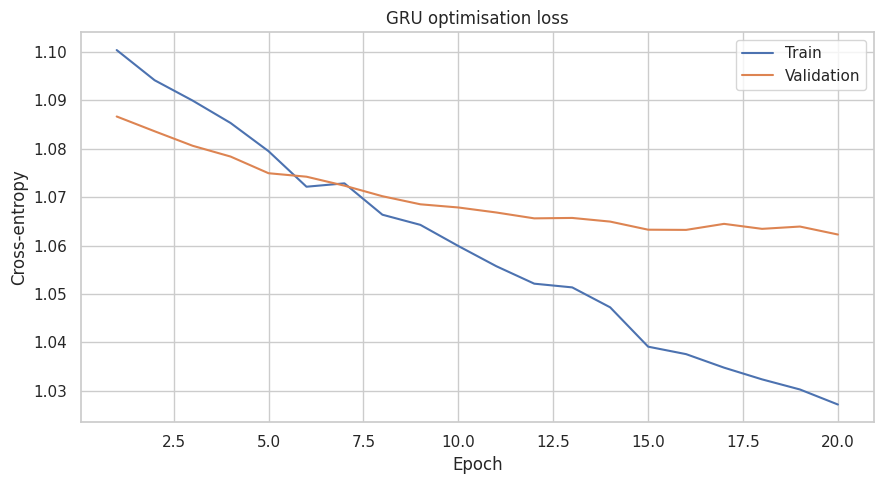

In [ ]:
# 6.4 Figure: GRU train/validation loss (separate from F1 figure)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(best_gru_hist.epoch, best_gru_hist.train_loss, label="Train")
ax.plot(best_gru_hist.epoch, best_gru_hist.val_loss, label="Validation")
ax.legend()
ax.set(title="GRU optimisation loss", xlabel="Epoch", ylabel="Cross-entropy")
plot_finish("32_gru_loss")

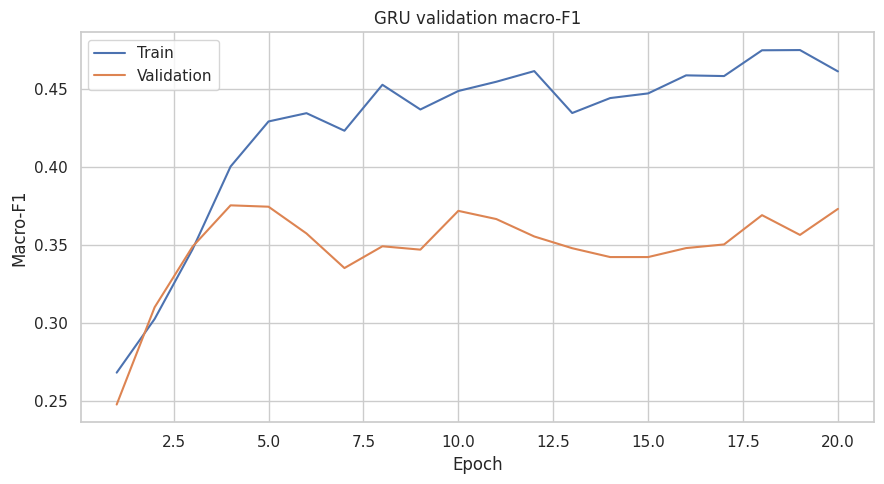

In [ ]:
# 6.5 Figure: GRU train/validation macro-F1
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(best_gru_hist.epoch, best_gru_hist.train_f1, label="Train")
ax.plot(best_gru_hist.epoch, best_gru_hist.val_f1, label="Validation")
ax.legend()
ax.set(title="GRU validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
plot_finish("33_gru_f1")

## 7. ResNet-18: satellite images (optional gated branch)

The DTD images depict storm-scale cloud patterns, **not direct measures of province-level exposure or vulnerability**. The image model is trained with **storm-level images shared across provincial event labels**, so image-only performance has a representational limitation. Never split individual frames from the same storm across folds. ZIP mode uses assumed matches, interpolated landfall cutoffs, and assumed UTC timestamps; it compares all models on the same image-covered cohort. Channel 1 is clipped to 170–300 and scaled to [0, 1] following the [Pyphoon3 V3 benchmark](https://github.com/kitamoto-lab/pyphoon3/blob/main/examples/train_regression.py), then converted to 8-bit RGB for the existing ImageNet transforms.

In [ ]:
# 7.1 Data validation: pre-cutoff manifest and provincial events
if globals().get("USE_ASSUMED_ZIP_IMAGES", False):
    image_meta = zip_manifest[zip_manifest.storm_key.isin(work.storm_key)].copy()
    image_meta["image_path"] = image_meta["archive_member"]
    print("ZIP images:", len(image_meta), "storms:", image_meta.storm_key.nunique())
elif len(manifest):
    image_meta = manifest[manifest.is_pre_cutoff].copy()
    image_meta = image_meta[image_meta.storm_key.isin(work.storm_key)]
    image_meta["exists"] = image_meta.image_path.map(lambda x: Path(str(x)).exists())
    display(
        image_meta.groupby("storm_key")
        .agg(images=("image_path", "size"), available=("exists", "sum"))
        .head()
    )
    image_meta = (
        image_meta[image_meta.exists]
        .sort_values("image_time_utc")
        .groupby("storm_key")
        .tail(CFG["max_images_per_event"])
    )
else:
    image_meta = pd.DataFrame(columns=["storm_key", "image_path"])
READY_IMAGES = (not image_meta.empty) and set(work.storm_key).issubset(
    set(image_meta.storm_key)
)
print("Image model ready for ALL split storms?", READY_IMAGES)
# ⚠️ REVIEW: constrain frame selection to a pre-declared interval, not frames cherry-picked by outcome.

ZIP images: 159 storms: 53
Image model ready for ALL split storms? True


In [ ]:
# 7.2 Image dataset; mandatory storm-level grouping already defined
image_train_tf = transforms.Compose(
    [
        transforms.Resize((CFG["image_size"], CFG["image_size"])),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)
image_eval_tf = transforms.Compose(
    [
        transforms.Resize((CFG["image_size"], CFG["image_size"])),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)


class SatelliteEventDataset(Dataset):
    def __init__(self, df, met, tf):
        self.rows = df.reset_index(drop=True)
        self.tf = tf
        self.paths = met.groupby("storm_key").image_path.apply(list).to_dict()
        assert all(k in self.paths for k in self.rows.storm_key), "Missing storm images"

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows.iloc[i]
        path = self.paths[r.storm_key][i % len(self.paths[r.storm_key])]
        if globals().get("USE_ASSUMED_ZIP_IMAGES", False):
            img = load_event_image(path, self.tf)
        else:
            with Image.open(path) as im:
                img = self.tf(im.convert("RGB"))
        return img, torch.tensor(int(r.target), dtype=torch.long)


class ImageNet(nn.Module):
    def __init__(self, pretrained=True, dropout=0.3):
        super().__init__()
        self.backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT if pretrained else None
        )
        d = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, 3))

    def forward(self, img):
        return self.head(self.backbone(img))

In [ ]:
# 7.3 Optional image training; never fit on invalid / missing manifest
RUN_IMAGE = READY_IMAGES  # default automatically skips if manifest is not complete
image_model = None
image_hist = pd.DataFrame()
if RUN_IMAGE:
    image_tr = DataLoader(
        SatelliteEventDataset(train, image_meta, image_train_tf),
        batch_size=CFG["batch_size"],
        shuffle=True,
        num_workers=2,
    )
    image_va = DataLoader(
        SatelliteEventDataset(val, image_meta, image_eval_tf),
        batch_size=CFG["batch_size"],
        num_workers=2,
    )
    image_te = DataLoader(
        SatelliteEventDataset(test, image_meta, image_eval_tf),
        batch_size=CFG["batch_size"],
        num_workers=2,
    )
    image_model = ImageNet(pretrained=True).to(DEVICE)
    for param in image_model.backbone.parameters():
        param.requires_grad = False
    for param in image_model.backbone.layer4.parameters():
        param.requires_grad = True
    image_model, image_hist = fit_torch(
        image_model, image_tr, image_va, lambda m, b: m(b[0]), "ResNet18", lr=1e-4
    )
else:
    print(
        "SKIPPED image training: provide verified image_manifest.csv covering all split storms."
    )

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 210MB/s]
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


ResNet18 1 {'train_loss': 1.2476536644088638, 'train_f1': 0.40314992956258133, 'val_loss': 1.25007574051214, 'val_f1': 0.24861627969197694}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


ResNet18 2 {'train_loss': 1.021105585398374, 'train_f1': 0.49816143134733615, 'val_loss': 1.2284411591102635, 'val_f1': 0.25070224719101125}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


... (15 outputs left out)

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


ResNet18 11 {'train_loss': 0.9354326816705557, 'train_f1': 0.5392964720843154, 'val_loss': 1.1638686306336348, 'val_f1': 0.32975758476967637}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


ResNet18 12 {'train_loss': 0.94252103025263, 'train_f1': 0.5455637194518111, 'val_loss': 1.155304363949806, 'val_f1': 0.35538684719535785}


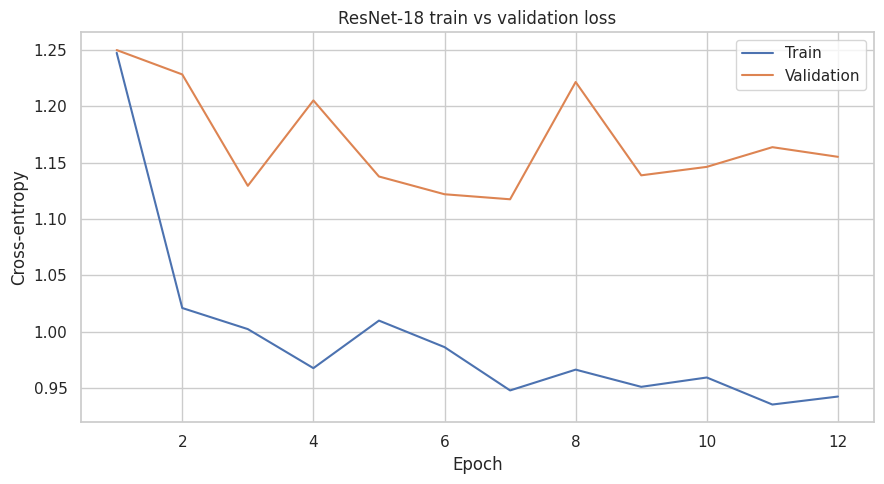

In [ ]:
# 7.4 Figure: ResNet-18 training loss
if len(image_hist):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(image_hist.epoch, image_hist.train_loss, label="Train")
    ax.plot(image_hist.epoch, image_hist.val_loss, label="Validation")
    ax.legend()
    ax.set(
        title="ResNet-18 train vs validation loss",
        xlabel="Epoch",
        ylabel="Cross-entropy",
    )
    plot_finish("34_resnet_loss")
else:
    print("SKIPPED: no DTD image-model training history.")

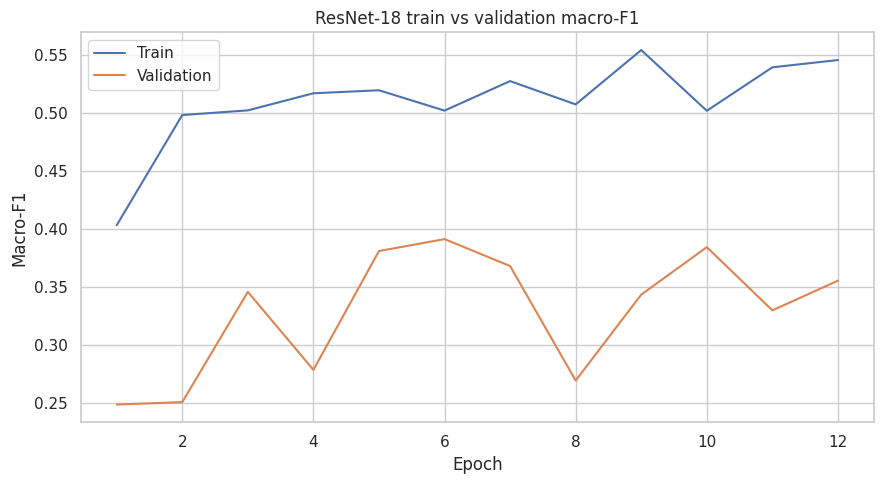

In [ ]:
# 7.5 Figure: ResNet-18 validation F1
if len(image_hist):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(image_hist.epoch, image_hist.train_f1, label="Train")
    ax.plot(image_hist.epoch, image_hist.val_f1, label="Validation")
    ax.legend()
    ax.set(
        title="ResNet-18 train vs validation macro-F1",
        xlabel="Epoch",
        ylabel="Macro-F1",
    )
    plot_finish("35_resnet_f1")
else:
    print("SKIPPED: no DTD image-model training history.")

## 8. Multimodal Fusion: pre-event sequence + satellite embedding + provincial HEV

Late fusion combines three **distinct representations**: GRU sequence embedding, ResNet-18 visual embedding, and an HEV feature vector. To avoid overfitting the multimodal network on a small number of storms, its initial implementation freezes both encoders and trains only a fusion head. A second-stage experiment may unfreeze the last GRU/ResNet block. The fusion model must only be compared on the **common subset** of events with all modalities available.

In [ ]:
# 8.1 Paired fusion dataset and model
# ⚠️ REVIEW: no attempt to impute a missing image with an unrelated cyclone image.
class FusionEventDataset(Dataset):
    def __init__(self, df, met, tf):
        self.rows = df.reset_index(drop=True)
        self.seq, self.length, self.ctx, self.y = collate_table(self.rows)
        self.paths = met.groupby("storm_key").image_path.apply(list).to_dict()
        self.tf = tf
        assert all(k in self.paths for k in self.rows.storm_key)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        k = self.rows.iloc[i].storm_key
        path = self.paths[k][i % len(self.paths[k])]
        if globals().get("USE_ASSUMED_ZIP_IMAGES", False):
            img = load_event_image(path, self.tf)
        else:
            with Image.open(path) as im:
                img = self.tf(im.convert("RGB"))
        return self.seq[i], self.length[i], self.ctx[i], img, self.y[i]


class FusionNet(nn.Module):
    def __init__(self, gru, image, ctx_dim, hidden=128):
        super().__init__()
        self.gru_encoder = gru.gru
        self.image_encoder = image.backbone
        self.head = nn.Sequential(
            nn.Linear(gru.gru.hidden_size + 512 + ctx_dim, hidden),
            nn.ReLU(),
            nn.Dropout(CFG["dropout"]),
            nn.Linear(hidden, 3),
        )
        for p in self.gru_encoder.parameters():
            p.requires_grad = False
        for p in self.image_encoder.parameters():
            p.requires_grad = False

    def forward(self, seq, length, ctx, img):
        pack = nn.utils.rnn.pack_padded_sequence(
            seq, length.cpu(), batch_first=True, enforce_sorted=False
        )
        with torch.no_grad():
            _, hn = self.gru_encoder(pack)
            visual = self.image_encoder(img)
        return self.head(torch.cat([hn[-1], visual, ctx], dim=1))

In [ ]:
# 8.2 Fusion fit and training curves
fusion_model = None
fusion_hist = pd.DataFrame()
for name in (
    "best_tuned_fusion",
    "best_tuned_config",
    "fusion_tuning_table",
    "fusion_tuning_histories",
    "fusion_tuning_complete",
):
    globals().pop(name, None)
if RUN_IMAGE:
    ftr = DataLoader(
        FusionEventDataset(train, image_meta, image_train_tf),
        batch_size=CFG["batch_size"],
        shuffle=True,
        num_workers=2,
    )
    fva = DataLoader(
        FusionEventDataset(val, image_meta, image_eval_tf),
        batch_size=CFG["batch_size"],
        num_workers=2,
    )
    fte = DataLoader(
        FusionEventDataset(test, image_meta, image_eval_tf),
        batch_size=CFG["batch_size"],
        num_workers=2,
    )
    fusion_model = FusionNet(
        best_gru, image_model, len(CTX_FEATURES), CFG["fusion_hidden"]
    ).to(DEVICE)
    fusion_model, fusion_hist = fit_torch(
        fusion_model,
        ftr,
        fva,
        lambda m, b: m(b[0], b[1], b[2], b[3]),
        "Fusion",
        lr=2e-4,
    )
else:
    print("SKIPPED fusion: requires vetted DTD images for all compared storms.")

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion 1 {'train_loss': 1.0528602862691545, 'train_f1': 0.46943729135754886, 'val_loss': 1.0906473943011255, 'val_f1': 0.3485851440551206}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion 2 {'train_loss': 0.9885184423073189, 'train_f1': 0.5024699017008417, 'val_loss': 1.0628490340116337, 'val_f1': 0.399369607702941}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion 3 {'train_loss': 0.9435399633187515, 'train_f1': 0.536380408421589, 'val_loss': 1.1069824684798988, 'val_f1': 0.4366568660876336}


... (4 outputs left out)

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion 6 {'train_loss': 0.9166683300391777, 'train_f1': 0.5394228361491109, 'val_loss': 1.108857461499952, 'val_f1': 0.35564268691956324}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion 7 {'train_loss': 0.8891235952610737, 'train_f1': 0.5714190019535969, 'val_loss': 1.1139376977989577, 'val_f1': 0.42716649191469336}


In [ ]:
# 8.2a Optional fusion fine-tuning: select using validation storms only
fusion_tuning_complete = False
import copy
import json
import random
import numpy as np
import pandas as pd
import torch

if not globals().get("RUN_IMAGE", False) or image_model is None or best_gru is None:
    raise RuntimeError(
        "Run the existing GRU, image, and fusion setup cells before fusion tuning."
    )
if (
    not train_storms.isdisjoint(val_storms)
    or not train_storms.isdisjoint(test_storms)
    or not val_storms.isdisjoint(test_storms)
):
    raise ValueError(
        "Storm groups overlap; rebuild the training and validation split before tuning."
    )


class TunedFusionNet(nn.Module):
    def __init__(self, gru, image, ctx_dim, hidden, dropout, tune_image, tune_gru):
        super().__init__()
        self.gru_encoder = copy.deepcopy(gru.gru)
        self.image_encoder = copy.deepcopy(image.backbone)
        self.tune_image = tune_image
        self.tune_gru = tune_gru
        self.head = nn.Sequential(
            nn.Linear(gru.gru.hidden_size + 512 + ctx_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 3),
        )
        for parameter in self.gru_encoder.parameters():
            parameter.requires_grad = tune_gru
        for parameter in self.image_encoder.parameters():
            parameter.requires_grad = False
        if tune_image:
            for parameter in self.image_encoder.layer4.parameters():
                parameter.requires_grad = True

    def train(self, mode=True):
        super().train(mode)
        if not self.tune_gru:
            self.gru_encoder.eval()
        self.image_encoder.eval()
        if mode and self.tune_image:
            self.image_encoder.layer4.train()
        return self

    def forward(self, seq, length, ctx, img):
        packed = nn.utils.rnn.pack_padded_sequence(
            seq, length.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.gru_encoder(packed)
        visual = self.image_encoder(img)
        return self.head(torch.cat([hidden[-1], visual, ctx], dim=1))


fusion_configs = [
    {"name": "head_only", "tune_image": False, "tune_gru": False, "lr": 0.0002},
    {"name": "image_layer4", "tune_image": True, "tune_gru": False, "lr": 0.0001},
    {"name": "image_layer4_gru", "tune_image": True, "tune_gru": True, "lr": 0.0001},
]
fusion_tuning_results = []
fusion_tuning_histories = []
best_tuned_fusion = None
best_tuned_config = None
best_tuned_val_f1 = -np.inf
for config in fusion_configs:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    candidate = TunedFusionNet(
        best_gru,
        image_model,
        len(CTX_FEATURES),
        CFG["fusion_hidden"],
        CFG["dropout"],
        config["tune_image"],
        config["tune_gru"],
    )
    candidate, history = fit_torch(
        candidate,
        ftr,
        fva,
        lambda model, batch: model(batch[0], batch[1], batch[2], batch[3]),
        f"Fusion_{config['name']}",
        lr=config["lr"],
        epochs=12,
    )
    if history.empty or not np.isfinite(history["val_loss"]).all():
        raise ValueError(
            f"Invalid validation losses in {config['name']}; inspect training output."
        )
    candidate.eval()
    predicted, actual = [], []
    with torch.no_grad():
        for batch in fva:
            batch = [item.to(DEVICE) for item in batch]
            predicted.extend(
                candidate(batch[0], batch[1], batch[2], batch[3])
                .argmax(1)
                .cpu()
                .tolist()
            )
            actual.extend(batch[4].cpu().tolist())
    if len(actual) != len(val) or not np.array_equal(np.asarray(actual), yva):
        raise ValueError("Validation loader labels do not match the validation split.")
    score = f1_score(
        actual, predicted, labels=[0, 1, 2], average="macro", zero_division=0
    )
    fusion_tuning_results.append(
        {
            **config,
            "validation_macro_f1": score,
            "lowest_validation_loss": float(history["val_loss"].min()),
            "epochs_run": len(history),
        }
    )
    fusion_tuning_histories.append(history.assign(config=config["name"]))
    if score > best_tuned_val_f1:
        best_tuned_val_f1 = score
        best_tuned_config = config.copy()
        best_tuned_fusion = candidate

fusion_tuning_table = pd.DataFrame(fusion_tuning_results).sort_values(
    "validation_macro_f1", ascending=False
)
tuning_dir = (
    ROOT / f"fusion_tuning_{pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')}"
)
tuning_dir.mkdir(exist_ok=False)
fusion_tuning_table.to_csv(tuning_dir / "validation_results.csv", index=False)
pd.concat(fusion_tuning_histories, ignore_index=True).to_csv(
    tuning_dir / "training_history.csv", index=False
)
torch.save(
    {
        key: value.detach().cpu()
        for key, value in best_tuned_fusion.state_dict().items()
    },
    tuning_dir / "tuned_fusion_state_dict.pt",
)
with (tuning_dir / "tuning_metadata.json").open("x", encoding="utf-8") as output:
    json.dump(
        {
            "selected_config": best_tuned_config,
            "validation_macro_f1": best_tuned_val_f1,
            "checkpoint_selection": "validation loss with 1e-4 improvement threshold",
            "trial_selection": "validation macro-F1",
            "epochs_limit": 12,
            "seed": SEED,
            "train_storms": sorted(train_storms),
            "validation_storms": sorted(val_storms),
            "ctx_features": CTX_FEATURES,
            "seq_features": list(seq_cols),
            "gru_input_size": best_gru.gru.input_size,
            "gru_hidden_size": best_gru.gru.hidden_size,
            "gru_layers": best_gru.gru.num_layers,
            "image_backbone": "ResNet-18",
            "hidden": CFG["fusion_hidden"],
            "dropout": CFG["dropout"],
            "weight_decay": CFG["weight_decay"],
            "patience": CFG["patience"],
            "assumptions": "closest-track matches, interpolated landfall, assumed UTC timestamps",
            "test_used_for_tuning": False,
            "test_previously_inspected": True,
        },
        output,
        indent=2,
    )
fusion_tuning_complete = True
print("Validation tuning saved to:", tuning_dir)
print(
    "Selected configuration:",
    best_tuned_config,
    "| validation macro-F1:",
    best_tuned_val_f1,
)
print(
    "No test evaluation was run. The previously inspected test split is not an independent final assessment."
)
display(fusion_tuning_table)

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion_head_only 1 {'train_loss': 1.065345825015248, 'train_f1': 0.4253496438421061, 'val_loss': 1.067838036097013, 'val_f1': 0.35960696314429486}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion_head_only 2 {'train_loss': 0.9828735639998963, 'train_f1': 0.5124381520743818, 'val_loss': 1.066382868257583, 'val_f1': 0.37218108044951465}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Fusion_head_only 3 {'train_loss': 0.949522225590019, 'train_f1': 0.5269194584067397, 'val_loss': 1.096843629401194, 'val_f1': 0.3944707330870853}


... (51 outputs left out)

Fusion_image_layer4_gru 11 {'train_loss': 0.8657539149264356, 'train_f1': 0.5868638626208594, 'val_loss': 1.106936024864335, 'val_f1': 0.39258717478892785}


/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Validation tuning saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/fusion_tuning_20261123T160336758709Z
Selected configuration: {'name': 'image_layer4', 'tune_image': True, 'tune_gru': False, 'lr': 0.0001} | validation macro-F1: 0.4216188442928139
No test evaluation was run. The previously inspected test split is not an independent final assessment.


,name,tune_image,tune_gru,lr,validation_macro_f1,lowest_validation_loss,epochs_run
1,image_layer4,True,False,0.0001,0.421619,1.078442,11
2,image_layer4_gru,True,True,0.0001,0.421619,1.075705,11
0,head_only,False,False,0.0002,0.372181,1.066383,7


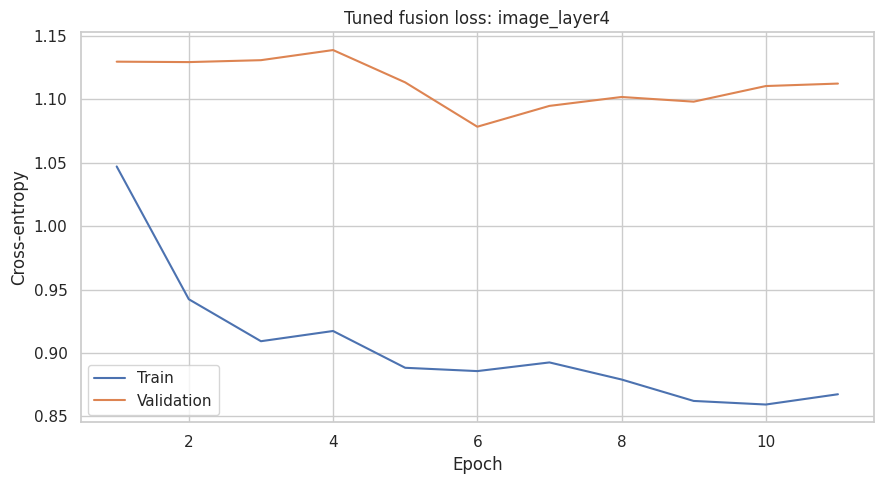

In [ ]:
# 8.3 Figure: selected tuned fusion loss
if RUN_IMAGE:
    if not globals().get("fusion_tuning_complete", False):
        raise RuntimeError(
            "Run fusion tuning (8.2a) before plotting the selected trial."
        )
    selected_fusion_history = pd.concat(fusion_tuning_histories, ignore_index=True)
    selected_fusion_history = selected_fusion_history[
        selected_fusion_history["config"].eq(best_tuned_config["name"])
    ]
    if selected_fusion_history.empty:
        raise ValueError("Selected fusion trial has no training history; rerun 8.2a.")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        selected_fusion_history.epoch, selected_fusion_history.train_loss, label="Train"
    )
    ax.plot(
        selected_fusion_history.epoch,
        selected_fusion_history.val_loss,
        label="Validation",
    )
    ax.legend()
    ax.set(
        title=f"Tuned fusion loss: {best_tuned_config['name']}",
        xlabel="Epoch",
        ylabel="Cross-entropy",
    )
    plot_finish("36_fusion_loss")
else:
    print("SKIPPED: image models are unavailable.")

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Best tuned trial: image_layer4 | validation macro-F1: 0.4216
Original fusion: 0.3994 | improved by 0.0222 macro-F1 (+2.22 percentage points).
Exploratory validation comparison only; the previously inspected test split is not an independent final assessment.


,model,validation_macro_f1,change_vs_original
0,Original fusion,0.399370,0.000000
1,image_layer4,0.421619,0.022249
2,image_layer4_gru,0.421619,0.022249
3,head_only,0.372181,-0.027189


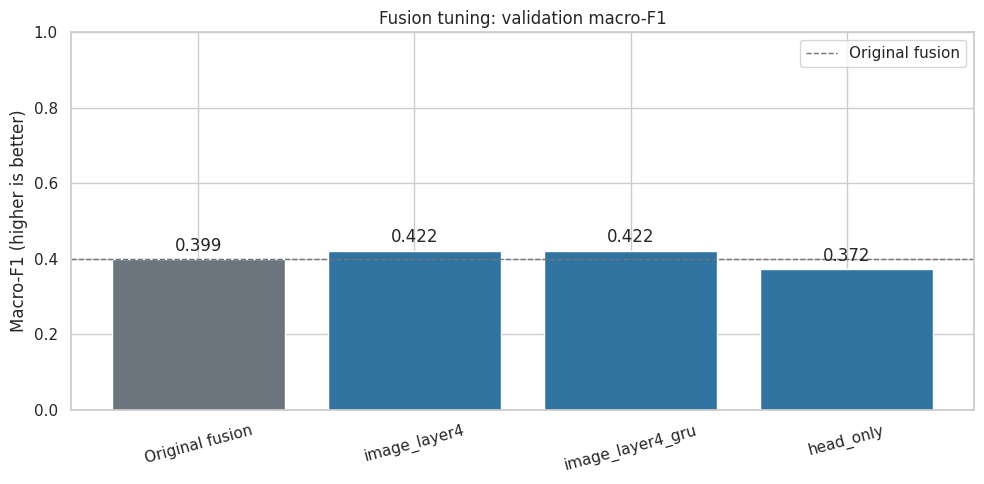

Comparison and graph saved to: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/fusion_tuning_20261123T160336758709Z/validation_comparison_20261123T160341718029Z.csv and /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/fusion_tuning_20261123T160336758709Z/validation_comparison_20261123T160341718029Z.png


In [ ]:
# 8.3a Compare original and tuned fusion on validation storms only
import copy

if fusion_model is None or not globals().get("fusion_tuning_complete", False):
    raise RuntimeError(
        "Run fusion training (8.2) and validation tuning (8.2a) before this comparison."
    )
if not tuning_dir.is_dir():
    raise FileNotFoundError(f"Tuning results directory not found: {tuning_dir}")
if (
    fusion_tuning_table.empty
    or not np.isfinite(fusion_tuning_table["validation_macro_f1"]).all()
):
    raise ValueError("Tuning results are empty or contain invalid validation scores.")

baseline_eval = copy.deepcopy(fusion_model).to(DEVICE).eval()
baseline_predictions, baseline_labels = [], []
with torch.no_grad():
    for batch in fva:
        batch = [item.to(DEVICE) for item in batch]
        baseline_predictions.extend(
            baseline_eval(batch[0], batch[1], batch[2], batch[3])
            .argmax(1)
            .cpu()
            .tolist()
        )
        baseline_labels.extend(batch[4].cpu().tolist())
del baseline_eval
if len(baseline_labels) != len(val) or not np.array_equal(
    np.asarray(baseline_labels), yva
):
    raise ValueError(
        "Validation loader labels do not match the validation split; rerun cells 8.2 and 8.2a."
    )
baseline_f1 = f1_score(
    baseline_labels,
    baseline_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0,
)
comparison = pd.concat(
    [
        pd.DataFrame(
            [{"model": "Original fusion", "validation_macro_f1": baseline_f1}]
        ),
        fusion_tuning_table[["name", "validation_macro_f1"]].rename(
            columns={"name": "model"}
        ),
    ],
    ignore_index=True,
)
comparison["change_vs_original"] = comparison["validation_macro_f1"] - baseline_f1
best_trial = (
    comparison.iloc[1:].sort_values("validation_macro_f1", ascending=False).iloc[0]
)
delta = float(best_trial["change_vs_original"])
outcome = (
    "improved" if delta > 1e-12 else "decreased" if delta < -1e-12 else "unchanged"
)
print(
    f"Best tuned trial: {best_trial['model']} | validation macro-F1: {best_trial['validation_macro_f1']:.4f}"
)
print(
    f"Original fusion: {baseline_f1:.4f} | {outcome} by {abs(delta):.4f} macro-F1 ({delta * 100:+.2f} percentage points)."
)
print(
    "Exploratory validation comparison only; the previously inspected test split is not an independent final assessment."
)
display(comparison)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    comparison["model"],
    comparison["validation_macro_f1"],
    color=["#6c757d", "#3274a1", "#3274a1", "#3274a1"],
)
ax.axhline(
    baseline_f1, color="#6c757d", linestyle="--", linewidth=1, label="Original fusion"
)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(
    title="Fusion tuning: validation macro-F1",
    ylabel="Macro-F1 (higher is better)",
    ylim=(0, 1),
)
ax.tick_params(axis="x", labelrotation=15)
ax.legend()
fig.tight_layout()
comparison_stamp = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
comparison_path = tuning_dir / f"validation_comparison_{comparison_stamp}.csv"
figure_path = tuning_dir / f"validation_comparison_{comparison_stamp}.png"
comparison.to_csv(comparison_path, index=False)
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plot_finish("36a_fusion_tuning_validation")
print("Comparison and graph saved to:", comparison_path, "and", figure_path)

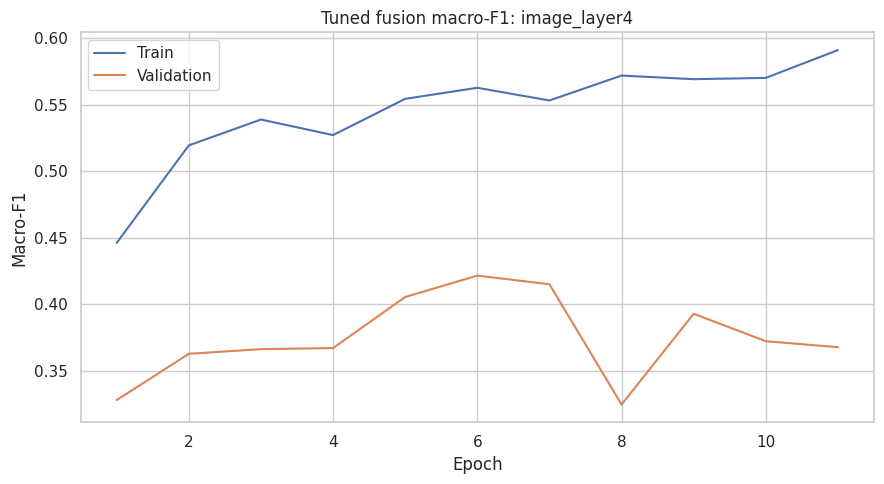

In [ ]:
# 8.4 Figure: selected tuned fusion macro-F1
if RUN_IMAGE:
    if not globals().get("fusion_tuning_complete", False):
        raise RuntimeError(
            "Run fusion tuning (8.2a) before plotting the selected trial."
        )
    selected_fusion_history = pd.concat(fusion_tuning_histories, ignore_index=True)
    selected_fusion_history = selected_fusion_history[
        selected_fusion_history["config"].eq(best_tuned_config["name"])
    ]
    if selected_fusion_history.empty:
        raise ValueError("Selected fusion trial has no training history; rerun 8.2a.")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        selected_fusion_history.epoch, selected_fusion_history.train_f1, label="Train"
    )
    ax.plot(
        selected_fusion_history.epoch,
        selected_fusion_history.val_f1,
        label="Validation",
    )
    ax.legend()
    ax.set(
        title=f"Tuned fusion macro-F1: {best_tuned_config['name']}",
        xlabel="Epoch",
        ylabel="Macro-F1",
    )
    plot_finish("37_fusion_f1")
else:
    print("SKIPPED: image models are unavailable.")

## 9. Held-out evaluation and outcome plots

**Primary metrics:** macro-F1 and balanced accuracy, plus per-class precision/recall/F1, row-normalised confusion matrix, one-vs-rest ROC/PR when statistically meaningful, and reliability diagnostics. Fusion uses the trial selected by validation macro-F1. The test split has previously been inspected, so these results and any test-ranked winner are exploratory, not an independent final assessment. Results represent retrospective labels derived from outcomes, not operational casualty forecasts. Uncertainty should be estimated with storm-level bootstrap intervals rather than row-level bootstrap.

In [ ]:
# 9.1 Predictions for held-out storm test — all models share same rows if image-ready
def prob_generic(model, loader, fn):
    model.to(DEVICE).eval()
    z = []
    with torch.no_grad():
        for batch in loader:
            batch = [a.to(DEVICE) for a in batch]
            z.append(torch.softmax(fn(model, batch), 1).cpu().numpy())
    return np.concatenate(z)


if RUN_IMAGE and not globals().get("fusion_tuning_complete", False):
    raise RuntimeError(
        "Run fusion tuning (8.2a) before evaluating the selected tuned model."
    )
best_gru.to(DEVICE)
probas = {
    "XGBoost": best_xgb.predict_proba(Xte),
    "GRU": predict_gru(best_gru, te_loader),
}
if RUN_IMAGE:
    probas["ResNet-18"] = prob_generic(image_model, image_te, lambda m, b: m(b[0]))
    probas["Fusion (tuned)"] = prob_generic(
        best_tuned_fusion, fte, lambda m, b: m(b[0], b[1], b[2], b[3])
    )
    print(
        "Evaluating validation-selected fusion:",
        best_tuned_config["name"],
        "(exploratory: test previously inspected)",
    )
for k, v in probas.items():
    assert v.shape == (len(test), 3), (k, v.shape)

/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))
/tmp/ipykernel_497/1033212150.py:171: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return transform(Image.fromarray(pixels, mode="L").convert("RGB"))


Evaluating validation-selected fusion: image_layer4 (exploratory: test previously inspected)


In [ ]:
# 9.2 Test table: metrics and human-readable classification reports
reports = []
for name, pr in probas.items():
    pred = pr.argmax(axis=1)
    reports.append(
        {
            "model": name,
            "accuracy": accuracy_score(yte, pred),
            "balanced_accuracy": balanced_accuracy_score(yte, pred),
            "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "weighted_f1": f1_score(yte, pred, average="weighted", zero_division=0),
        }
    )
    print(
        "\n",
        name,
        "\n",
        classification_report(
            yte, pred, labels=[0, 1, 2], target_names=CLASSES, zero_division=0
        ),
    )
metrics = pd.DataFrame(reports).sort_values("macro_f1", ascending=False)
display(metrics)
metrics.to_csv(OUT / "model_test_metrics.csv", index=False)


 XGBoost 
               precision    recall  f1-score   support

         Low       0.23      0.43      0.30        42
    Moderate       0.14      0.12      0.13        50
        High       0.60      0.43      0.50        94

    accuracy                           0.34       186
   macro avg       0.32      0.32      0.31       186
weighted avg       0.39      0.34      0.35       186


 GRU 
               precision    recall  f1-score   support

         Low       0.32      0.45      0.38        42
    Moderate       0.29      0.28      0.28        50
        High       0.65      0.54      0.59        94

    accuracy                           0.45       186
   macro avg       0.42      0.42      0.42       186
weighted avg       0.48      0.45      0.46       186


 ResNet-18 
               precision    recall  f1-score   support

         Low       0.30      0.67      0.42        42
    Moderate       0.30      0.56      0.39        50
        High       0.00      0.00      0.

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
1,GRU,0.451613,0.424978,0.417363,0.460686
3,Fusion (tuned),0.360215,0.428592,0.357269,0.338752
0,XGBoost,0.344086,0.324701,0.309950,0.354493
2,ResNet-18,0.301075,0.408889,0.268933,0.198907


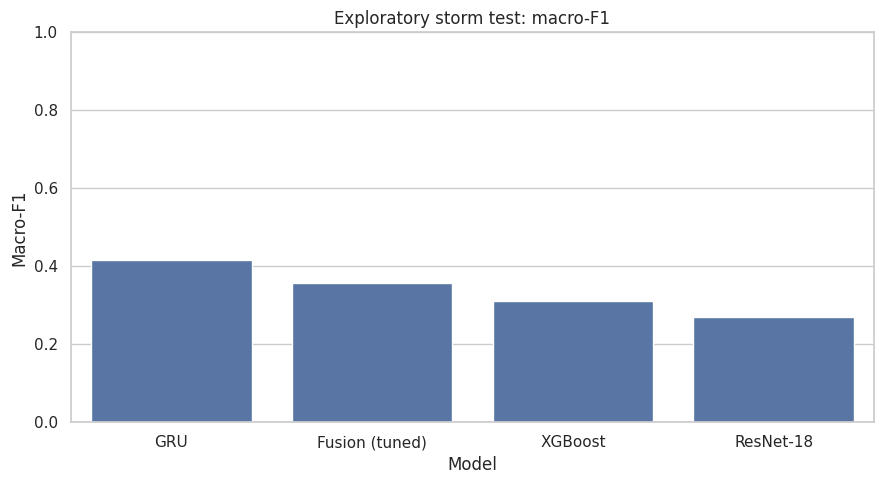

In [ ]:
# 9.3 Figure: held-out macro-F1 by model
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=metrics, x="model", y="macro_f1", ax=ax)
ax.set(
    ylim=(0, 1),
    title="Exploratory storm test: macro-F1",
    xlabel="Model",
    ylabel="Macro-F1",
)
plot_finish("38_models_macro_f1")

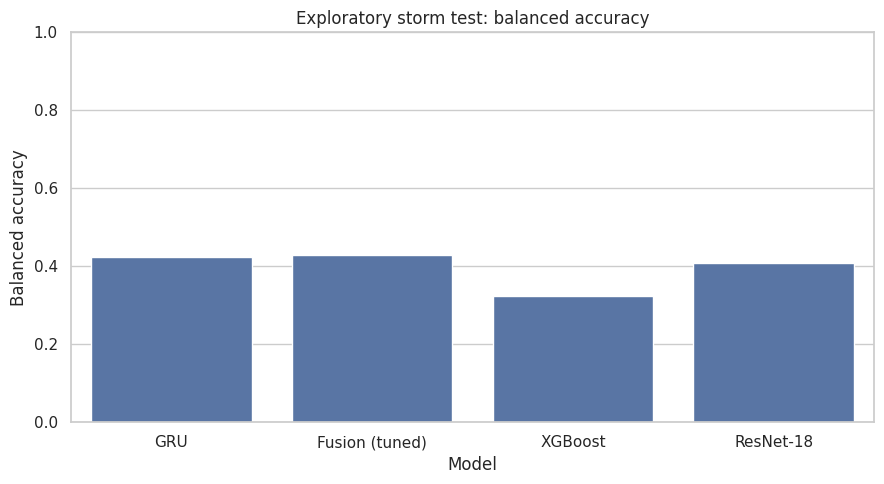

In [ ]:
# 9.4 Figure: held-out balanced accuracy
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=metrics, x="model", y="balanced_accuracy", ax=ax)
ax.set(
    ylim=(0, 1),
    title="Exploratory storm test: balanced accuracy",
    xlabel="Model",
    ylabel="Balanced accuracy",
)
plot_finish("39_models_balanced_accuracy")

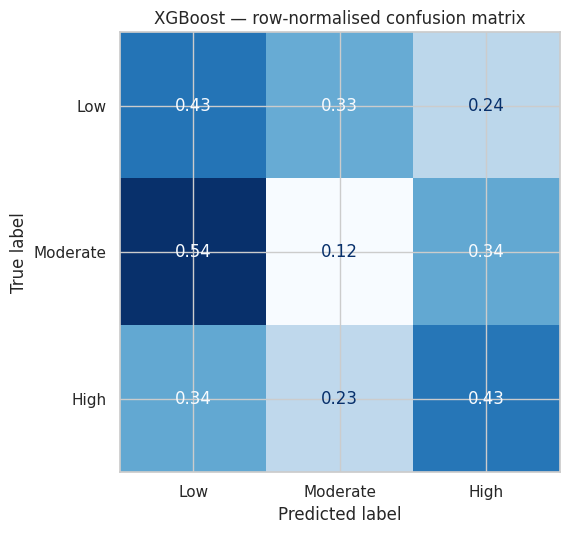

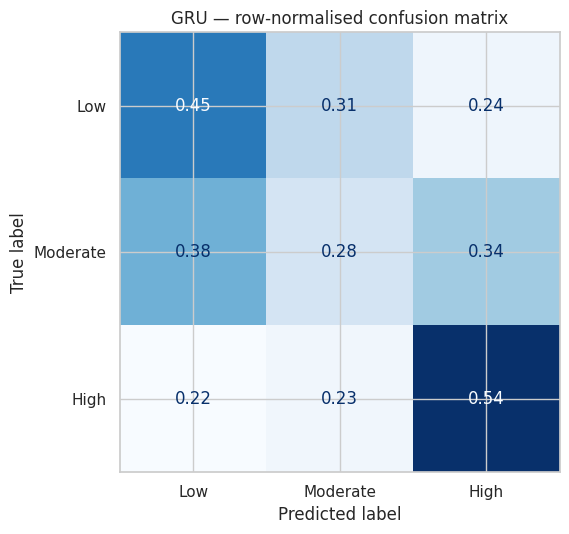

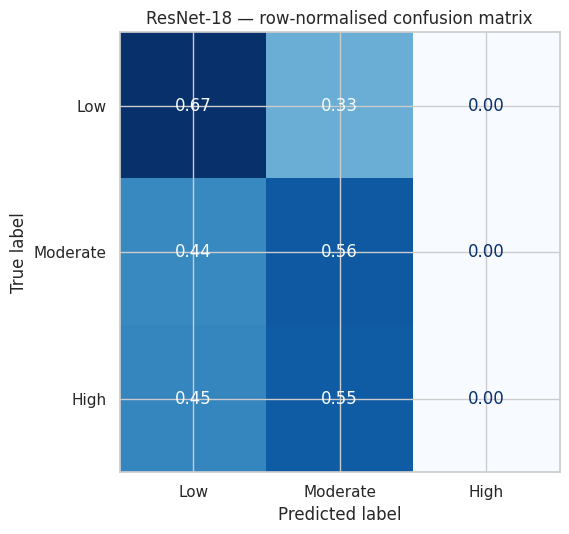

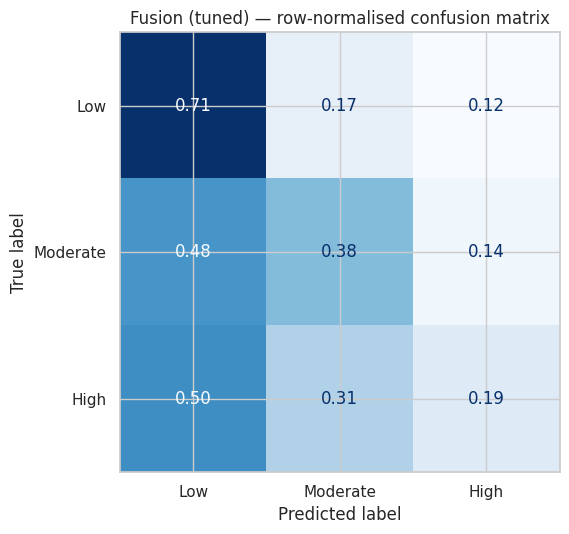

In [ ]:
# 9.5 Individual confusion matrix per model (one plot per output)
for name, prob in probas.items():
    cm = confusion_matrix(yte, prob.argmax(axis=1), labels=[0, 1, 2], normalize="true")
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False
    )
    ax.set(title=f"{name} — row-normalised confusion matrix")
    plot_finish("40_confusion_" + name.lower().replace(" ", "_"))

,model,class,recall,precision,f1,support
0,XGBoost,Low,0.428571,0.233766,0.302521,42
1,XGBoost,Moderate,0.120000,0.142857,0.130435,50
2,XGBoost,High,0.425532,0.597015,0.496894,94
3,GRU,Low,0.452381,0.322034,0.376238,42
4,GRU,Moderate,0.280000,0.285714,0.282828,50
5,GRU,High,0.542553,0.653846,0.593023,94
6,ResNet-18,Low,0.666667,0.304348,0.417910,42
7,ResNet-18,Moderate,0.560000,0.297872,0.388889,50
8,ResNet-18,High,0.000000,0.000000,0.000000,94
9,Fusion (tuned),Low,0.714286,0.297030,0.419580,42


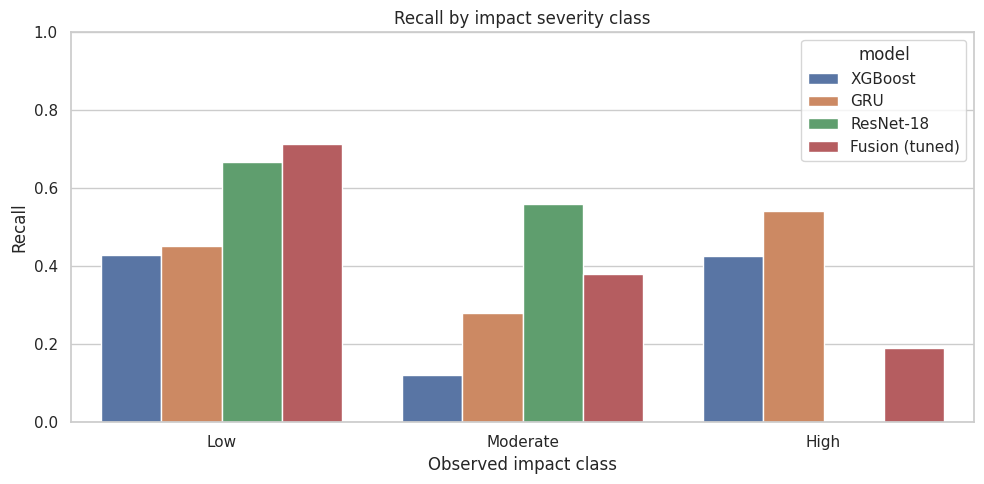

In [ ]:
# 9.6 Figure: per-class recall by model
rows = []
for name, prob in probas.items():
    prec, rec, f1, s = precision_recall_fscore_support(
        yte, prob.argmax(1), labels=[0, 1, 2], zero_division=0
    )
    for i in range(3):
        rows.append(
            {
                "model": name,
                "class": CLASSES[i],
                "recall": rec[i],
                "precision": prec[i],
                "f1": f1[i],
                "support": s[i],
            }
        )
perclass = pd.DataFrame(rows)
display(perclass)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=perclass, x="class", y="recall", hue="model", ax=ax)
ax.set(
    ylim=(0, 1),
    title="Recall by impact severity class",
    xlabel="Observed impact class",
    ylabel="Recall",
)
plot_finish("41_class_recall")

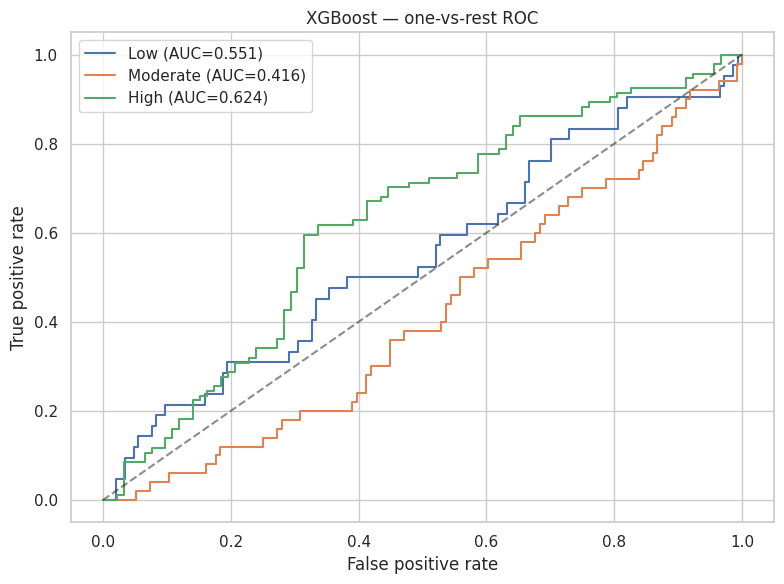

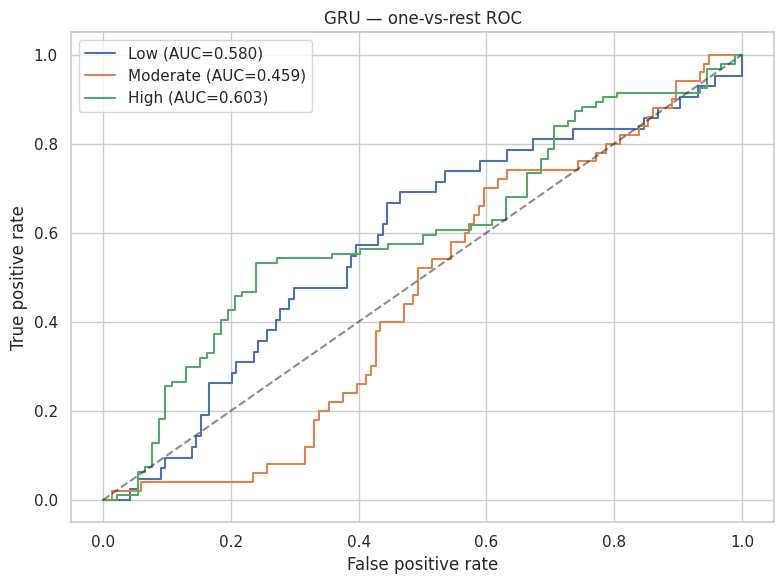

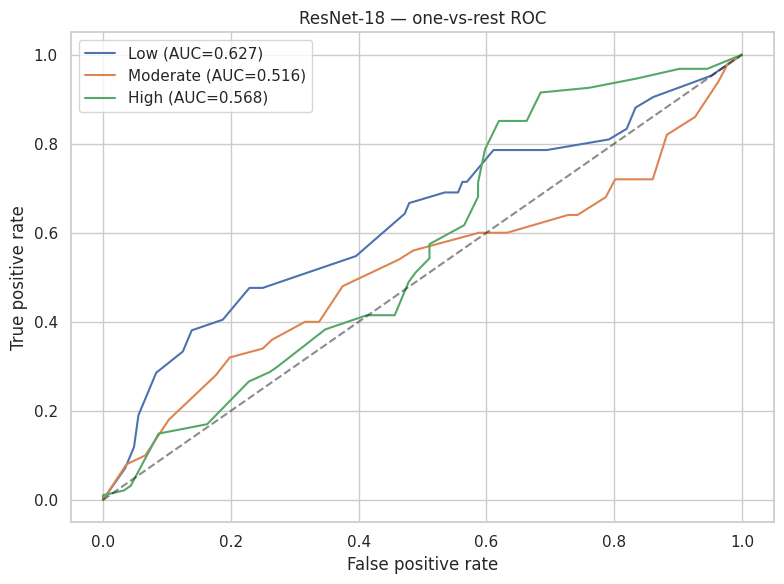

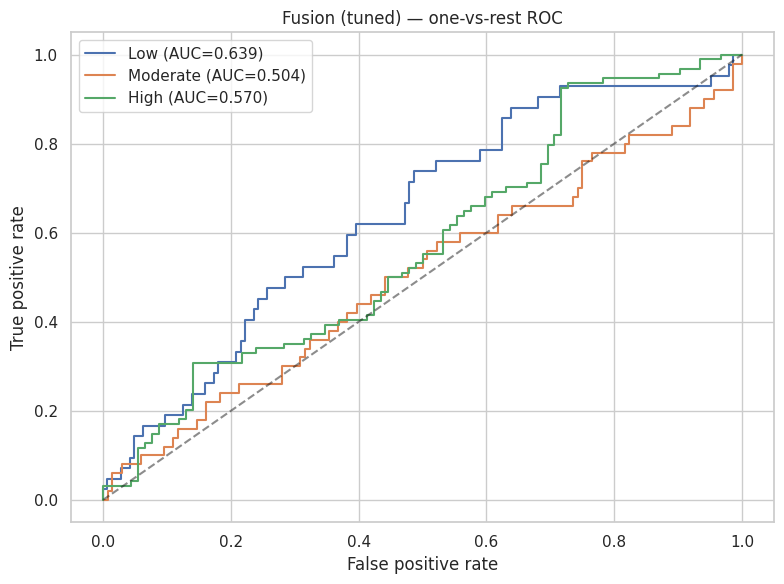

In [ ]:
# 9.7 Figure: one-vs-rest ROC (one output per model)
from sklearn.preprocessing import label_binarize

Y = label_binarize(yte, classes=[0, 1, 2])
for name, prob in probas.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    drawn = False
    for i, cl in enumerate(CLASSES):
        if len(np.unique(Y[:, i])) < 2:
            continue
        fpr, tpr, _ = roc_curve(Y[:, i], prob[:, i])
        au = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{cl} (AUC={au:.3f})")
        drawn = True
    if drawn:
        ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
        ax.legend()
        ax.set(
            title=f"{name} — one-vs-rest ROC",
            xlabel="False positive rate",
            ylabel="True positive rate",
        )
        plot_finish("42_roc_" + name.lower().replace(" ", "_"))
    else:
        plt.close(fig)
        print("ROC skipped:", name, "test has no class variation.")

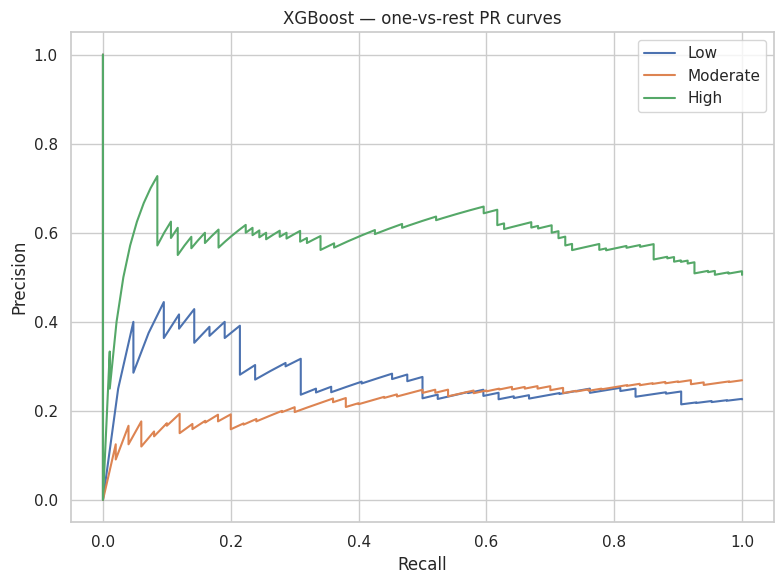

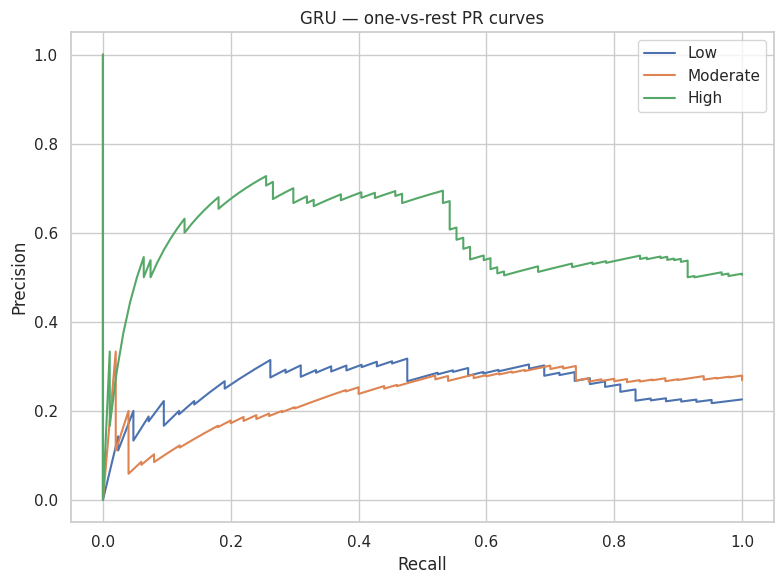

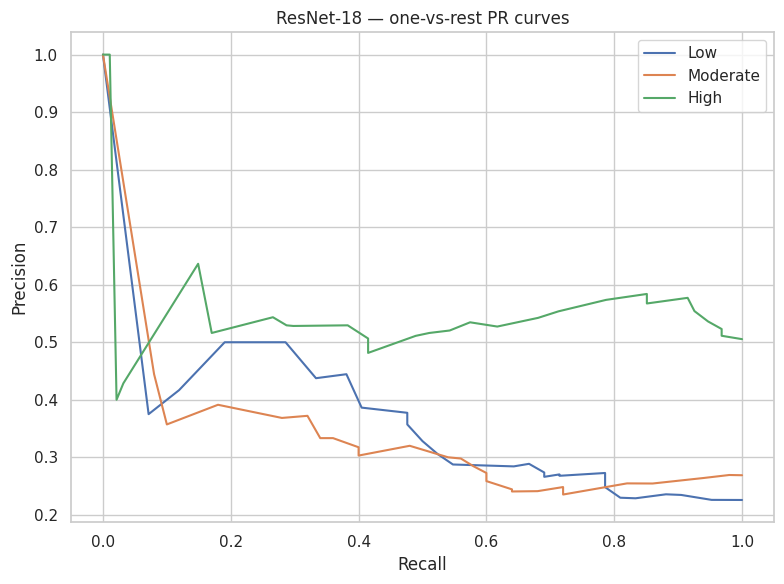

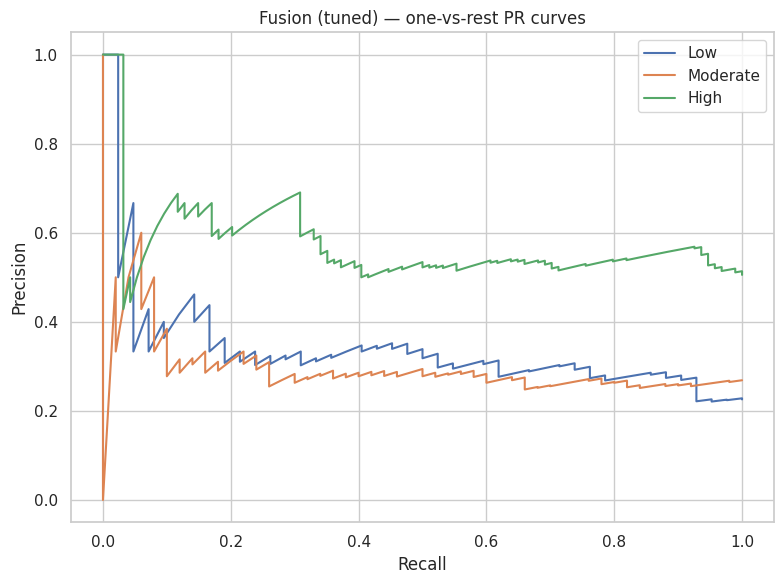

In [ ]:
# 9.8 Figure: one-vs-rest precision-recall curves per model
for name, prob in probas.items():
    fig, ax = plt.subplots(figsize=(8, 6))
    drawn = False
    for i, cl in enumerate(CLASSES):
        if len(np.unique(Y[:, i])) < 2:
            continue
        prec, rec, _ = precision_recall_curve(Y[:, i], prob[:, i])
        ax.plot(rec, prec, label=cl)
        drawn = True
    if drawn:
        ax.legend()
        ax.set(
            title=f"{name} — one-vs-rest PR curves", xlabel="Recall", ylabel="Precision"
        )
        plot_finish("43_pr_" + name.lower().replace(" ", "_"))
    else:
        plt.close(fig)
        print("PR skipped:", name)

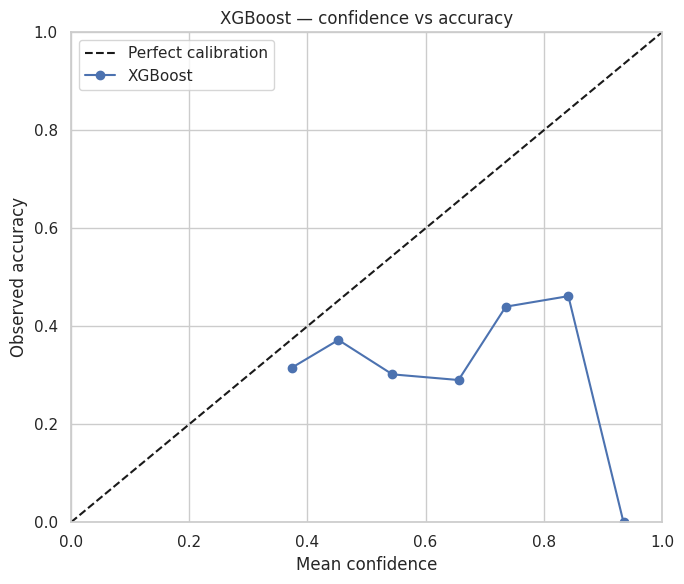

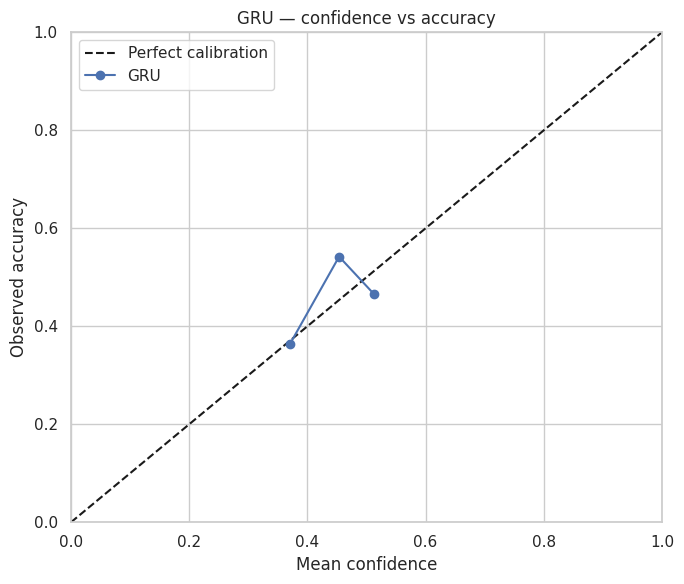

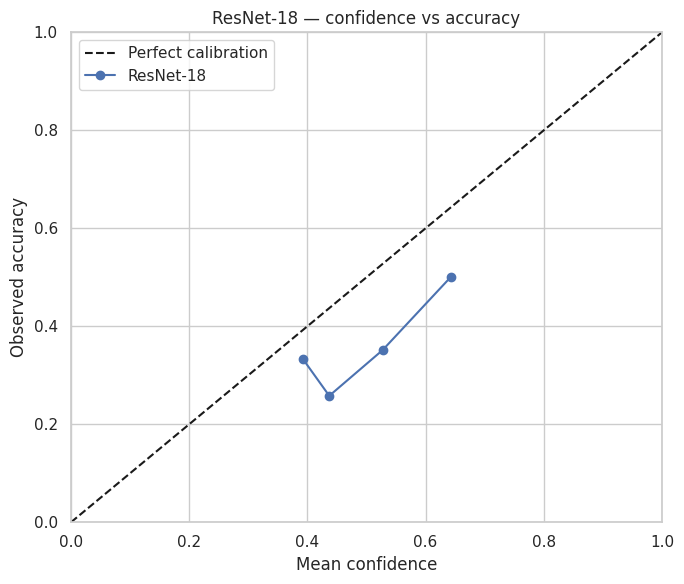

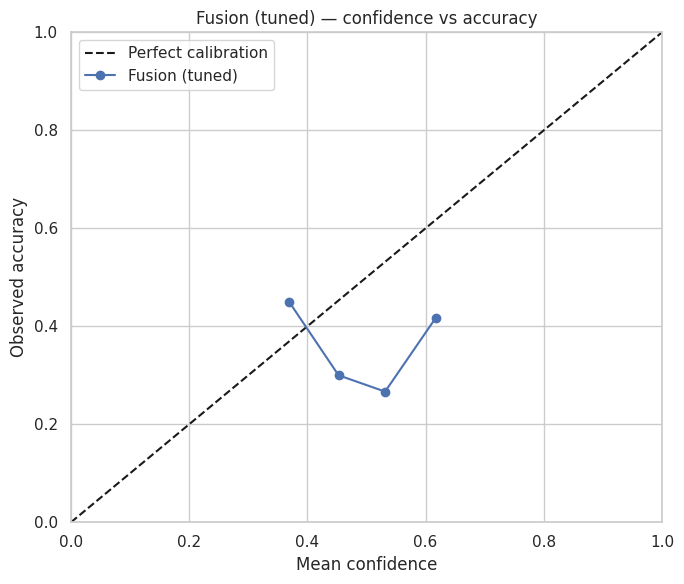

In [ ]:
# 9.9 Figure: confidence calibration diagnostic per model
for name, prob in probas.items():
    conf = prob.max(axis=1)
    correct = (prob.argmax(axis=1) == yte).astype(float)
    tmp = pd.DataFrame({"confidence": conf, "correct": correct})
    tmp["bin"] = pd.cut(tmp.confidence, bins=np.linspace(0, 1, 11), include_lowest=True)
    agg = (
        tmp.groupby("bin", observed=False)
        .agg(confidence=("confidence", "mean"), accuracy=("correct", "mean"))
        .dropna()
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    ax.plot(agg.confidence, agg.accuracy, "o-", label=name)
    ax.set(
        xlim=(0, 1),
        ylim=(0, 1),
        title=f"{name} — confidence vs accuracy",
        xlabel="Mean confidence",
        ylabel="Observed accuracy",
    )
    ax.legend()
    plot_finish("44_calibration_" + name.lower().replace(" ", "_"))

In [ ]:
# 9.10 Error-analysis table with province / storm references
winner = metrics.iloc[0]["model"]
winprob = probas[winner]
errors = test[
    ["event_id", "storm_key", "province", "year", "target", "impact_score", "split"]
].copy()
errors["predicted"] = winprob.argmax(1)
errors["confidence"] = winprob.max(1)
errors["correct"] = errors.target.eq(errors.predicted)
errors = errors.sort_values(["correct", "confidence"], ascending=[True, False])
display(errors.head(25))
errors.to_csv(OUT / "test_error_analysis.csv", index=False)

,event_id,storm_key,province,year,target,impact_score,split,predicted,confidence,correct
314,haiyan_2013__bukidnon,haiyan_2013,Bukidnon,2013,0,0.454108,test,2,0.533026,False
318,haiyan_2013__davao de oro,haiyan_2013,Davao de Oro,2013,0,0.507430,test,2,0.529242,False
322,haiyan_2013__agusan del sur,haiyan_2013,Agusan del Sur,2013,1,0.535839,test,2,0.528531,False
320,haiyan_2013__davao oriental,haiyan_2013,Davao Oriental,2013,1,0.550262,test,2,0.521164,False
321,haiyan_2013__agusan del norte,haiyan_2013,Agusan del Norte,2013,1,0.607955,test,2,0.516415,False
965,vamco_2020__mountain province,vamco_2020,Mountain Province,2020,1,0.643794,test,0,0.504419,False
317,haiyan_2013__misamis oriental,haiyan_2013,Misamis Oriental,2013,1,0.572115,test,2,0.501826,False
316,haiyan_2013__lanao del norte,haiyan_2013,Lanao del Norte,2013,0,0.483829,test,2,0.500202,False
949,vamco_2020__apayao,vamco_2020,Apayao,2020,1,0.517483,test,0,0.499195,False
319,haiyan_2013__davao del sur,haiyan_2013,Davao del Sur,2013,0,0.440122,test,2,0.493045,False


Storm-clustered macro-F1 95% bootstrap percentile interval: [0.23207317 0.40711643 0.52164102]


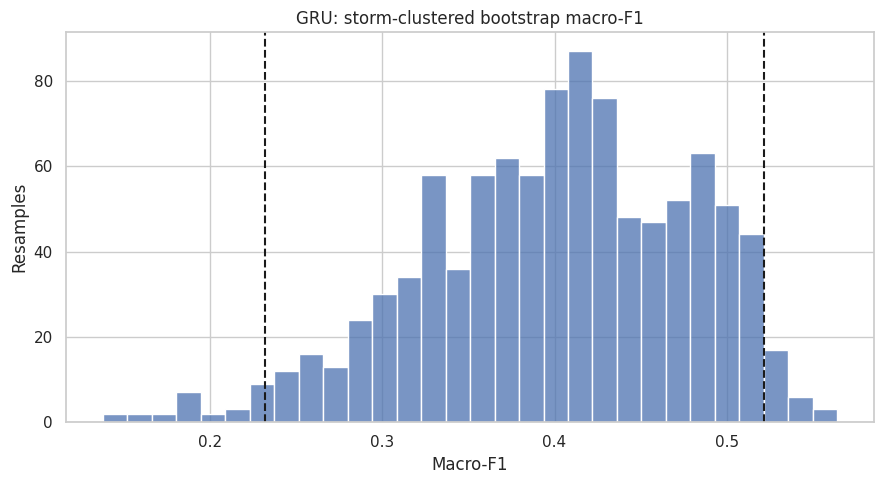

In [ ]:
# 9.11 Storm-level bootstrap confidence interval for macro-F1
# ⚠️ REVIEW: resample independent storm clusters (not provincial records).
boot = []
storms = test.storm_key.unique()
rng = np.random.default_rng(SEED)
for _ in range(1000):
    chosen = rng.choice(storms, size=len(storms), replace=True)
    indices = np.concatenate(
        [np.where(test.storm_key.to_numpy() == s)[0] for s in chosen]
    )
    boot.append(
        f1_score(
            yte[indices],
            winprob.argmax(1)[indices],
            average="macro",
            labels=[0, 1, 2],
            zero_division=0,
        )
    )
interval = np.quantile(boot, [0.025, 0.5, 0.975])
print("Storm-clustered macro-F1 95% bootstrap percentile interval:", interval)
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(boot, ax=ax, bins=30)
ax.axvline(interval[0], linestyle="--", color="k")
ax.axvline(interval[2], linestyle="--", color="k")
ax.set(
    title=f"{winner}: storm-clustered bootstrap macro-F1",
    xlabel="Macro-F1",
    ylabel="Resamples",
)
plot_finish("45_macro_f1_uncertainty")

## 10. Explainability, sensitivity, and export

**Limitations to discuss:** impact reporting gaps, possible selection bias toward affected provinces, small independent storm count, nominal money across years, incomplete province vulnerability history, mismatched spatial scales (storm cloud vs province), imperfect forecast anchors, class thresholds fitted from training outcome percentiles, and operational uncertainty. A high score does not establish causality or disaster-readiness.

**Proposed robustness checks:** alternative storm-group seeds, chronological storm holdout, two vs three class label construction, per-capita outcomes, CPI-deflated economic loss, alternate HEV weights, imputed vs missing population, optional POWER/terrain features, frozen vs fine-tuned ResNet, image-frame aggregation, and early vs late fusion.

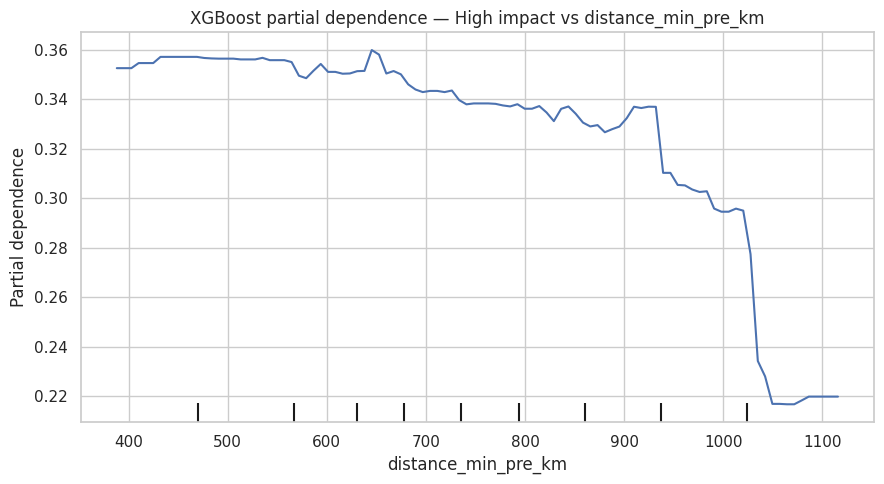

In [ ]:
# 10.1 Figure: partial dependence (one feature, XGBoost only)
from sklearn.inspection import PartialDependenceDisplay

PDP_FEATURE = "distance_min_pre_km"
if PDP_FEATURE in FEATURES:
    fig, ax = plt.subplots(figsize=(9, 5))
    PartialDependenceDisplay.from_estimator(
        best_xgb, Xtr, features=[PDP_FEATURE], target=2, ax=ax
    )
    ax.set_title(f"XGBoost partial dependence — High impact vs {PDP_FEATURE}")
    plot_finish("46_xgb_partial_dependence")

In [ ]:
# 10.2 Save reproducibility artifacts and model checkpoints
if RUN_IMAGE and not globals().get("fusion_tuning_complete", False):
    raise RuntimeError(
        "Run fusion tuning (8.2a) before exporting the selected tuned model."
    )
joblib.dump(best_xgb, OUT / "xgboost_model.joblib")
joblib.dump(
    {
        "seq_imputer": seq_imputer,
        "seq_scaler": seq_scaler,
        "ctx_imputer": ctx_imputer,
        "ctx_scaler": ctx_scaler,
        "features": FEATURES,
        "ctx_features": CTX_FEATURES,
        "ib_features": IB_FEATURES,
    },
    OUT / "transformers.joblib",
)
torch.save(best_gru.cpu().state_dict(), OUT / "gru_state_dict.pt")
if image_model is not None:
    torch.save(image_model.cpu().state_dict(), OUT / "resnet18_state_dict.pt")
if fusion_model is not None:
    torch.save(fusion_model.cpu().state_dict(), OUT / "fusion_state_dict.pt")
if RUN_IMAGE:
    torch.save(
        {k: v.detach().cpu() for k, v in best_tuned_fusion.state_dict().items()},
        OUT / "fusion_tuned_state_dict.pt",
    )
work.to_csv(OUT / "supervised_event_features_labels.csv", index=False)
xgb_tuning.to_csv(OUT / "xgb_tuning_results.csv", index=False)
pd.DataFrame(gru_trials).to_csv(OUT / "gru_tuning_results.csv", index=False)
with open(OUT / "experiment_metadata.json", "w") as f:
    json.dump(
        {
            "seed": SEED,
            "config": CFG,
            "label_meta": label_meta,
            "features": FEATURES,
            "train_storms": sorted(train_storms),
            "val_storms": sorted(val_storms),
            "test_storms": sorted(test_storms),
            "fusion_tuned_config": best_tuned_config if RUN_IMAGE else None,
            "context_features": CTX_FEATURES,
            "weather_features": WEATHER_FEATURES,
            "terrain_features": TERRAIN_FEATURES,
            "poverty_features": POVERTY_FEATURES,
            "housing_features": HOUSING_FEATURES,
            "housing_source_sha256": housing_source_hash,
            "housing_summary_sha256": housing_table_hash,
            "housing_geographic_proxy": {
                "davao occidental": "davao del sur (combined Davao del Sur–Davao Occidental summary)"
            },
            "feature_provenance": "NASA POWER reanalysis, three complete LST days before the UTC cutoff date; Copernicus terrain, updated PSA poverty and 2020 census housing are retrospective proxies. Poverty uses 2015 for 2010–2017 and 2018 for 2018–2020. Housing uses the 2020 municipality-based census summary for all storm years; it can reflect post-storm reconstruction.",
            "test_previously_inspected": True,
            "versions": {"torch": torch.__version__, "xgboost": xgb.__version__},
        },
        f,
        indent=2,
        default=str,
    )
print("Saved to", OUT)

Saved to /content/typhoon_research_outputs


In [ ]:
# 10.3 Package plots and metrics for viva & paper
archive = shutil.make_archive(str(OUT.parent / "typhoon_research_results"), "zip", OUT)
print("ZIP:", archive)
if IN_COLAB:
    from google.colab import files

    files.download(archive)

ZIP: /content/typhoon_research_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from datetime import datetime, timezone
import shutil

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
destination = ROOT / f"typhoon_research_results_{stamp}.zip"
shutil.copy2("/content/typhoon_research_results.zip", destination)
print("Saved to Drive:", destination)

Saved to Drive: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/typhoon_research_results_20261123T160420Z.zip
